# Tiềm năng tăng trưởng shop – BI10 Round 3

> **Bước 5/5 · Tiềm năng, nguyên nhân, ưu tiên và kiểm chứng – trả lời câu hỏi trung tâm** · bản đồ toàn bài: `README.md`
>
> **Câu hỏi của đề được trả lời ở đây:**
> - **Attainable Potential** (Bước 5) và **Addressable Market Ceiling** (Bước 6)
> - *"If two shops have similar current sales, how can we determine whether one has significant room to grow?"* (Bước 7)
> - What factors create or constrain the opportunity gap – demand, execution, staffing, merchant, product mix, risk (Bước 5, 7)
> - How shops should be prioritized when sales resources are limited (Bước 8)
> - Reliability and uncertainty of the estimates; how recommendations could be validated in practice (Bước 9)
> - Tổng hợp trả lời toàn bộ đề (cuối notebook)
>
> **Đầu vào → đầu ra:** `data_clean/` + `data_external/` + `output/bau_2026Q4.csv` → `output/shop_potential_2026Q3.csv`, `output/tra_loi_de_bai.csv`
>
> **Đọc tiếp:** — (kết thúc; xem `README.md` cho bản đồ toàn bài)

**Đề hỏi:** *Một shop cụ thể thực tế có thể tăng trưởng đến đâu, điều gì đang giới hạn nó, và Ban quản lý bán hàng nên làm gì?*
Câu hỏi trung tâm: *hai shop doanh số như nhau, làm sao biết shop nào còn dư địa?*

Notebook đi theo 9 bước. Mỗi bước gồm **Câu hỏi → Cách làm → Kết quả → Trả lời**.

| Bước | Câu hỏi |
|---|---|
| 0 | Shop được phân loại thế nào? Nhãn có cho biết shop lớn hay nhỏ không? |
| 1 | Đo cái gì, ở thời điểm nào, cho shop nào? |
| 2 | Mỗi shop có những thông tin gì? |
| 3 | **Current Actual**: shop đang đạt bao nhiêu? |
| 4 | **Business-as-Usual**: nếu giữ nguyên, quý tới đạt bao nhiêu? |
| 5 | **Attainable Potential**: nếu can thiệp khả thi, đạt được bao nhiêu? |
| 6 | **Addressable Market Ceiling**: thị trường cho phép tối đa bao nhiêu? |
| 7 | Khoảng cách bao nhiêu, vì sao? Hai shop bán như nhau khác nhau ở đâu? |
| 8 | Shop nào nên nhận thêm nguồn lực, được bao nhiêu, làm gì? |
| 9 | Kết quả có đáng tin không, kiểm chứng thế nào? |

Code nằm ngay trong notebook (Phần code, ngay dưới đây) · kết quả từng shop: `output/shop_potential_2026Q3.csv`.

## Phần code: pipeline tính 4 mức tiềm năng
Toàn bộ hàm dùng ở các bước bên dưới (phải chạy trước). **Người đọc kết quả bỏ qua phần này**, đi thẳng tới **Bước 0**. Đọc phần kết quả thì có thể bỏ qua phần này và xem từ **Bước 0**.

**Quy ước và quy tắc nghiệp vụ:**

Pipeline tiềm năng tăng trưởng shop – BI10 Round 3.

Dùng từ notebook `05_Potential_Prioritization.ipynb`:
    base = load_base()                 # đọc data_clean/, data_external/, nhãn Round 2 (1 lần)
    res  = run(base, asof=Q(2026, 3))  # 4 mức tiềm năng + nguyên nhân + tier cho mọi shop

`run` nhận một quý làm mốc "hiện tại" và chỉ dùng dữ liệu đến hết quý đó (trừ cờ trễ hạn), nên chạy lại với
asof = Q(2026, 1) là backtest ngoài thời gian.

Quy ước (xem CHECKLIST_Round3.md):
- HĐ ký = is_signed và không bị huỷ sau ký; đếm theo **quý nộp hồ sơ** (cohort) để phễu khớp đúng:
  ký = hồ sơ × tỷ lệ duyệt × tỷ lệ chốt sau duyệt.
- Góc Origination: HĐ ký ở kênh online / shop ngoài phạm vi có lead (không RTDM) từ shop vật lý → chuyển về shop đó.
- Mọi mức tiềm năng tính theo tháng của quý kế tiếp (asof + 1), đo cả **HĐ ký** và **giải ngân điều chỉnh rủi ro**
  (giải ngân × (1 − FPD)).
- BAU tại mốc 2026Q3 lấy từ `output/bau_2026Q4.csv` (M12 của 04_BAU.ipynb) + HĐ online do lead của shop; các mốc backtest khác
  dùng BAU đơn giản (hiện tại × tuổi × P(còn hoạt động)).
- Attainable = BAU + phần khoảng cách so với P75 peer mà shop đóng được trong 1 quý, theo **tỷ lệ đóng khoảng cách đã thấy
  trong lịch sử** (phần vượt mức thông thường; kịch bản thấp / giữa / cao). Mức P75 chỉ là **dư địa tham chiếu**.

Quy tắc nghiệp vụ:
1. Xếp ưu tiên theo giá trị (giải ngân điều chỉnh rủi ro), báo cáo song song số HĐ.
2. Phân trạng thái trước: Mới mở / Không hoạt động (0 HĐ cả quý → kích hoạt lại hoặc rút) / Đang hoạt động.
3. Câu hỏi trung tâm: ma trận mức doanh số hiện tại × dư địa (gần trần / vừa / lớn, ngưỡng HĐ tuyệt đối).
4. Dư địa tách theo đòn bẩy: chốt sau duyệt · lượng hồ sơ · sản phẩm còn thiếu so với peer; hành động khác nhau cho Aldi
   (nhân viên đối tác làm hồ sơ) và Non-Aldi (SA của Home Credit). Tỷ lệ duyệt giữ theo shop (không nới chính sách).
5. Trần shop = trần tỉnh chia theo năng lực cấu trúc (peer, chuỗi đại lý, tuổi đại lý, giá trị đơn hàng);
   mục tiêu hồ sơ điều chỉnh theo quy mô đối tác so với peer.
6. Nhân sự: dữ liệu gán SA không đo được ai đứng quầy → không dùng làm giới hạn; chỉ cờ "Non-Aldi không có SA".
7. Ưu tiên theo cơ hội khai thác được trong 6 tháng (tốc độ top 20% shop tương tự đã đạt) × rủi ro; độ khả thi của từng
   đòn bẩy đã nằm trong tỷ lệ đóng khoảng cách đo từ lịch sử.

### Code · Thư viện, đường dẫn và tham số

In [1]:
import pathlib
import numpy as np
import pandas as pd
import duckdb

ROOT = pathlib.Path.cwd()                      # chạy notebook từ thư mục BI_ROUND 3
CLEAN, EXT = ROOT / 'data_clean', ROOT / 'data_external'
R2_LABELS = pathlib.Path(r'D:/Thi/BI/BI10_ROUND02_DATASET/solution/challenge3_nba/output/customer_nba.csv')

AGE_BANDS = [-1, 2, 5, 8, 11, 999]
AGE_LABELS = ['0-2', '3-5', '6-8', '9-11', '12+']
K_PCT = 0.90            # Ceiling cơ sở: phân vị có điều kiện của số hồ sơ / dân số qua 34 tỉnh
CEIL_LOW = 0.75         # Ceiling thấp
MKT_SHARE = 0.5         # GIẢ ĐỊNH (mức D): phần nhu cầu trả góp tại shop đối tác mà công ty đang nhận; Ceiling cao = cơ sở ÷ tỷ lệ này
ATT_PCT = 0.75          # phân vị peer dùng cho Attainable
MIN_PEER = 30
SHRINK = 20            # số hồ sơ "ảo" khi co tỷ lệ duyệt / chốt của shop về mức chung của peer
BAU_FILE = ROOT / 'output' / 'bau_2026Q4.csv'     # BAU (M12) của 04_BAU.ipynb, mốc cuối 2026Q3
BAU_ASOF = 2026 * 4 + 2                           # = Q(2026, 3)
SCEN = {'thap': 0.60, 'giua': 0.75, 'cao': 0.90}  # kịch bản: shop cải thiện như nhóm 40% / 25% / 10% cải thiện tốt nhất
LEVERS = {'apps': 'Tăng lượng hồ sơ', 'close': 'Chốt sau duyệt', 'prod': 'Thiếu sản phẩm'}
INTERVENTIONS = {'lead': 'Tăng lead chiến dịch (SOB) tại điểm bán', 'sa': 'Gán thêm 1 SA', 'lconv': 'Nâng tỷ lệ chốt lead lên P75 peer',
                 'close': 'Kèm cặp quy trình chốt sau duyệt', 'prod': 'Mở bán sản phẩm còn thiếu'}
APPR_RISK_MULT = 2.0   # GIẢ ĐỊNH (mức D): khách được duyệt thêm có FPD ≥ 2 × FPD hiện tại của shop (dữ liệu không đo được)
XS_NET = 0.5   # GIẢ ĐỊNH (mức D, cần pilot): tỷ lệ HĐ bán chéo tăng thêm là khách MỚI cho công ty; phần còn lại khách vẫn tự vay online


def Q(year, quarter):
    return year * 4 + quarter - 1


def qname(q):
    return f'{q // 4}Q{q % 4 + 1}'


def q_start(q):
    return pd.Timestamp(q // 4, (q % 4) * 3 + 1, 1)


def q_end(q):
    return q_start(q + 1) - pd.Timedelta(seconds=1)

### Code · 1. Đọc dữ liệu & dựng bảng nền (chạy 1 lần)

In [2]:
def load_base(verbose=True):
    con = duckdb.connect()
    con.sql("SET preserve_insertion_order=false")
    rd = lambda t: f"read_csv('{(CLEAN / (t + '.csv')).as_posix()}', sample_size=200000)"
    con.sql(f"CREATE TABLE salesroom AS SELECT * FROM {rd('salesroom')}")
    con.sql(f"""CREATE TABLE ctr AS SELECT skp_salesroom, skp_credit_case, product, name_status, is_signed, date_apply, date_sign,
                       loan_amount_eff, ins_amount, price, skp_client, flag_dpd_1pd, flag_any_dpd FROM {rd('contract')}""")
    con.sql(f"""CREATE TABLE lead AS SELECT lead_id, skp_salesroom, id_lead_source, sample_weight w, date_assigned, converted_sign
                FROM {rd('leads')} WHERE skp_salesroom IN (SELECT skp_salesroom FROM salesroom)""")
    con.sql(f"CREATE TABLE link AS SELECT * FROM {rd('lead_contract_link')} WHERE match_apply OR match_sign")
    con.sql(f"CREATE TABLE emp AS SELECT * FROM {rd('emp_2_salesroom')} WHERE role = 'SA'")

    # --- Bước 4: góc Origination -------------------------------------------------------------------------
    con.sql("CREATE TABLE phys AS SELECT skp_salesroom FROM salesroom WHERE salesroom_category <> 'Virtual'")
    con.sql("""CREATE TABLE lk AS
        SELECT k.skp_credit_case, l.skp_salesroom lead_shop
        FROM link k JOIN lead l USING (lead_id)
        WHERE l.id_lead_source <> 'INSTANT_TWO_RTDM' AND l.skp_salesroom IN (SELECT skp_salesroom FROM phys)
        QUALIFY row_number() OVER (PARTITION BY k.skp_credit_case ORDER BY k.is_system_link DESC, k.date_assigned DESC) = 1""")
    con.sql("""CREATE TABLE c AS
        SELECT c.*, (c.is_signed AND c.name_status <> 'Cancelled') signed,
               CASE WHEN lk.lead_shop IS NOT NULL AND c.skp_salesroom NOT IN (SELECT skp_salesroom FROM phys)
                    THEN lk.lead_shop ELSE c.skp_salesroom END orig_shop,
               (lk.lead_shop IS NOT NULL AND c.skp_salesroom NOT IN (SELECT skp_salesroom FROM phys)) moved,
               year(c.date_apply) * 4 + quarter(c.date_apply) - 1 qa
        FROM ctr c LEFT JOIN lk USING (skp_credit_case)""")
    check = con.sql("""SELECT count(*) n, count(*) FILTER (WHERE moved) moved,
                              count(*) FILTER (WHERE signed AND moved) moved_signed FROM c""").df().iloc[0]

    # --- shop × quý (theo quý nộp hồ sơ, góc Origination) --------------------------------------------------
    sq = con.sql("""SELECT orig_shop skp_salesroom, qa q, count(*) apps,
            count(*) FILTER (WHERE name_status = 'Rejected') rej,
            count(*) FILTER (WHERE signed) signed,
            count(*) FILTER (WHERE signed AND moved) signed_moved,
            sum(loan_amount_eff) FILTER (WHERE signed) disb,
            count(*) FILTER (WHERE signed AND product IN ('CD','TW','CL')) ins_base,
            count(*) FILTER (WHERE signed AND product IN ('CD','TW','CL') AND ins_amount > 0) ins_n,
            avg(price) FILTER (WHERE signed AND product IN ('CD','TW') AND price > 0) avg_price,
            count(*) FILTER (WHERE signed AND product = 'CD') n_cd, count(*) FILTER (WHERE signed AND product = 'TW') n_tw,
            count(*) FILTER (WHERE signed AND product = 'CL') n_cl, count(*) FILTER (WHERE signed AND product = 'CC') n_cc,
            count(*) FILTER (WHERE signed AND product = 'BNPL') n_bnpl,
            sum(loan_amount_eff) FILTER (WHERE signed AND product = 'CD') v_cd, sum(loan_amount_eff) FILTER (WHERE signed AND product = 'TW') v_tw,
            sum(loan_amount_eff) FILTER (WHERE signed AND product = 'CL') v_cl, sum(loan_amount_eff) FILTER (WHERE signed AND product = 'CC') v_cc,
            sum(loan_amount_eff) FILTER (WHERE signed AND product = 'BNPL') v_bnpl
        FROM c WHERE orig_shop IN (SELECT skp_salesroom FROM salesroom) GROUP BY 1, 2""").df()
    # tổng toàn mạng lưới theo 2 góc nhìn (kiểm tra không đếm trùng)
    tot = con.sql("""SELECT count(*) FILTER (WHERE signed) all_signed,
                            count(*) FILTER (WHERE signed AND skp_salesroom IN (SELECT skp_salesroom FROM salesroom)) booking_scope,
                            count(*) FILTER (WHERE signed AND orig_shop IN (SELECT skp_salesroom FROM salesroom)) orig_scope
                     FROM c""").df().iloc[0]

    # --- bán chéo: khách mua CD/TW lần đầu tại shop, tỷ lệ vay thêm CL/CC/CW trong 12 tháng ----------------------------
    con.sql("""CREATE TABLE fr AS SELECT * FROM c WHERE signed AND skp_client > 0
               QUALIFY row_number() OVER (PARTITION BY skp_client ORDER BY date_apply, skp_credit_case) = 1""")
    newc = con.sql("""SELECT orig_shop skp_salesroom, qa q, count(*) new_cdtw FROM fr
                      WHERE product IN ('CD','TW') AND orig_shop IN (SELECT skp_salesroom FROM phys) GROUP BY 1, 2""").df()
    xs = con.sql("""WITH coh AS (SELECT skp_client, date_apply t0 FROM fr WHERE product IN ('CD','TW')
                                 AND orig_shop IN (SELECT skp_salesroom FROM phys)
                                 AND date_apply >= DATE '2025-03-01' AND date_apply < DATE '2025-10-01'),
                         nx AS (SELECT DISTINCT coh.skp_client FROM coh JOIN c ON c.skp_client = coh.skp_client AND c.signed
                                AND c.product IN ('CL','CC','CW') AND c.date_apply > coh.t0 + INTERVAL 1 DAY
                                AND c.date_apply <= coh.t0 + INTERVAL 365 DAY)
                    SELECT (SELECT count(*) FROM nx) * 1.0 / count(*) rate,
                           (SELECT sum(loan_amount_eff) / count(*) FROM c WHERE signed AND moved) ticket
                    FROM coh""").df().iloc[0]

    # --- lead theo shop × quý ----------------------------------------------------------------------------
    lq = con.sql("""SELECT skp_salesroom, year(date_assigned) * 4 + quarter(date_assigned) - 1 q,
            sum(w) FILTER (WHERE id_lead_source <> 'INSTANT_TWO_RTDM') lead_nr, sum(w) FILTER (WHERE id_lead_source = 'SOB') lead_sob,
            sum(w) FILTER (WHERE id_lead_source <> 'INSTANT_TWO_RTDM' AND converted_sign) lead_conv
        FROM lead GROUP BY 1, 2""").df()

    # --- SA chuyên trách (gán ≤ 3 shop trong quý) theo shop × quý -------------------------------------------
    qs = range(Q(2025, 1), Q(2026, 4) + 1)
    con.register('qs', pd.DataFrame({'q': list(qs), 'qs': [q_start(q) for q in qs], 'qe': [q_end(q) for q in qs]}))
    saq = con.sql("""WITH a AS (SELECT DISTINCT qs.q, e.skp_employee, e.skp_salesroom FROM emp e JOIN qs
                                ON e.dtime_valid_from <= qs.qe AND (e.dtime_valid_to IS NULL OR e.dtime_valid_to >= qs.qs)),
                          n AS (SELECT q, skp_employee, count(*) n_shop FROM a GROUP BY 1, 2)
                     SELECT a.skp_salesroom, a.q, count(*) FILTER (WHERE n.n_shop <= 3) n_ded, count(*) n_sa_all
                     FROM a JOIN n USING (q, skp_employee) GROUP BY 1, 2""").df()
    sa_changes = con.sql("""SELECT skp_salesroom, year(dtime_valid_from) * 4 + quarter(dtime_valid_from) - 1 q, count(*) n_new_assign
                            FROM emp GROUP BY 1, 2""").df()

    # --- rủi ro theo shop × tháng ký ---------------------------------------------------------------------
    rk = con.sql("""SELECT orig_shop skp_salesroom, date_trunc('month', date_sign)::DATE m, count(*) n,
                           sum(flag_dpd_1pd) fpd, sum(flag_any_dpd) dpd
                    FROM c WHERE signed AND orig_shop IN (SELECT skp_salesroom FROM salesroom) GROUP BY 1, 2""").df()

    # --- nhãn khách hàng Round 2 -------------------------------------------------------------------------
    r2 = None
    if R2_LABELS.exists():
        con.sql(f"""CREATE TABLE r2 AS SELECT SKP_CLIENT::BIGINT skp_client, Segment seg, FH_segment fh
                    FROM read_csv('{R2_LABELS.as_posix()}', all_varchar=true) WHERE SKP_CLIENT IS NOT NULL""")
        r2 = con.sql("""WITH k AS (SELECT DISTINCT orig_shop skp_salesroom, skp_client FROM c
                                   WHERE signed AND orig_shop IN (SELECT skp_salesroom FROM salesroom) AND skp_client > 0)
                        SELECT k.skp_salesroom, count(*) n_client, count(r2.skp_client) r2_matched,
                               avg((r2.seg = 'Stars')::INT) r2_stars, avg((r2.fh LIKE 'A%' OR r2.fh LIKE 'B%')::INT) r2_fh_ab
                        FROM k LEFT JOIN r2 USING (skp_client) GROUP BY 1""").df()

    shops = con.sql("""SELECT skp_salesroom, salesroom_category category, salesroom_model model,
            CASE WHEN salesroom_product IN ('CD','TW','NS') THEN salesroom_product ELSE 'NS' END line,
            coalesce(seller_type, 'Stone Shop') seller_type, skp_seller, province_std, salesroom_area area,
            salesroom_start AS "start", salesroom_end AS "end" FROM salesroom""").df()
    pop = pd.read_csv(EXT / 'population_34_provinces.csv')[['province_std', 'population', 'density_per_km2']]
    inc = pd.read_csv(EXT / 'income_2025_34_provinces.csv')[['province_std', 'income_total', 'income_wage']]
    shops = shops.merge(pop, on='province_std', how='left').merge(inc, on='province_std', how='left')
    n_seller = shops.groupby('skp_seller').size().rename('seller_n_shop')
    shops = shops.join(n_seller, on='skp_seller')
    sel = pd.read_csv(CLEAN / 'seller.csv', usecols=['skp_seller', 'seller_active_date'], parse_dates=['seller_active_date'])
    shops = shops.merge(sel, on='skp_seller', how='left')
    con.close()
    if verbose:
        print(f"Origination: {check.moved:,.0f} hồ sơ ({check.moved_signed:,.0f} HĐ ký) chuyển từ kênh online/shop ngoài phạm vi về shop sinh lead")
        print(f"HĐ ký toàn bộ: {tot.all_signed:,.0f} · trong phạm vi theo Booking: {tot.booking_scope:,.0f} · theo Origination: {tot.orig_scope:,.0f}")
    return dict(shops=shops, sq=sq, lq=lq, saq=saq, sa_changes=sa_changes, rk=rk, r2=r2, totals=tot, moved=check,
                newc=newc, xs_rate=float(xs.rate), xs_ticket=float(xs.ticket))

### Code · 2. Bảng shop × quý (tỷ lệ theo tháng hoạt động)

In [3]:
def active_months(shops, q):
    """Số tháng shop hoạt động trong quý q (0..3)."""
    s = shops.start.dt.to_period('M').dt.to_timestamp()
    e = shops['end'].dt.to_period('M').dt.to_timestamp()
    n = 0
    for k in range(3):
        m = q_start(q) + pd.DateOffset(months=k)
        n = n + ((s <= m) & (e.isna() | (e >= m))).astype(int)
    return n


def panel(base, q):
    """Một dòng / shop cho quý q: tỷ lệ theo tháng hoạt động."""
    sh = base['shops'].copy()
    sh['act'] = active_months(sh, q).values
    sh['age'] = ((q_start(q) - sh.start).dt.days / 30.44).clip(lower=0).astype(int)   # tuổi (tháng) đầu quý
    d = sh.merge(base['sq'][base['sq'].q == q].drop(columns='q'), on='skp_salesroom', how='left')
    d = d.merge(base['lq'][base['lq'].q == q].drop(columns='q'), on='skp_salesroom', how='left')
    d = d.merge(base['saq'][base['saq'].q == q].drop(columns='q'), on='skp_salesroom', how='left')
    d = d.merge(base['newc'][base['newc'].q == q].drop(columns='q'), on='skp_salesroom', how='left')
    cnt = ['apps', 'rej', 'signed', 'signed_moved', 'disb', 'ins_base', 'ins_n', 'n_cd', 'n_tw', 'n_cl', 'n_cc', 'n_bnpl',
           'lead_nr', 'lead_sob', 'n_ded', 'n_sa_all', 'v_cd', 'v_tw', 'v_cl', 'v_cc', 'v_bnpl', 'new_cdtw', 'lead_conv']
    d[cnt] = d[cnt].fillna(0)
    act = d.act.replace(0, np.nan)
    for col in ['apps', 'rej', 'signed', 'disb', 'lead_nr', 'lead_sob', 'new_cdtw']:
        d[col + '_m'] = d[col] / act
    d['approved'] = d.apps - d.rej
    d['approval'] = np.where(d.apps > 0, d.approved / d.apps.where(d.apps > 0), np.nan)
    d['close'] = np.where(d.approved > 0, d.signed / d.approved.where(d.approved > 0), np.nan)
    return d


def age_band(a):
    return pd.cut(a, AGE_BANDS, labels=AGE_LABELS).astype(str)

### Code · 3. Hệ số tăng trưởng theo tuổi × mùa vụ (hồi quy log-tỷ số trên các cặp quý liền nhau)

In [4]:
def growth_model(base, asof):
    rows = []
    for t in range(Q(2025, 1), asof):            # cặp (t, t+1) với t+1 <= asof
        a, b = panel(base, t), panel(base, t + 1)
        m = a[['skp_salesroom', 'line', 'age', 'act', 'signed_m']].merge(
            b[['skp_salesroom', 'act', 'signed_m']], on='skp_salesroom', suffixes=('', '_n'))
        m = m[(m.act > 0) & (m.act_n == 3)]
        m['band'] = age_band(m.age)
        g = m.groupby(['line', 'band']).agg(cur=('signed_m', 'sum'), nxt=('signed_m_n', 'sum'), n=('signed_m', 'size')).reset_index()
        g['dest_qoy'] = (t + 1) % 4
        rows.append(g)
    cells = pd.concat(rows)
    cells = cells[(cells.cur > 20) & (cells.nxt > 0)]
    cells['y'] = np.log(cells.nxt / cells.cur)
    coef = {}
    for line, g in cells.groupby('line'):
        X = pd.get_dummies(g.band).reindex(columns=AGE_LABELS, fill_value=0).astype(float)
        S = np.zeros((len(g), 3))                  # mùa vụ: mã hoá lệch, tổng 4 quý = 0
        for i, d in enumerate(g.dest_qoy):
            if d == 0:
                S[i, :] = -1
            else:
                S[i, d - 1] = 1
        A = np.hstack([X.values, S]); w = np.sqrt(g.cur.values)
        beta, *_ = np.linalg.lstsq(A * w[:, None], g.y.values * w, rcond=None)
        age_c = dict(zip(AGE_LABELS, beta[:5]))
        # dải tuổi thiếu dữ liệu → lấy dải gần nhất có hệ số
        for i, lb in enumerate(AGE_LABELS):
            if X[lb].sum() == 0:
                near = [AGE_LABELS[j] for j in sorted(range(5), key=lambda j: abs(j - i)) if X[AGE_LABELS[j]].sum() > 0]
                age_c[lb] = age_c[near[0]]
        season = {1: beta[5], 2: beta[6], 3: beta[7], 0: -beta[5:8].sum()}
        coef[line] = dict(age=age_c, season=season)
    return coef, cells


def factor(coef, line, band, dest_qoy, with_age=True):
    c = coef[line]
    return np.exp((c['age'][band] if with_age else 0.0) + c['season'][dest_qoy])

### Code · 4. Xác suất còn hoạt động 3 tháng tới

In [5]:
def survival_table(base, asof):
    sh = base['shops']
    rows = []
    for m in pd.date_range(q_start(Q(2025, 2)), q_start(asof + 1) - pd.DateOffset(months=3), freq='MS'):
        a = sh[(sh.start < m) & (sh['end'].isna() | (sh['end'] >= m))].copy()
        a['band'] = age_band(((m - a.start).dt.days / 30.44).astype(int))
        a['closed'] = a['end'].notna() & (a['end'] < m + pd.DateOffset(months=3))
        rows.append(a[['model', 'line', 'band', 'closed']])
    t = pd.concat(rows).groupby(['model', 'line', 'band']).closed.agg(['mean', 'size']).reset_index()
    t['p_surv'] = 1 - t['mean']
    return t[['model', 'line', 'band', 'p_surv', 'size']]

### Code · 5. Pipeline chính

In [6]:
PRODUCTS = ['CD', 'TW', 'CL', 'CC', 'BNPL']
SALES_BANDS = [-0.01, 1, 3, 10, 1e9]                # HĐ ký / tháng
SALES_LABELS = ['< 1', '1–3', '3–10', '≥ 10']
ACTION = {
    ('Chốt sau duyệt', 'Non-Aldi'): 'Kèm cặp SA, rà nguyên nhân khách huỷ sau khi được duyệt',
    ('Chốt sau duyệt', 'Aldi'): 'Đào tạo nhân viên shop, thưởng theo HĐ ký (không theo hồ sơ nộp)',
    ('Thiếu sản phẩm', 'Non-Aldi'): 'Mở bán sản phẩm còn thiếu, SA tư vấn bán chéo',
    ('Thiếu sản phẩm', 'Aldi'): 'Kích hoạt sản phẩm còn thiếu tại shop, hướng dẫn nhân viên shop',
    ('Tăng lượng hồ sơ', 'Non-Aldi'): 'Tăng giờ SA trực quầy, POSM / khuyến mãi tại điểm bán, phân lead CL/CC',
    ('Tăng lượng hồ sơ', 'Aldi'): 'Chương trình khuyến khích đối tác, phân lead CL/CC về shop',
    ('Thiếu SA', 'Non-Aldi'): 'Gán SA phụ trách (shop Non-Aldi chưa có SA)',
}


def peer_key(d):
    full = d.line + '|' + d.model + '|' + d.category + '|' + d.seller_type
    parent = d.line + '|' + d.model + '|' + d.category
    return full, parent


def by_peer(d, mask, col, agg):
    """Thống kê `agg` của cột `col` trên các shop `mask` cùng nhóm peer với mỗi shop. Nhóm peer là một trong 4 mức
    (_lv0.._lv3); thống kê tính trên **toàn bộ** shop ở mức đó, kể cả shop được xếp vào mức chi tiết hơn."""
    out = {}
    for c in ['_lv3', '_lv2', '_lv1', '_lv0']:
        out.update(d.loc[mask, col].groupby(d.loc[mask, c]).agg(agg).to_dict())
    return d.peer.map(out)


def shrink(num, den, prior, k=SHRINK):
    """Co tỷ lệ num/den về prior với k quan sát "ảo" (Bayes) – tránh tỷ lệ cực trị ở shop ít dữ liệu."""
    return (num + k * prior) / (den + k)


def uplift_table(base, asof, horizon=2, pct=0.8):
    """Mức tăng HĐ ký/tháng mà top 20% shop đạt được trong `horizon` quý, theo dòng hàng × mức doanh số đầu kỳ
    (shop hoạt động đủ cả hai quý, đã qua giai đoạn mới mở)."""
    a, b = panel(base, asof - horizon), panel(base, asof)
    m = a[['skp_salesroom', 'line', 'start', 'act', 'signed_m']].merge(b[['skp_salesroom', 'act', 'signed_m']],
                                                                      on='skp_salesroom', suffixes=('', '_1'))
    m = m[(m.act == 3) & (m.act_1 == 3) & (m.start < q_start(asof - horizon - 1))]
    m['sales_band'] = pd.cut(m.signed_m, SALES_BANDS, labels=SALES_LABELS).astype(str)
    m['up'] = (m.signed_m_1 - m.signed_m).clip(lower=0)
    return m.groupby(['line', 'sales_band']).up.quantile(pct)


def structural_weight(d, active_mature):
    """Năng lực bán dự kiến chỉ từ đặc điểm shop / đối tác (không dùng kết quả bán của chính shop):
    log(1 + HĐ/tháng) ~ nhóm peer + quy mô chuỗi đại lý + tuổi đại lý + giá trị đơn hàng (ngành hàng của đối tác)."""
    X = pd.DataFrame(index=d.index)
    X = X.join(pd.get_dummies(d.peer, prefix='p', dtype=float))
    X = X.join(pd.get_dummies(pd.cut(d.seller_n_shop, [0, 1, 3, 10, 1e9], labels=['1', '2-3', '4-10', '>10']).astype(str),
                              prefix='chain', dtype=float).iloc[:, 1:])
    X = X.join(pd.get_dummies(pd.cut(d.seller_age_y, [-1, 1, 3, 1e9], labels=['<1', '1-3', '>3']).astype(str),
                              prefix='sage', dtype=float).iloc[:, 1:])
    X['log_price'] = np.log(d.avg_price_f)
    y = np.log1p(d.current)
    tr = active_mature.values
    beta, *_ = np.linalg.lstsq(X.values[tr], y.values[tr], rcond=None)
    return pd.Series(np.expm1(X.values @ beta).clip(0.1), index=d.index)


def ticket_trend(base, asof):
    """Hệ số khoản vay bình quân quý tới so với bình quân 2 quý gần nhất, theo dòng hàng × mô hình. Cùng cách "xu hướng đầy đủ"
    đã backtest ở 04_BAU.ipynb Bước 5a: (1 + g)^1,5, g = tăng trưởng / quý bình quân 2 quý, giới hạn ±10%."""
    sq = base['sq'].merge(base['shops'][['skp_salesroom', 'line', 'model']], on='skp_salesroom')
    t = sq.assign(seg=sq.line + ' · ' + sq.model).groupby(['seg', 'q'])[['disb', 'signed']].sum()
    tk = (t.disb / t.signed).unstack('q')
    if asof - 2 not in tk.columns or asof not in tk.columns:
        return pd.Series(1.0, index=tk.index)
    g = ((tk[asof] / tk[asof - 2]) ** .5 - 1).clip(-.1, .1)
    return ((1 + g) ** 1.5).fillna(1.0)


def bau_m12(asof):
    """BAU từng shop của 04_BAU.ipynb (chỉ có cho mốc BAU_ASOF)."""
    if asof != BAU_ASOF or not BAU_FILE.exists():
        return None
    return pd.read_csv(BAU_FILE, usecols=['skp_salesroom', 'bau', 'bau_p10', 'bau_p90'])


def run(base, asof=Q(2026, 3), att_pct=ATT_PCT, k_pct=K_PCT, rates=None, effects=None, bau_source='auto'):
    """4 mức tiềm năng (HĐ ký và giải ngân điều chỉnh rủi ro / tháng, quý asof+1), đòn bẩy, phân nhóm cho mọi shop vật lý.
    rates: bảng tỷ lệ đóng khoảng cách (None = tự ước lượng từ lịch sử; False = bỏ qua kịch bản, Attainable = dư địa tham chiếu).
    effects: tác động của biện pháp lead / SA (None = tự ước lượng, xem intervention_effects).
    bau_source: 'auto' = dùng BAU của 04_BAU.ipynb nếu có cho mốc này; 'simple' = hiện tại × tuổi × P(còn hoạt động)."""
    dest = asof + 1
    cur, prev = panel(base, asof), panel(base, asof - 1)
    d = cur[(cur.category != 'Virtual') & (cur.act > 0) & (cur['end'].isna() | (cur['end'] > q_end(asof)))].copy()
    pcols = ['act', 'signed', 'signed_m'] + ['n_' + p.lower() for p in PRODUCTS]
    d = d.merge(prev[['skp_salesroom'] + pcols].rename(columns={c: c + '_p' for c in pcols}), on='skp_salesroom', how='left')
    d['mature'] = d.start < q_start(asof - 1)
    d['band'] = age_band(d.age)
    d['current'] = d.signed_m.fillna(0)
    d['seg'] = d.line + ' · ' + d.model

    # --- Rule 2: trạng thái shop ---------------------------------------------------------------------------
    d['status'] = np.select([~d.mature, (d.act == 3) & (d.signed == 0)], ['Mới mở', 'Không hoạt động'], 'Đang hoạt động')
    am = (d.status == 'Đang hoạt động')                                   # shop dùng làm chuẩn peer

    # --- nhóm peer -----------------------------------------------------------------------------------
    # nhóm peer: chọn mức chi tiết nhất có ≥ MIN_PEER shop đang hoạt động
    # dòng hàng|mô hình|quy mô|loại đại lý → dòng hàng|mô hình|quy mô → mô hình|quy mô → mô hình
    levels = [d.line + '|' + d.model + '|' + d.category + '|' + d.seller_type, d.line + '|' + d.model + '|' + d.category,
              d.model + '|' + d.category, d.model.copy()]
    d['peer'] = levels[-1]
    for lv in reversed(levels[:-1]):
        n_ = lv[am].value_counts()
        d['peer'] = np.where(lv.map(n_).fillna(0) >= MIN_PEER, lv, d.peer)
    for i, lv in enumerate(levels):
        d[f'_lv{i}'] = lv.values
    d['peer_n'] = by_peer(d, am, 'current', 'size')

    # --- BAU (HĐ) ------------------------------------------------------------------------------------
    coef, cells = growth_model(base, asof)
    g_age = np.array([np.exp(coef[l]['age'][b]) for l, b in zip(d.line, d.band)])
    d['g'] = np.where(d.mature, 1.0, g_age)
    st = survival_table(base, asof)
    d = d.merge(st[['model', 'line', 'band', 'p_surv']], on=['model', 'line', 'band'], how='left')
    am = (d.status == 'Đang hoạt động')
    d['p_surv'] = d.p_surv.fillna(st.p_surv.median())
    d['bau_simple'] = d.current * d.g * d.p_surv
    m12 = bau_m12(asof) if bau_source == 'auto' else None
    if m12 is not None:
        # 04_BAU.ipynb dự báo HĐ đặt tại shop (góc Booking); cộng HĐ online do lead của shop sinh ra, giữ mức hiện tại × P(còn hoạt động)
        d = d.merge(m12.rename(columns={'bau': 'bau_m12', 'bau_p10': 'm12_p10', 'bau_p90': 'm12_p90'}), on='skp_salesroom', how='left')
        moved = (d.signed_moved / d.act.replace(0, np.nan)).fillna(0) * d.p_surv
        has = d.bau_m12.notna()
        d['bau'] = np.where(has, d.bau_m12 + moved, d.bau_simple)
        d['bau_p10'] = np.where(has, d.m12_p10 + moved, d.bau_simple)
        d['bau_p90'] = np.where(has, d.m12_p90 + moved, d.bau_simple)
        d['bau_src'] = np.where(has, 'M12 (04_BAU.ipynb)', 'Hiện tại × P(còn hoạt động)')
    else:
        d['bau'] = d.bau_simple
        d['bau_p10'] = d.bau_simple
        d['bau_p90'] = d.bau_simple
        d['bau_src'] = 'Hiện tại × P(còn hoạt động)'
    am = (d.status == 'Đang hoạt động')

    # --- Rule 1 & 7: giá trị / HĐ điều chỉnh rủi ro ---------------------------------------------------------
    rk = base['rk']; cut = q_start(asof + 1) - pd.DateOffset(months=4)
    r = rk[(rk.m < cut) & (rk.m >= cut - pd.DateOffset(months=12))].groupby('skp_salesroom')[['n', 'fpd', 'dpd']].sum()
    d = d.join(r, on='skp_salesroom')
    d[['n', 'fpd', 'dpd']] = d[['n', 'fpd', 'dpd']].fillna(0)
    am = (d.status == 'Đang hoạt động')
    P = lambda c: by_peer(d, am, c, 'sum')
    d['fpd_s'] = shrink(d.fpd, d.n, P('fpd') / P('n'))
    d['dpd_s'] = shrink(d.dpd, d.n, P('dpd') / P('n'))
    d['vpc'] = shrink(d.disb, d.signed, P('disb') / P('signed'))                      # giải ngân / HĐ (đ)
    d['vpc_ra'] = d.vpc * (1 - d.fpd_s)                                               # trừ tỷ lệ không trả kỳ đầu
    d['tk_trend'] = d.seg.map(ticket_trend(base, asof)).fillna(1.0)                   # khoản vay bình quân quý tới / hiện tại
    d['current_val'] = d.current * d.vpc_ra
    d['bau_val'] = d.bau * d.vpc_ra * d.tk_trend

    # --- Rule 5: Market Ceiling = nhu cầu vay phù hợp có thể phục vụ (chuỗi tỷ lệ có điều kiện, tính theo tỉnh rồi chia cho shop) ---
    d['seller_age_y'] = ((q_end(asof) - d.seller_active_date).dt.days / 365.25).fillna(0)
    d['avg_price_f'] = d.avg_price.fillna(by_peer(d, d.avg_price.notna(), 'avg_price', 'median')).fillna(d.avg_price.median()).clip(lower=1e6)
    # Ceiling HĐ = dân số × nhu cầu vay qua điểm bán / người × tỷ lệ đáp ứng điều kiện vay × tỷ lệ hoàn tất sau duyệt
    #   nhu cầu / người: số hồ sơ / 100K dân mà các tỉnh tương đồng (thu nhập, mật độ dân cư) đã đạt, ở phân vị P75 / P90 – hồi quy phân vị
    #   đáp ứng điều kiện: tỷ lệ không bị từ chối của tỉnh (chính sách tín dụng hiện hành, chất lượng khách địa phương)
    #   cao: thêm phần nhu cầu đang đi sang bên tài trợ khác = cơ sở ÷ MKT_SHARE (giả định)
    from sklearn.linear_model import QuantileRegressor
    prov = d.groupby('province_std').agg(shops=('current', 'size'), sig=('current', 'sum'), apps=('apps_m', 'sum'), rej=('rej_m', 'sum'),
                                         pop=('population', 'first'), inc=('income_total', 'first'), dens=('density_per_km2', 'first'))
    prov['app_rate'] = prov.apps / prov['pop'] * 1e5                    # hồ sơ / 100K dân / tháng: nhu cầu đã đi vào hệ thống
    prov['appr'] = 1 - prov.rej / prov.apps
    prov['close'] = prov.sig / (prov.apps - prov.rej)
    Xp = np.column_stack([np.log(prov.inc), np.log(prov.dens)])
    k = {}
    for sc, qq in [('thap', CEIL_LOW), ('coso', k_pct)]:
        qr = QuantileRegressor(quantile=qq, alpha=0, solver='highs').fit(Xp, np.log(prov.app_rate))
        k[sc] = {'phân vị': qq, 'hệ số thu nhập': qr.coef_[0], 'hệ số mật độ': qr.coef_[1]}
        prov[f'rate_{sc}'] = np.maximum(np.exp(qr.predict(Xp)), prov.app_rate)   # tỉnh đã vượt mức dự báo: giữ mức thực tế
        prov[f'ceil_{sc}'] = prov['pop'] / 1e5 * prov[f'rate_{sc}'] * prov.appr * prov.close
    prov['ceil_cao'] = prov.ceil_coso / MKT_SHARE
    prov['ceil_prov'] = prov.ceil_coso
    d['w_struct'] = structural_weight(d, am)
    w_ = d.w_struct / d.groupby('province_std').w_struct.transform('sum')   # chia theo năng lực cấu trúc, không theo doanh số của shop
    for sc in ('thap', 'coso', 'cao'):
        d[f'ceil_{sc}'] = d.province_std.map(prov[f'ceil_{sc}']) * w_
    d['ceil_raw'] = d.ceil_coso
    d['over_ceiling'] = (d.current > d.ceil_raw) | (d.bau > d.ceil_raw)
    d['ceiling'] = np.maximum.reduce([d.ceil_raw, d.bau, d.current])

    # --- Attainable: phễu (shop đang hoạt động) ----------------------------------------------------------
    d['appr_s'] = shrink(d.approved, d.apps, P('approved') / P('apps'))
    d['close_prior'] = P('signed') / P('approved')
    d['close_s'] = shrink(d.signed, d.approved, d.close_prior)
    d['apps_p'] = by_peer(d, am, 'apps_m', lambda s: s.quantile(att_pct))
    d['close_p'] = by_peer(d, am, 'close_s', lambda s: s.quantile(att_pct))
    ps = d[am].groupby('peer')[['apps_p', 'close_p']].first()
    # mục tiêu hồ sơ = P75 của peer × quy mô đối tác so với trung vị peer (chuỗi, tuổi đại lý, giá trị đơn hàng):
    # đối tác nhỏ / mới không bị đặt mục tiêu như đối tác lớn trong cùng nhóm
    d['merchant_factor'] = (d.w_struct / by_peer(d, am, 'w_struct', 'median')).clip(0.5, 2.0)
    d['apps_target'] = d.apps_p * d.merchant_factor
    d['apps_att'] = np.maximum(d.apps_m.fillna(0), d.apps_target)
    d['close_att'] = np.maximum(d.close_s, d.close_p)
    core_att = d.apps_att * d.appr_s * d.close_att                          # HĐ/tháng nếu đạt P75 hồ sơ & chốt
    hd_close = d.apps_m.fillna(0) * d.appr_s * (d.close_att - d.close_s)  # phần do chốt
    hd_apps = (d.apps_att - d.apps_m.fillna(0)) * d.appr_s * d.close_att  # phần do lượng hồ sơ

    # --- Rule 4: sản phẩm còn thiếu so với peer -------------------------------------------------------------
    hd_prod = pd.Series(0.0, index=d.index); val_prod = pd.Series(0.0, index=d.index); miss = [[] for _ in range(len(d))]
    for p in PRODUCTS:
        c, v = 'n_' + p.lower(), 'v_' + p.lower()
        sold = (d[c] + d[c + '_p'].fillna(0)) > 0
        d['_sold'] = sold.astype(float); d['_rate'] = d[c] / d.act
        share = by_peer(d, am, '_sold', 'mean')
        sellers = am & (d[c] > 0)
        med = by_peer(d, sellers, '_rate', 'median')
        vp = d.loc[sellers, v].sum() / d.loc[sellers, c].sum() if d.loc[sellers, c].sum() else 0
        gap = (~sold) & (share >= 0.5) & am
        hd_prod += np.where(gap, med.fillna(0), 0)
        val_prod += np.where(gap, med.fillna(0) * vp, 0)
        for i in np.flatnonzero(gap.values):
            miss[i].append(p)
    d['missing_products'] = [', '.join(x) for x in miss]
    val_prod = val_prod * (1 - d.fpd_s)

    # --- tốc độ khả thi: mức tăng mà top 20% shop cùng dòng hàng, cùng mức doanh số đã đạt trong 6 tháng ---------
    d['sales_band'] = pd.cut(d.current, SALES_BANDS, labels=SALES_LABELS).astype(str)
    up = uplift_table(base, asof)
    d['uplift_cap'] = pd.MultiIndex.from_frame(d[['line', 'sales_band']]).map(up).fillna(up.median()).values

    # --- ghép Attainable, cắt bởi trần ---------------------------------------------------------------------
    F = d.g * d.p_surv
    raw_hd = (core_att + hd_prod) * F
    raw_val = (core_att * d.vpc_ra + val_prod) * F
    s = np.minimum(1.0, d.ceiling / raw_hd.replace(0, np.nan)).fillna(1.0)
    # shop mới mở: P75 của shop mới cùng dòng hàng × mô hình × dải tuổi
    key = pd.MultiIndex.from_frame(d[['line', 'model', 'band']])
    young = d.status == 'Mới mở'
    yk = np.nan_to_num(key.map(d[young].groupby(['line', 'model', 'band']).current.quantile(att_pct)).values, nan=0)
    young_hd = np.maximum(d.current, yk) * F
    d['att_raw'] = np.where(young, young_hd, raw_hd)
    d['blocked_market'] = np.where(young, np.clip(young_hd - d.ceiling, 0, None), raw_hd * (1 - s))
    att_hd = np.where(young, np.minimum(young_hd, d.ceiling), raw_hd * s)
    att_val = np.where(young, np.minimum(young_hd, d.ceiling) * d.vpc_ra, raw_val * s)
    dormant = d.status == 'Không hoạt động'
    # dư địa tham chiếu: mức nếu shop làm ngay như P75 peer – cho biết shop cách shop tương đồng bao xa, CHƯA phải cơ hội
    d['att_benchmark'] = np.where(dormant, d.bau, np.maximum(d.bau, att_hd))
    d['att_benchmark_val'] = np.where(dormant, d.bau_val, np.maximum(d.bau_val, att_val * d.tk_trend))
    d['opp_bm'] = d.att_benchmark - d.bau
    d['ceiling'] = np.maximum(d.ceiling, d.att_benchmark)
    d['ceiling_val'] = np.maximum(d.ceiling * d.vpc_ra * d.tk_trend, d.att_benchmark_val)
    d['hd_prod'] = hd_prod
    d['gap_apps'] = (d.apps_att - d.apps_m.fillna(0)).clip(lower=0)               # hồ sơ / tháng còn thiếu so với mục tiêu
    d['gap_close'] = (d.close_att - d.close_s).clip(lower=0)
    # chốt lead: lead (không RTDM) nối được HĐ ký theo luật của đề, co về peer; khoảng cách so với P75 peer
    d['lconv_prior'] = (P('lead_conv') / P('lead_nr')).fillna(0)
    d['lconv'] = shrink(d.lead_conv, d.lead_nr, d.lconv_prior)
    d['lconv_p'] = by_peer(d, am & (d.lead_nr >= 5), 'lconv', lambda s: s.quantile(att_pct))
    d['gap_lconv'] = (d.lconv_p - d.lconv).clip(lower=0).where(d.lead_nr > 0, 0).fillna(0)                       # điểm tỷ lệ chốt còn thiếu so với P75

    # khoảng cách so với peer theo đòn bẩy (giá trị) → nút thắt chính của shop
    comp_bm = pd.DataFrame({'Chốt sau duyệt': hd_close.clip(lower=0) * d.vpc_ra, 'Tăng lượng hồ sơ': hd_apps.clip(lower=0) * d.vpc_ra,
                            'Thiếu sản phẩm': val_prod})

    # --- rủi ro (đánh giá trước, vì shop rủi ro cao không được đặt mục tiêu tăng trưởng) ----------------------------
    d['fpd_s_p90'] = by_peer(d, am & (d.n >= 10), 'fpd_s', lambda s: s.quantile(0.9))
    d['dpd_s_p90'] = by_peer(d, am & (d.n >= 10), 'dpd_s', lambda s: s.quantile(0.9))
    d['risk'] = np.select([d.n < 10, (d.fpd_s > d.fpd_s_p90) | (d.dpd_s > d.dpd_s_p90)], ['Chưa đủ dữ liệu', 'R'], 'Bình thường')
    d['no_sa'] = (d.model == 'Non-Aldi') & (d.n_sa_all == 0)     # Rule 6: thứ duy nhất đo được về thiếu nhân sự ở Non-Aldi

    # --- Attainable: danh mục biện pháp can thiệp trong thẩm quyền bán hàng, mỗi biện pháp có bằng chứng -------------------
    rt, eff = None, None
    if rates is False:
        d['attainable'], d['attainable_val'] = d.att_benchmark, d.att_benchmark_val
        comp = comp_bm
    else:
        rt = closure_rates(base, asof) if rates is None else rates
        eff = intervention_effects(base, asof) if effects is None else effects

        def rate(lv, sc):
            if lv not in rt.index.get_level_values('lever'):
                return np.zeros(len(d))
            s_ = rt.xs(lv, level='lever')[sc]
            return d.seg.map(s_).fillna(s_.get('Tất cả', 0.0)).values

        def beta(var, sc):
            # tác động / 1 đơn vị biện pháp theo mô hình shop: thấp = cận dưới 95%, giữa = ước lượng, cao = cận trên (không âm)
            col = {'thap': 'lo', 'giua': 'beta', 'cao': 'hi'}[sc]
            if eff is None or eff.empty:
                return np.zeros(len(d))
            e_ = eff[(eff.ky == 'Gộp') & (eff.bien == var)].set_index('model')[col].clip(lower=0)
            return d.model.map(e_).fillna(0).values

        # đơn vị nguồn lực của từng biện pháp
        d['lead_sob_p'] = by_peer(d, am, 'lead_sob_m', lambda s: s.quantile(att_pct))
        d['add_lead'] = (d.lead_sob_p - d.lead_sob_m.fillna(0)).clip(lower=0).where(am, 0)           # lead chiến dịch / tháng cần thêm
        d['sa_x'] = d.n_sa_all                                   # SA chuyên trách gần như không đổi theo quý → không đo được tác động
        d['add_sa'] = ((d.sa_x < by_peer(d, am, 'sa_x', 'median')) & am).astype(float)              # +1 SA nếu dưới trung vị peer
        cap_apps = d.gap_apps * d.appr_s * d.close_s * d.p_surv                                      # khoảng cách hồ sơ quy ra HĐ
        room = (d.ceiling - d.bau).clip(lower=0)
        ok_ = am & (d.risk != 'R')                     # chặn rủi ro: shop FPD / trễ hạn > P90 peer → Attainable = BAU
        u = lambda x: np.where(ok_, x, 0.0)
        for sc in SCEN:
            i_lead = beta('lead_sob_m', sc) * d.add_lead * d.p_surv
            i_sa = beta('n_sa_all', sc) * d.add_sa * d.p_surv
            i_lconv = rate('lconv', sc) * d.gap_lconv * d.lead_nr_m.fillna(0) * d.p_surv
            # lead và SA cùng tác động lên lượng hồ sơ → cộng lại nhưng không vượt khoảng cách hồ sơ so với P75 peer
            k_apps = np.minimum(1.0, cap_apps / (i_lead + i_sa + i_lconv).replace(0, np.nan)).fillna(0)
            i_lead, i_sa, i_lconv = i_lead * k_apps, i_sa * k_apps, i_lconv * k_apps
            cc, cp = rate('close', sc), rate('prod', sc)
            i_close = (d.bau + i_lead + i_sa + i_lconv) * cc * d.gap_close / d.close_s.replace(0, np.nan)    # tính trên hồ sơ đã tăng
            i_close = i_close.fillna(0)
            i_prod = cp * d.hd_prod * d.p_surv
            tot_ = i_lead + i_sa + i_lconv + i_close + i_prod
            s_ = np.minimum(1.0, room / tot_.replace(0, np.nan)).fillna(1.0)                          # không vượt trần
            parts = {k: u(v * s_) for k, v in {'lead': i_lead, 'sa': i_sa, 'lconv': i_lconv, 'close': i_close, 'prod': i_prod}.items()}
            vals = {k: parts[k] * d.vpc_ra * d.tk_trend for k in ('lead', 'sa', 'lconv', 'close')}
            vals['prod'] = u(cp * val_prod * d.p_surv * d.tk_trend * s_)
            d[f'att_{sc}'] = d.bau + sum(parts.values())
            d[f'att_{sc}_val'] = d.bau_val + sum(vals.values())
            if sc == 'giua':
                # tham chiếu: nếu khoảng cách hồ sơ đóng như nhóm 25% cải thiện tự nhiên tốt nhất (chưa biết bằng biện pháp gì)
                d['att_tunhien'] = d.bau + u(rate('apps', sc) * cap_apps + i_close + i_prod)
                for iv_ in parts:
                    d[f'inc_{iv_}'] = parts[iv_]
                comp = pd.DataFrame({'Tăng lượng hồ sơ': vals['lead'] + vals['sa'] + vals['lconv'], 'Chốt sau duyệt': vals['close'],
                                     'Thiếu sản phẩm': vals['prod']}, index=d.index)
        d['attainable'], d['attainable_val'] = d.att_giua, d.att_giua_val
        d['risk_blocked'] = np.where(am & (d.risk == 'R'), d.att_benchmark - d.bau, 0.0)              # dư địa bị giữ lại vì rủi ro

        # biện pháp chính của shop và nguồn lực cần
        ip = d[[f'inc_{k}' for k in INTERVENTIONS]]
        main_iv = np.array(list(INTERVENTIONS))[ip.values.argmax(axis=1)]
        d['bien_phap'] = np.where(ip.max(axis=1) > 0.05, [INTERVENTIONS[k] for k in main_iv], '—')
        d['nguon_luc'] = np.select([d.bien_phap == INTERVENTIONS['lead'], d.bien_phap == INTERVENTIONS['sa'], d.bien_phap == INTERVENTIONS['lconv'],
                                    d.bien_phap == INTERVENTIONS['close'], d.bien_phap == INTERVENTIONS['prod']],
                                   [(d.add_lead * 3).round(0).astype(int).astype(str) + ' lead chiến dịch / quý', '+1 SA',
                                    'kèm cặp xử lý ' + (d.lead_nr_m.fillna(0)).round(0).astype(int).astype(str) + ' lead / tháng',
                                    'kèm cặp quy trình chốt', 'kích hoạt: ' + d.missing_products], '—')

        # --- kịch bản ngoài thẩm quyền bán hàng: nới duyệt (cần bộ phận rủi ro phê duyệt) – KHÔNG tính vào Attainable ----
        d['appr_p'] = by_peer(d, am, 'appr_s', lambda s: s.quantile(att_pct))
        d['add_appr'] = (d.appr_p - d.appr_s).clip(lower=0).where(am, 0)
        slope = approval_fpd_slope(d, am)
        # tỷ lệ trễ kỳ đầu của phần khách được duyệt thêm: ước lượng từ chênh lệch giữa các shop, nhưng không thấp hơn giả định thận trọng
        d['fpd_marg'] = np.maximum(d.fpd_s + d.appr_s * slope, APPR_RISK_MULT * d.fpd_s).clip(0, 1)
        d['inc_appr'] = d.apps_m.fillna(0) * d.add_appr * d.close_s * d.p_surv
        d['inc_appr_val'] = d.inc_appr * d.vpc * (1 - d.fpd_marg) * d.tk_trend
        d['inc_appr_bad'] = d.inc_appr * d.fpd_marg

        # --- đòn bẩy bán chéo: tính riêng, KHÔNG cộng vào Attainable (xem XS_ASSUMPTIONS) ---------------------------------
        pool = d.new_cdtw_m.fillna(0) * base['xs_rate']                          # HĐ CL/CC/CW / tháng mà khách mới của shop sẽ vay
        cur_xs = (d.signed_moved / d.act.replace(0, np.nan)).fillna(0)            # HĐ online đang ghi nhận cho shop qua lead
        d['xs_pool'], d['xs_capture'] = pool, (cur_xs / pool.replace(0, np.nan)).clip(0, 1)
        elig = am & (pool >= 0.1)
        for sc, p in SCEN.items():
            tgt = by_peer(d, elig, 'xs_capture', lambda s, p=p: s.quantile(p))
            d[f'xs_{sc}'] = np.where(elig & (d.risk != 'R'), pool * (tgt - d.xs_capture.fillna(0)).clip(lower=0) * d.p_surv, 0.0)
        d['xs_val'] = d.xs_giua * base['xs_ticket'] * (1 - d.fpd_s)
        d['xs_net_val'] = d.xs_val * XS_NET
    d['opp'] = d.attainable - d.bau
    d['opp_val'] = d.attainable_val - d.bau_val

    # --- tách cơ hội (giá trị) theo đòn bẩy ---------------------------------------------------------------
    tot = comp.sum(axis=1).replace(0, np.nan)
    for c_ in comp:
        d['val_' + c_] = (comp[c_] / tot * d.opp_val).fillna(0).where(am, 0)

    # --- Rule 3: ma trận mức doanh số × dư địa --------------------------------------------------------------
    # dư địa so với shop tương đồng (dư địa tham chiếu); ngưỡng tuyệt đối (HĐ/tháng): shop bán rất ít thì % tăng luôn lớn nhưng giá trị nhỏ
    hr = d.att_benchmark_val / d.bau_val.replace(0, np.nan) - 1
    d['headroom_pct'] = hr
    d['headroom'] = np.select([(d.opp_bm < 0.5) | (hr < 0.15), d.opp_bm < 2], ['Gần trần', 'Dư địa vừa'], 'Dư địa lớn')

    # đòn bẩy chính (khoảng cách lớn nhất so với peer) & hành động
    main = np.array(list(comp_bm))[comp_bm.values.argmax(axis=1)]
    lever = np.select([dormant, young, d.headroom == 'Gần trần', d.no_sa], ['—', '—', 'Gần trần', 'Thiếu SA'], main)
    d['lever'] = lever
    reactivate = (d.ceil_raw >= by_peer(d, d.index == d.index, 'ceil_raw', 'median')) & ((d.seller_n_shop > 1) | (d.seller_age_y >= 1))
    d['action'] = [ACTION.get((lv, md_), '') for lv, md_ in zip(d.lever, d.model)]
    d.loc[d.lever == 'Gần trần', 'action'] = 'Duy trì; bán chéo bảo hiểm / thẻ / vay tiền mặt cho khách hiện có'
    d.loc[dormant, 'action'] = np.where(reactivate[dormant], 'Kích hoạt lại: thị trường còn trống, đối tác có chuỗi / lâu năm',
                                        'Rút / đóng: thị trường nhỏ, đối tác nhỏ và mới')
    d.loc[young, 'action'] = 'Mới mở: theo dõi theo đường cong tuổi, đánh giá lại sau 4 tháng'
    miss_txt = d.missing_products.where(d.missing_products != '', None)
    pm = (d.lever == 'Thiếu sản phẩm') & miss_txt.notna()
    d.loc[pm, 'action'] = d.loc[pm, 'action'] + ' (' + miss_txt[pm] + ')'

    # tier
    d['tier'] = np.select([dormant, young, (d.headroom != 'Gần trần'), d.sales_band.isin(['3–10', '≥ 10'])],
                          ['D', 'Mới', 'A', 'B'], 'C')
    d['tier_label'] = d.tier + np.where(d.risk == 'R', '-R', '')
    pen = np.select([d.risk == 'R', d.risk == 'Chưa đủ dữ liệu'], [0.5, 0.2], 0.0)
    # phần cơ hội khai thác được trong 6 tháng (≤ 2 quý × mức tăng top 20% shop tương tự đã đạt) và thời gian để đạt Attainable
    d['opp_6m'] = np.minimum(d.opp, 2 * d.uplift_cap)
    d['opp_6m_val'] = d.opp_val * (d.opp_6m / d.opp.replace(0, np.nan)).fillna(0)
    d['quarters_to_att'] = d.opp / d.uplift_cap.replace(0, np.nan)
    d['priority'] = np.where(d.tier == 'A', d.opp_6m_val * (1 - pen), 0.0)
    # mức bằng chứng của con số Attainable theo biện pháp chính
    if rt is not None:
        d['evidence'] = np.select([am & (d.risk == 'R'),
                                   d.bien_phap.isin([INTERVENTIONS['lead'], INTERVENTIONS['sa']]),
                                   d.bien_phap.isin([INTERVENTIONS['lconv'], INTERVENTIONS['close'], INTERVENTIONS['prod']])],
                                  ['Chặn: rủi ro cao hơn P90 peer', 'B · thay đổi trong cùng shop (2 quý)',
                                   'B · cải thiện tự nhiên trong lịch sử'], '—')
    else:
        d['evidence'] = 'C · benchmark peer'
    d['reactivate_val'] = np.where(dormant & reactivate, by_peer(d, am, 'current', lambda s: s.quantile(0.25)) * d.vpc_ra, 0)

    d = d.copy()                                                 # gom các cột đã thêm thành một khối
    hi = am & (d.age >= 6) & (d.peer_n >= MIN_PEER) & (d.signed >= 15) & (d.risk != 'Chưa đủ dữ liệu')
    lo = ~am | (d.signed < 5)
    d['confidence'] = np.select([hi, lo], ['Cao', 'Thấp'], 'Trung bình')

    if base['r2'] is not None:
        d = d.merge(base['r2'], on='skp_salesroom', how='left')
        d.loc[d.r2_matched.fillna(0) < 20, ['r2_stars', 'r2_fh_ab']] = np.nan
    meta = dict(asof=asof, dest=dest, k=k, coef=coef, cells=cells, prov=prov, peer_stats=ps, surv=st, rates=rt, effects=eff)
    return d, meta


def intervention_effects(base, asof):
    """Tác động của 2 biện pháp đo được trực tiếp trong dữ liệu: +1 lead chiến dịch (SOB) / tháng và +1 SA được gán.
    So thay đổi của **cùng một shop** giữa 2 quý liên tiếp (khác biệt trong khác biệt đơn giản): thay đổi HĐ ký / tháng ~
    thay đổi lead hoặc SA, sau khi trừ thay đổi trung bình của shop cùng phân khúc trong cùng kỳ (mùa vụ, thị trường).
    Chỉ shop hoạt động đủ cả 2 quý; lead có từ 2026Q1. Sai số chuẩn chịu phương sai thay đổi (HC0)."""
    rows = []
    cols = ['act', 'signed_m', 'lead_sob_m', 'n_sa_all', 'n_ded']
    for t in range(Q(2026, 1), asof):
        a, b = panel(base, t), panel(base, t + 1)
        m = a[['skp_salesroom', 'line', 'model'] + cols].merge(b[['skp_salesroom'] + cols], on='skp_salesroom', suffixes=('0', '1'))
        rows.append(m[(m.act0 == 3) & (m.act1 == 3)].assign(t=t))
    if not rows:
        return pd.DataFrame(columns=['model', 'bien', 'ky', 'beta', 'lo', 'hi', 'n', 'n_tang'])
    m = pd.concat(rows)
    m['seg'] = m.line + ' · ' + m.model
    for c in ['signed_m', 'lead_sob_m', 'n_sa_all', 'n_ded']:
        raw = m[c + '1'].fillna(0) - m[c + '0'].fillna(0)
        m['r_' + c] = raw
        m['d_' + c] = raw - raw.groupby([m.seg, m.t]).transform('mean')
    out = []
    for mod, gm in m.groupby('model'):
        for var in ['lead_sob_m', 'n_sa_all', 'n_ded']:
            for ky, g in list(gm.groupby('t')) + [('Gộp', gm)]:
                x, y = g['d_' + var].values, g.d_signed_m.values
                sxx = (x * x).sum()
                if sxx == 0:
                    continue
                b = (x * y).sum() / sxx
                se = np.sqrt(((x * (y - b * x)) ** 2).sum()) / sxx
                out.append(dict(model=mod, bien=var, ky=ky if ky == 'Gộp' else qname(ky) + '→' + qname(ky + 1),
                                beta=b, lo=b - 1.96 * se, hi=b + 1.96 * se, n=len(g), n_tang=int((g['r_' + var] > 0).sum())))
    return pd.DataFrame(out)


def approval_fpd_slope(d, am):
    """Trong cùng nhóm peer, shop duyệt nhiều hơn 1 điểm % thì FPD cao hơn bao nhiêu (hồi quy có trọng số số HĐ đủ tuổi).
    Dùng để ước tính chất lượng của phần khách được duyệt thêm nếu nới duyệt."""
    m = d[am & (d.n >= 30)]
    x = m.appr_s - m.groupby('peer').appr_s.transform('mean')
    y = m.fpd_s - m.groupby('peer').fpd_s.transform('mean')
    w = m.n
    return float((w * x * y).sum() / (w * x * x).sum())


def closure_rates(base, asof, min_n=100):
    """Tỷ lệ đóng khoảng cách trong 1 quý đã thấy trong lịch sử, theo đòn bẩy × phân khúc (dòng hàng × mô hình).

    Ở mốc t0 (2 quý trước asof), lấy shop đang hoạt động có khoảng cách so với peer; đo phần khoảng cách đóng được ở t0 + 1,
    sau khi trừ biến động chung (mùa vụ, thị trường) của các shop cùng phân khúc không có khoảng cách:
      hồ sơ : (hồ sơ t0+1 − hồ sơ t0 × tăng trưởng chung) ÷ khoảng cách hồ sơ
      chốt  : (tỷ lệ chốt t0+1 − t0 − thay đổi chung) ÷ khoảng cách tỷ lệ chốt
      sản phẩm: HĐ của sản phẩm còn thiếu ở t0+1 ÷ mức trung vị peer (0 = vẫn chưa bán)
    Shop có khoảng cách thường tự nhích lên một phần (hồi về mức chung) – phần này đã nằm trong BAU, nên kịch bản chỉ lấy
    phần **vượt** trung vị: thấp = P60 − P50, giữa = P75 − P50, cao = P90 − P50 (giới hạn 0–1)."""
    rows = []
    for t0 in (asof - 2, asof - 1):
        if t0 < Q(2025, 3):
            continue
        d0, _ = run(base, t0, rates=False, bau_source='simple')
        cols = ['act', 'apps_m', 'signed', 'approved', 'lead_conv', 'lead_nr'] + ['n_' + p.lower() for p in PRODUCTS]
        p1 = panel(base, t0 + 1)[['skp_salesroom'] + cols].rename(columns={c: c + '_1' for c in cols})
        m = d0[(d0.status == 'Đang hoạt động') & (d0.act == 3)].merge(p1, on='skp_salesroom')
        m = m[m.act_1 == 3].copy()
        m['close_s1'] = shrink(m.signed_1, m.approved_1, m.close_prior)
        ng = m.gap_apps < 1e-9
        ratio = m[ng].groupby('seg').apps_m_1.sum() / m[ng].groupby('seg').apps_m.sum()
        g = m[m.gap_apps >= 1]
        rows.append(pd.DataFrame({'seg': g.seg, 'lever': 'apps',
                                  'c': (g.apps_m_1 - g.apps_m * g.seg.map(ratio).fillna(1)) / g.gap_apps}))
        shift = (m[m.gap_close < 1e-9].close_s1 - m[m.gap_close < 1e-9].close_s).groupby(m[m.gap_close < 1e-9].seg).median()
        g = m[m.gap_close >= .02]
        rows.append(pd.DataFrame({'seg': g.seg, 'lever': 'close',
                                  'c': (g.close_s1 - g.close_s - g.seg.map(shift).fillna(0)) / g.gap_close}))
        g = m[m.hd_prod > 0]
        real = sum(g.missing_products.str.contains(p).astype(float) * g['n_' + p.lower() + '_1'] / 3 for p in PRODUCTS)
        rows.append(pd.DataFrame({'seg': g.seg, 'lever': 'prod', 'c': real / g.hd_prod}))
        # chốt lead: chỉ dùng cặp quý mà quý sau đã đủ 30 ngày quan sát (lead có từ 2026Q1, HĐ đến 30/09/2026)
        if t0 >= Q(2026, 1) and t0 + 1 <= Q(2026, 2):
            m['lconv1'] = shrink(m.lead_conv_1, m.lead_nr_1, m.lconv_prior)
            ng_ = (m.gap_lconv < 1e-9) & (m.lead_nr >= 5)
            sh_ = (m[ng_].lconv1 - m[ng_].lconv).groupby(m[ng_].seg).median()
            g = m[(m.gap_lconv >= .02) & (m.lead_nr >= 5) & (m.lead_nr_1 >= 5)]
            rows.append(pd.DataFrame({'seg': g.seg, 'lever': 'lconv', 'c': (g.lconv1 - g.lconv - g.seg.map(sh_).fillna(0)) / g.gap_lconv}))
    R = pd.concat(rows)
    R['c'] = R.c.clip(-1, 1)
    out = []
    for lv, g in R.groupby('lever'):
        for seg, gs in list(g.groupby('seg')) + [('Tất cả', g)]:
            if len(gs) < min_n and seg != 'Tất cả':
                continue
            qs = gs.c.quantile([.5] + list(SCEN.values()))
            out.append(dict(seg=seg, lever=lv, n=len(gs), q50=qs[.5],
                            **{sc: float(np.clip(qs[p] - qs[.5], 0, 1)) for sc, p in SCEN.items()}))
    return pd.DataFrame(out).set_index(['seg', 'lever'])

### Code · 6. Nguồn lực có giới hạn

In [7]:
def sa_effect(base, asofs=(Q(2026, 2), Q(2026, 3))):
    """HĐ ký/tháng thay đổi theo số SA gán thêm cho shop (quan sát, quý liền trước → asof). Chỉ để tham khảo: dữ liệu gán SA
    không phản ánh ai thực sự đứng quầy, nên đòn bẩy nhân sự cần kiểm chứng bằng pilot."""
    rows = []
    for asof in asofs:
        a, b = panel(base, asof - 1), panel(base, asof)
        m = a[['skp_salesroom', 'line', 'act', 'signed_m', 'n_sa_all']].merge(
            b[['skp_salesroom', 'act', 'signed_m', 'n_sa_all']], on='skp_salesroom', suffixes=('_0', '_1'))
        rows.append(m[(m.act_0 == 3) & (m.act_1 == 3)])
    m = pd.concat(rows)
    m['ds'] = (m.signed_m_1 - m.signed_m_0).clip(-15, 15)
    m['dsa'] = (m.n_sa_all_1 - m.n_sa_all_0).clip(-3, 3)
    return pd.DataFrame([dict(line=l, n=len(g), shop_tang_SA=(g.dsa > 0).sum(), effect=np.polyfit(g.dsa, g.ds, 1)[0])
                         for l, g in m.groupby('line')])


def resource_curve(d):
    """Xếp shop tier A theo điểm ưu tiên; cộng dồn mức tăng so với BAU (HĐ và giải ngân điều chỉnh rủi ro / tháng) theo
    kịch bản giữa, kèm thấp / cao. Trả lời: có nguồn lực cho N shop thì đặt vào đâu, được bao nhiêu."""
    a = d[(d.tier == 'A') & (d.risk != 'R')].sort_values('priority', ascending=False)
    return a.assign(rank=np.arange(1, len(a) + 1), cum_hd=a.opp.cumsum(), cum_val=a.opp_val.cumsum(),
                    cum_val_lo=(a.att_thap_val - a.bau_val).cumsum(), cum_val_hi=(a.att_cao_val - a.bau_val).cumsum())

### Code · 7. KPI & cộng dồn

In [8]:
def max_same_store_growth(base, asof):
    """Tăng trưởng quý cao nhất từng đạt của tập shop hoạt động đủ 2 quý liền nhau (HĐ ký / tháng)."""
    best = 0
    for t in range(Q(2025, 2), asof):
        a, b = panel(base, t), panel(base, t + 1)
        m = a[['skp_salesroom', 'start', 'act', 'signed_m']].merge(b[['skp_salesroom', 'act', 'signed_m']], on='skp_salesroom')
        m = m[(m.act_x == 3) & (m.act_y == 3) & (m.start < q_start(t - 1))]
        if m.signed_m_x.sum() > 0:
            best = max(best, m.signed_m_y.sum() / m.signed_m_x.sum() - 1)
    return best


def scale_kpi(d, g_max, share=None):
    """KPI = BAU + tỷ lệ × cơ hội (tier A 50%, B 20%); giảm đều tỷ lệ để tổng KPI ≤ tổng BAU × (1 + g_max)."""
    share = share or {'A': 0.5, 'B': 0.2}
    s = d.tier.map(share).fillna(0).where(d.risk != 'R', 0.0)
    ask = np.minimum(s * d.opp, d.uplift_cap)            # không giao quá mức tăng 1 quý mà top 20% shop tương tự đã đạt
    want = ask.sum(); room = d.bau.sum() * g_max
    f = min(1.0, room / want) if want > 0 else 1.0
    ratio = (ask / d.opp.replace(0, np.nan)).fillna(0)
    return d.bau + f * ask, d.bau_val + f * ratio * d.opp_val, f

### Code · 8. Backtest

In [9]:
def actual_next(base, asof):
    p = panel(base, asof + 1)
    return p.loc[p.act == 3, ['skp_salesroom', 'signed_m']].rename(columns={'signed_m': 'actual'})


CAT_COLS = ['line', 'model', 'category', 'seller_type', 'area']


def ml_features(base, q):
    cur, prev = panel(base, q), panel(base, q - 1)
    f = cur[(cur.category != 'Virtual') & (cur.act > 0)].merge(
        prev[['skp_salesroom', 'signed_m', 'apps_m']].rename(columns={'signed_m': 'signed_m_p', 'apps_m': 'apps_m_p'}),
        on='skp_salesroom', how='left')
    X = pd.DataFrame({'skp_salesroom': f.skp_salesroom, 'signed_m': f.signed_m, 'signed_m_p': f.signed_m_p,
                      'apps_m': f.apps_m, 'apps_m_p': f.apps_m_p, 'approval': f.approval, 'close': f.close, 'age': f.age,
                      'act': f.act, 'n_sa_all': f.n_sa_all, 'lead_nr_m': f.lead_nr_m, 'lead_sob_m': f.lead_sob_m,
                      'population': f.population, 'income': f.income_total, 'seller_n_shop': f.seller_n_shop,
                      'dest_qoy': (q + 1) % 4})
    for c in CAT_COLS:
        X[c] = f[c].astype(str)
    return X


def backtest_bau(base, test_asof=Q(2026, 2), train_asofs=(Q(2025, 3), Q(2025, 4), Q(2026, 1))):
    """Sai số dự báo HĐ ký/tháng quý test_asof+1: BAU (hiện tại × P(còn hoạt động)) vs LightGBM vs giữ nguyên."""
    import lightgbm as lgb
    from scipy.stats import spearmanr
    tr = pd.concat([ml_features(base, q).merge(actual_next(base, q), on='skp_salesroom') for q in train_asofs])
    te = ml_features(base, test_asof).merge(actual_next(base, test_asof), on='skp_salesroom')
    feats = [c for c in te.columns if c not in ('skp_salesroom', 'actual')]
    for c in CAT_COLS:
        cats = sorted(set(tr[c]) | set(te[c]))
        tr[c] = pd.Categorical(tr[c], categories=cats); te[c] = pd.Categorical(te[c], categories=cats)
    mdl = lgb.LGBMRegressor(n_estimators=400, learning_rate=0.03, num_leaves=31, min_child_samples=40, subsample=0.8,
                            subsample_freq=1, colsample_bytree=0.8, objective='tweedie', verbose=-1)
    mdl.fit(tr[feats], tr.actual)
    te['lgbm'] = mdl.predict(te[feats])
    d, _ = run(base, test_asof)
    te = te.merge(d[['skp_salesroom', 'bau', 'current']], on='skp_salesroom')
    te['naive'] = te.current
    out = []
    for c in ['bau', 'lgbm', 'naive']:
        e = te[c] - te.actual
        out.append(dict(method=c, MAE=e.abs().mean(), WAPE=e.abs().sum() / te.actual.sum(),
                        bias=e.sum() / te.actual.sum(), spearman=spearmanr(te[c], te.actual).statistic))
    imp = pd.Series(mdl.booster_.feature_importance('gain'), index=feats).sort_values(ascending=False)
    return pd.DataFrame(out), te, imp / imp.sum()


def validate_opportunity(base, asof=Q(2026, 1), horizon=2):
    """Trong cùng mức doanh số (đúng câu hỏi của đề): shop 'dư địa lớn' có tăng hơn shop 'gần trần' ở asof+horizon?"""
    from scipy.stats import spearmanr
    d, _ = run(base, asof)
    p = panel(base, asof + horizon)
    d = d[d.status == 'Đang hoạt động'].merge(
        p.loc[p.act == 3, ['skp_salesroom', 'signed_m']].rename(columns={'signed_m': 'later'}), on='skp_salesroom')
    d['growth'] = d.later - d.current
    tab = d.groupby(['sales_band', 'headroom']).agg(shop=('growth', 'size'), hien_tai=('current', 'mean'),
                                                    sau=('later', 'mean'), tang=('growth', 'mean')).round(2)
    by_lever = d.groupby('lever').agg(shop=('growth', 'size'), tang=('growth', 'mean')).round(2)
    rho = spearmanr(d.opp, d.growth).statistic
    return tab, by_lever, rho, d

### Code · 9. Độ tin cậy

In [10]:
def bootstrap_att(d, n_boot=200, seed=0):
    """Khoảng 5–50–95% của tổng dư địa tham chiếu (P75 peer; HĐ, shop đang hoạt động) khi lấy mẫu lại shop trong từng peer."""
    rng = np.random.default_rng(seed)
    m = d[d.status == 'Đang hoạt động']
    groups = {k: (g.apps_m.fillna(0).values, g.close_s.values) for k, g in m.groupby('peer')}
    prod = m.att_benchmark - (m.apps_att * m.appr_s * m.close_att * m.g * m.p_surv).clip(upper=m.att_benchmark)   # phần sản phẩm, giữ cố định
    tot = []
    for _ in range(n_boot):
        ap = {k: np.quantile(rng.choice(a, len(a)), ATT_PCT) for k, (a, c) in groups.items()}
        cp = {k: np.quantile(rng.choice(c, len(c)), ATT_PCT) for k, (a, c) in groups.items()}
        core = np.maximum(m.apps_m.fillna(0), m.peer.map(ap)) * m.appr_s * np.maximum(m.close_s, m.peer.map(cp)) * m.g * m.p_surv
        tot.append(np.maximum(m.bau, np.minimum(core + prod, m.ceiling)).sum())
    return np.percentile(tot, [5, 50, 95])


def sensitivity(base, asof=Q(2026, 3), top=1000):
    ref, meta0 = run(base, asof)
    ref_top = set(ref.nlargest(top, 'priority').skp_salesroom)
    rows = []
    for name, kw in [('Gốc: mục tiêu P75, trần P90', {}), ('Mục tiêu P70', {'att_pct': 0.70}),
                     ('Mục tiêu P80', {'att_pct': 0.80}), ('Ceiling cơ sở theo P75', {'k_pct': 0.75})]:
        d, meta = run(base, asof, rates=meta0['rates'], effects=meta0['effects'], **kw)
        rows.append(dict(kich_ban=name, tran=d.ceiling.sum(), attainable=d.attainable.sum(), opp_val_ty=d.opp_val.sum() / 1e9,
                         shop_A=(d.tier == 'A').sum(), giu_top=len(ref_top & set(d.nlargest(top, 'priority').skp_salesroom)) / top))
    return pd.DataFrame(rows)


def pilot_size(d, alpha=0.05, power=0.8, lift=1.0):
    """Số shop / nhánh để phát hiện mức tăng = lift × cơ hội kịch bản giữa trung bình (shop tier A, không rủi ro)."""
    from scipy.stats import norm
    a = d[(d.tier == 'A') & (d.risk != 'R')]
    sigma = (a.current - a.signed_m_p).std()
    delta = lift * a.opp.mean()
    n = 2 * (norm.ppf(1 - alpha / 2) + norm.ppf(power)) ** 2 * sigma ** 2 / delta ** 2
    return dict(shop_tier_A=len(a), sigma=sigma, delta=delta, n_per_arm=int(np.ceil(n)))

In [11]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, pathlib, importlib
import seaborn as sns
RDYLBU = sns.color_palette('RdYlBu', 11).as_hex()       # bảng màu chung của mọi biểu đồ
pd.set_option('display.max_columns', 30); pd.set_option('display.width', 200)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
OUT = pathlib.Path('output'); OUT.mkdir(exist_ok=True)
INK2, GRID, RED, RED3, GREY, DARK, BLUE = '#5b6470', '#e6e8eb', '#ce2827', '#fdbf71', '#b9bfc6', '#416aaf', '#6399c7'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': GRID,
                     'axes.grid': True, 'grid.color': GRID, 'axes.axisbelow': True, 'axes.titleweight': 'bold',
                     'axes.titlesize': 10.5, 'axes.titlelocation': 'left', 'font.size': 9, 'xtick.color': INK2, 'ytick.color': INK2})
TY = 1e9
base = load_base(verbose=False)
ASOF = Q(2026, 3)
d, meta = run(base, ASOF)
act = d.status == 'Đang hoạt động'
a = d[act]
ANS = {}          # câu trả lời của từng bước, tổng hợp ở cuối
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=[RDYLBU[i] for i in (10, 1, 8, 3, 0, 9, 2, 7)])   # bảng màu seaborn RdYlBu
plt.rcParams['image.cmap'] = 'RdYlBu'


C:\Users\huynh\AppData\Local\Temp\ipykernel_23512\2357041583.py:384: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  d['tier'] = np.select([dormant, young, (d.headroom != 'Gần trần'), d.sales_band.isin(['3–10', '≥ 10'])],
C:\Users\huynh\AppData\Local\Temp\ipykernel_23512\2357041583.py:386: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  d['tier_label'] = d.tier + np.where(d.risk == 'R', '-R', '')
C:\Users\huynh\AppData\Local\Temp\ipykernel_23512\2357041583.py:389: PerformanceWarning: DataFrame is highly fragmented.  This is usually 

**Nhãn biểu đồ tiếng Anh:** cell dưới dịch mọi chữ trên biểu đồ (tiêu đề, trục, chú thích, nhãn) sang tiếng Anh ngay trước khi hiện. Bảng và câu in ra giữ tiếng Việt.

In [12]:
# --- Nhãn biểu đồ bằng tiếng Anh: mọi chữ trên biểu đồ được dịch ngay trước khi hiện; bảng và câu in ra giữ tiếng Việt ---
import re as _re
import matplotlib.pyplot as plt
_EN = {
 # ===== 03 Current Actual =====
 '% HĐ': '% contracts', '% HĐ CD/TW trễ kỳ 1–4': '% CD/TW contracts late in instalments 1–4', '% HĐ thành công': '% successful contracts',
 '% HĐ thành công theo kênh (quý nộp)': '% successful contracts by channel (application quarter)', '% HĐ trễ kỳ 1–4 theo vùng': '% contracts late in instalments 1–4 by region',
 '% giá trị': '% value', '% giá trị khoản vay đã ký': '% signed loan value', '% giá trị khoản vay đã ký theo kênh': '% signed loan value by channel',
 '% khách CD/TW lần đầu tại shop vay thêm CL/CC/CW trong 12 tháng, theo nơi vay': '% first-time CD/TW shop customers taking CL/CC/CW within 12 months, by where they borrow',
 '% shop (xếp theo năng suất giảm dần)': '% shops (ranked by productivity, descending)', '% shop của mỗi lứa (tháng mở) hiện đã đóng cửa': '% of each opening cohort now closed',
 '% shop đang hoạt động theo giai đoạn': '% active shops by lifecycle stage', '% shop đang mở có phát sinh HĐ ký trong tháng': '% open shops with ≥ 1 signed contract in the month',
 '% shop đã đóng cửa theo vùng': '% shops closed by region', '% số HĐ ký': '% signed contracts', '% số shop': '% shops',
 '1. Mới mở (0–2 tháng)': '1. New (0–2 months)', '2. Tăng tốc (3–5 tháng)': '2. Ramp-up (3–5 months)', '3. Ổn định (≥ 6 tháng)': '3. Mature (≥ 6 months)',
 '100 hồ sơ nộp Q3/2026 đi về đâu (theo phân khúc)': 'Where 100 applications in Q3/2026 end up (by segment)',
 '25% shop bán cao nhất': 'Top 25% shops by sales', '25% shop bán thấp nhất (có HĐ)': 'Bottom 25% shops by sales (with contracts)',
 'Bị từ chối': 'Rejected', 'Chiến dịch (SOB, GMA_SCORING)': 'Campaign (SOB, GMA_SCORING)', 'Chưa từng có HĐ': 'Never had a contract', 'Cùng shop': 'Same shop',
 'Cơ cấu HĐ thành công theo sản phẩm': 'Successful contracts by product', 'Cơ cấu sản phẩm theo kênh (HĐ thành công, Q3/2026)': 'Product mix by channel (successful contracts, Q3/2026)',
 'Dòng hàng chính': 'Main product line', 'FOLLOW_UP: lead → HĐ ký': 'FOLLOW_UP: lead → signed contract', 'FPD của shop: trung vị → P90 theo phân khúc': 'Shop FPD: median → P90 by segment',
 'Giá trị / shop / tháng (triệu đ)': 'Value / shop / month (VND m)', 'Giá trị / shop / tháng theo tuổi shop (triệu đ)': 'Value / shop / month by shop age (VND m)',
 'Giá trị khoản vay / shop / tháng': 'Loan value / shop / month', 'Giá trị khoản vay đã ký (VND)': 'Signed loan value (VND)', 'Giá trị khoản vay đã ký / tháng': 'Signed loan value / month',
 'Giá trị khoản vay đã ký mỗi tháng (loan_amount_eff)': 'Signed loan value per month (loan_amount_eff)', 'Huỷ': 'Cancelled',
 'HĐ / shop / tháng': 'Contracts / shop / month', 'HĐ / tháng': 'Contracts / month', 'HĐ ký / shop / tháng': 'Signed contracts / shop / month',
 'HĐ ký / shop / tháng (shop ≥ 1 tháng tuổi)': 'Signed contracts / shop / month (shops ≥ 1 month old)',
 'HĐ ký / shop theo tuổi shop – theo lứa mở': 'Signed contracts / shop by shop age – by opening cohort',
 'HĐ ký / shop theo tuổi shop – theo phân khúc (CD · Aldi xem bảng)': 'Signed contracts / shop by shop age – by segment (CD · Aldi: see table)',
 'HĐ ký / tháng Q3/2026 (thang log)': 'Signed contracts / month Q3/2026 (log scale)', 'HĐ ký 03/2025 – 05/2026 (đủ tuổi)': 'Contracts signed 03/2025 – 05/2026 (matured)',
 'HĐ ký mỗi tháng theo giai đoạn vòng đời của shop': 'Signed contracts per month by shop lifecycle stage', 'HĐ thành công / tháng (Q3/2026)': 'Successful contracts / month (Q3/2026)',
 'HĐ thành công / tháng của từng shop, theo phân khúc chi tiết': 'Successful contracts / month per shop, by peer group', 'HĐ đã ký': 'Signed contracts',
 'HĐ đã ký / shop': 'Signed contracts / shop', 'HĐ đã ký / tháng (Q3/2026)': 'Signed contracts / month (Q3/2026)', 'HĐ đã ký mỗi tháng': 'Signed contracts per month',
 'Hồ sơ / tháng': 'Applications / month', 'Instant (trong phiên bán)': 'Instant (during the sale)', 'Khoản vay BQ': 'Avg loan size',
 'Khoản vay bình quân (triệu đ)': 'Avg loan size (VND m)', 'Khoản vay bình quân của shop (trung vị, triệu đ, không tính CC)': 'Avg loan size per shop (median, VND m, excl. CC)',
 'Khoản vay bình quân theo tuổi shop (triệu đ)': 'Avg loan size by shop age (VND m)', 'Khoản vay trung vị (VND)': 'Median loan size (VND)', 'Khác': 'Other',
 'Khách huỷ': 'Customer cancelled', 'Khách hàng có HĐ ký (Q3/2026)': 'Customers with signed contracts (Q3/2026)', 'Khách mới / shop / tháng (Q3/2026)': 'New customers / shop / month (Q3/2026)',
 'Khách theo sản phẩm đã dùng': 'Customers by products used', 'Không rõ': 'Unknown', 'Kết quả xử lý lead': 'Lead outcome',
 'Kỳ 1 (FPD)': 'Instalment 1 (FPD)', 'Kỳ 2': 'Instalment 2', 'Kỳ 3': 'Instalment 3', 'Kỳ 4': 'Instalment 4',
 'Lead / shop / tháng (bỏ RTDM), theo loại lead': 'Leads / shop / month (excl. RTDM), by lead type', 'Lead → HĐ ký (30 ngày)': 'Lead → signed contract (30 days)',
 'Lead → HĐ ký (30 ngày), theo loại lead': 'Lead → signed contract (30 days), by lead type', 'Loại đại lý': 'Partner type',
 'Mô hình (Aldi = NV shop tự làm HĐ)': 'Model (Aldi = partner staff handle applications)', 'Mỗi chấm = 1 shop (kích thước = số HĐ); đường chấm = trung vị phân khúc': 'Each dot = 1 shop (size = # contracts); dotted lines = segment median',
 'Mỗi shop Non-Aldi có bao nhiêu SA quy đổi?': 'How many SA FTE does each Non-Aldi shop have?', 'Mới mở (từ 07/2026)': 'New (opened from 07/2026)',
 'Mở 2025-H1': 'Opened 2025-H1', 'Mở 2025-H2': 'Opened 2025-H2', 'Mở 2026 (01–09)': 'Opened 2026 (01–09)', 'Mở mới': 'Opened', 'Mở ròng': 'Net openings',
 'Ngừng phát sinh': 'Stopped selling', 'Nhiều SA hơn có nhiều HĐ hơn không?': 'Do more SAs mean more contracts?', 'Nhiều sản phẩm': 'Multiple products',
 'Nhóm hàng (số HĐ)': 'Goods group (# contracts)', 'Năng suất vs tỷ lệ trễ hạn (shop ≥ 30 HĐ CD/TW đủ tuổi)': 'Productivity vs delinquency (shops with ≥ 30 matured CD/TW contracts)',
 'ORIGINATION: lead → hồ sơ / HĐ ký': 'ORIGINATION: lead → application / signed contract', 'POS ngoài danh sách shop': 'POS outside shop master',
 'Phân bổ trạng thái hồ sơ theo sản phẩm': 'Application status by product', 'Q3/2026 · không phải tỷ lệ duyệt': 'Q3/2026 · not the approval rate', 'Quy mô shop': 'Shop size',
 'SA quy đổi': 'SA FTE', 'SA quy đổi của shop': 'Shop SA FTE', 'Shop bán nhiều có rủi ro cao hơn không? (mỗi chấm = 1 shop)': 'Do high-selling shops carry more risk? (each dot = 1 shop)',
 'Shop bán tốt khác shop bán kém chủ yếu ở số hồ sơ, không ở tỷ lệ không bị từ chối/hoàn tất': 'Strong and weak shops differ mainly in applications, not in approval/completion rates',
 'Shop mới – Current Actual (Q3/2026)': 'New shops – Current Actual (Q3/2026)', 'Shop mở mới, đóng cửa và mở ròng mỗi tháng': 'Shop openings, closures and net openings per month',
 'Shop trung vị (trưởng thành)': 'Median shop (mature)', 'Shop vật lý': 'Physical shop', 'Shop vật lý khác': 'Other physical shop', 'Shop vật lý ≥ 3 tháng tuổi': 'Physical shops ≥ 3 months old',
 'Shop đang hoạt động': 'Active shops', 'Shop đang hoạt động (09/2026)': 'Active shops (09/2026)', 'Shop ảo (Virtual)': 'Virtual shop',
 'Số hồ sơ vay mỗi tháng (theo sản phẩm)': 'Loan applications per month (by product)', 'Số hợp đồng ĐÃ KÝ mỗi tháng (theo sản phẩm)': 'SIGNED contracts per month (by product)',
 'Số hợp đồng đã ký trên mỗi khách': 'Signed contracts per customer', 'Số kỳ trả góp trung vị': 'Median number of instalments', 'Số shop mở mới mỗi tháng, theo dòng hàng': 'New shops per month, by product line',
 'Số shop theo trạng thái hoạt động thực tế (cuối Q3/2026)': 'Shops by actual activity status (end of Q3/2026)', 'Số shop theo vùng': 'Shops by region', 'Số shop đang hoạt động': 'Active shops',
 'TB trượt 3 tháng': '3-month moving average', 'Thay đổi HĐ ký / tháng so với quý trước, tách theo nguồn': 'Change in signed contracts / month vs previous quarter, by source',
 'Thành HĐ': 'Signed', 'Thời gian nộp → ký của shop: dải P25–P75, chấm = trung vị, vạch = P90': 'Shop application → signing time: band P25–P75, dot = median, tick = P90',
 'Thời gian từ nộp hồ sơ đến ký (HĐ ký)': 'Time from application to signing (signed contracts)', 'Thời gian xử lý': 'Processing time', 'Top 15 tỉnh theo số shop': 'Top 15 provinces by shop count',
 'Top hãng sản xuất (số HĐ)': 'Top manufacturers (# contracts)', 'Toàn bộ': 'All', 'Trạng thái': 'Status', 'Trả trước trung vị (% giá hàng)': 'Median down payment (% of price)',
 'Trễ hạn kỳ 1–4 theo sản phẩm': 'Late in instalments 1–4 by product', 'Trễ hạn kỳ 1–4 theo vùng': 'Late in instalments 1–4 by region', 'Trễ kỳ đầu (FPD) theo tháng ký': 'First-payment default (FPD) by signing month',
 'Trễ ngay kỳ đầu (FPD) theo sản phẩm': 'First-payment default (FPD) by product', 'Trễ ≥ 1 kỳ trong kỳ 1–4 theo tháng ký': 'Late in ≥ 1 of instalments 1–4 by signing month',
 'Tăng trưởng HĐ ký so với quý trước (QoQ)': 'Signed contracts growth vs previous quarter (QoQ)', 'Tăng trưởng HĐ ký so với tháng trước (MoM)': 'Signed contracts growth vs previous month (MoM)',
 'Từ chối': 'Rejected', 'Tỷ lệ DEAL theo nguồn lead': 'DEAL rate by lead source', 'Tỷ lệ DEAL theo sản phẩm': 'DEAL rate by product', 'Tỷ lệ bị từ chối': 'Rejection rate',
 'Tỷ lệ bị từ chối (theo tháng nộp hồ sơ)': 'Rejection rate (by application month)', 'Tỷ lệ duyệt (khoảng cận dưới – cận trên)': 'Approval rate (lower – upper bound)', 'Tỷ lệ hoàn tất': 'Completion rate',
 'Tỷ lệ huỷ': 'Cancellation rate', 'Tỷ lệ huỷ (theo tháng nộp hồ sơ)': 'Cancellation rate (by application month)', 'Tỷ lệ không bị từ chối': 'Non-rejection rate', 'Tỷ lệ ký': 'Signing rate',
 'Tỷ lệ ký (HĐ ký / hồ sơ)': 'Signing rate (signed / applications)', 'Tỷ lệ ký (HĐ thành công / hồ sơ)': 'Signing rate (successful contracts / applications)',
 'Tỷ lệ ký (HĐ đã ký / hồ sơ) – toàn bộ sản phẩm': 'Signing rate (signed / applications) – all products', 'Tỷ lệ ký (theo tháng nộp hồ sơ)': 'Signing rate (by application month)',
 'Tỷ lệ ký và khoảng tỷ lệ duyệt theo tháng nộp': 'Signing rate and approval-rate range by application month', 'Tỷ lệ ra HĐ ký theo nguồn lead': 'Lead → signed contract rate by lead source',
 'Tỷ lệ trễ hạn kỳ 1–4': 'Delinquency rate, instalments 1–4', 'Tỷ lệ trễ hạn kỳ 1–4 theo tháng ký (vintage)': 'Delinquency rate, instalments 1–4, by signing month (vintage)',
 'Tỷ lệ trễ hạn theo từng kỳ, theo tháng ký': 'Delinquency rate per instalment, by signing month', 'Tỷ trọng theo loại đối tác': 'Share by partner type',
 'Tỷ trọng theo mô hình cửa hàng': 'Share by shop model', 'Tỷ trọng theo vùng': 'Share by region', 'Xoá nợ (written off)': 'Written off',
 'bội số so với trung vị phân khúc (thang log)': 'multiple of segment median (log scale)', 'hiệu ứng mạng lưới (thêm shop)': 'network effect (more shops)', 'hiệu ứng năng suất': 'productivity effect',
 'lead giao 06–08/2026, có trọng số': 'leads assigned 06–08/2026, weighted', 'loan_amount_eff; chưa xác minh giải ngân thực tế': 'loan_amount_eff; actual disbursement not verified',
 'phút': 'minutes', 'phút (trung vị của từng shop)': 'minutes (median per shop)', 'ra HĐ ký (sign)': 'signed contract (sign)', 'tháng thứ k sau khi mở': 'month k after opening',
 'trung bình mỗi shop đang hoạt động': 'average per active shop', 'trung vị': 'median', 'tạo hồ sơ (apply)': 'application created (apply)',
 'Đang bán đều / tăng': 'Selling steadily / growing', 'Đang suy giảm': 'Declining', 'Đang xử lý': 'In process', 'Đã ký – bình thường': 'Signed – normal', 'Đã đóng': 'Closed',
 'Đóng cửa (âm)': 'Closed (negative)', 'Đường tập trung doanh số (Pareto)': 'Sales concentration curve (Pareto)',
 # ===== 05 =====
 'Chốt kém': 'Weak closing', 'Shop đang hoạt động: từ BAU tới Ceiling (HĐ ký / tháng)': 'Active shops: from BAU to Ceiling (signed contracts / month)',
 'Thiếu khách': 'Too few customers', 'Thị trường chưa chạm': 'Untapped market', 'Thiếu sản phẩm': 'Missing products', 'Thiếu SA': 'No SA assigned',
 # ===== 01 EDA =====
 '% HĐ có cờ trễ ≥ 1 kỳ, theo trạng thái': '% contracts with ≥ 1 late flag, by status', '% HĐ đã ký có cờ trễ, theo kỳ': '% signed contracts with a late flag, by instalment',
 '% credit_amount = 0 – theo trạng thái': '% credit_amount = 0 – by status', '% dòng khớp': '% rows matched', '% giá trị = 0': '% values = 0',
 '% hợp đồng (shop trong phạm vi) có nhân khẩu học Round 2 – theo tháng nộp hồ sơ: 01/2025 gần 100%, các tháng sau ~6%': '% contracts (in-scope shops) with Round 2 demographics – by application month: 01/2025 ~100%, later months ~6%',
 '% hợp đồng có credit_amount = 0 – theo sản phẩm': '% contracts with credit_amount = 0 – by product', '% khóa (giá trị khác nhau) khớp': '% keys (distinct values) matched',
 '% link có giờ giao lead SAU date_apply': '% links with lead assigned AFTER date_apply', '% link có giờ giao lead SAU date_sign': '% links with lead assigned AFTER date_sign',
 '% null theo SẢN PHẨM (contract)': '% null by PRODUCT (contract)', '% null theo TRẠNG THÁI (contract)': '% null by STATUS (contract)',
 '% null thật và null trá hình (XNA / -1 / 3000-01-01 / rỗng)\n– chỉ hiện các cột có thiếu': '% true nulls and disguised nulls (XNA / -1 / 3000-01-01 / empty)\n– only columns with missing values',
 '% nằm ngoài ngưỡng IQR': '% outside IQR fences', '% nữ': '% female', '% shop khác tỉnh với đại lý': '% shops in a different province from their partner',
 '% shop khác vùng với đại lý': '% shops in a different region from their partner', '% số dòng': '% rows', '% trá hình': '% disguised',
 '% trễ kỳ 1 theo tháng ký (vintage) – các tháng gần cuối chưa đủ thời gian quan sát': '% late on instalment 1 by signing month (vintage) – latest months not yet observable',
 '% ĐH trở lên': '% university or higher', '% ở TP.HCM': '% in HCMC', '0 (đạt)': '0 (pass)', '<18 (bất thường)': '<18 (abnormal)', '>80 (bất thường)': '>80 (abnormal)',
 'Bảng leads (có trọng số sample_weight; vạch đen = % số dòng thô)': 'Table leads (weighted by sample_weight; black tick = % raw rows)',
 'Dòng thừa theo khóa chính (thang log)': 'Extra rows by primary key (log scale)', 'Dòng trùng toàn bộ (thang log)': 'Fully duplicated rows (log scale)',
 'Hợp đồng nằm ở shop trong / ngoài phạm vi': 'Contracts at in-scope / out-of-scope shops', 'Hợp đồng theo tháng nộp hồ sơ (date_apply), chia theo sản phẩm': 'Contracts by application month (date_apply), by product',
 'Khách ở cùng tỉnh với shop?': 'Do customers live in the shop\'s province?', 'Nhóm tuổi (tính đến 05/06/2025)': 'Age group (as of 05/06/2025)', 'Null trá hình': 'Disguised null',
 'Round 2 – biến nhân khẩu học dạng phân loại': 'Round 2 – categorical demographic variables', 'Round 2 – hồ sơ nhân khẩu học: % null / trá hình': 'Round 2 – demographic profile: % null / disguised',
 'Round 2 – top 15 tỉnh nơi ở của khách (địa giới cũ)': 'Round 2 – top 15 customer home provinces (old boundaries)', 'Shop khác địa bàn với đại lý sở hữu': 'Shops located away from their owning partner',
 'Shop mở mới theo tháng (SALESROOM_START) – salesroom chỉ chứa shop mở từ 01/2025': 'New shops by month (SALESROOM_START) – salesroom only contains shops opened from 01/2025',
 'Số cột': 'Columns', 'Số dòng mỗi bảng (thang log)': 'Rows per table (log scale)', 'Số dòng vi phạm từng kiểm tra logic (thang log; nhãn xanh lá = đạt)': 'Rows violating each logic check (log scale; green label = pass)',
 'Số shop / đại lý (trục y log)': 'Shops per partner (log y-axis)', 'Thu nhập trung vị (tr)': 'Median income (VND m)',
 'Top 10 shop KHÔNG có trong salesroom (số hợp đồng) – kênh trung tâm / online': 'Top 10 shops NOT in salesroom (# contracts) – central / online channels',
 'Top luồng khác tỉnh: nơi ở (cũ) → tỉnh shop': 'Top cross-province flows: home (old) → shop province', 'Tuổi TB': 'Avg age', 'Tệp khách được phủ có giống tổng thể Round 2 không?': 'Is the covered customer base similar to the Round 2 population?',
 'Tỉnh shop có % khách cùng tỉnh THẤP nhất (≥ 300 HĐ)': 'Shop provinces with the LOWEST % same-province customers (≥ 300 contracts)', 'amt_billing_1st – chỉ BNPL / CC (log)': 'amt_billing_1st – BNPL / CC only (log)',
 'amt_loan_limit theo sản phẩm (log) – vùng đỏ nhạt: < 1 triệu hoặc > 1 tỷ': 'amt_loan_limit by product (log) – shaded: < VND 1m or > VND 1bn',
 'code_lead_status trong leads (thang log) – không có mã DEAL': 'code_lead_status in leads (log scale) – no DEAL code',
 'contract · Cancelled nhưng có ngày ký thật': 'contract · Cancelled but has a real signing date', 'contract · Giá ≠ trả trước + tiền vay (lệch > 1%) – chỉ CD/TW': 'contract · Price ≠ down payment + loan (gap > 1%) – CD/TW only',
 'contract · Ký sau ngày cuối dữ liệu nộp hồ sơ (30/09/2026)': 'contract · Signed after the last application date (30/09/2026)', 'contract · Ngày ký trước ngày nộp hồ sơ': 'contract · Signed before application date',
 'contract · Rejected nhưng có ngày ký thật': 'contract · Rejected but has a real signing date', 'contract · Thiếu product': 'contract · Missing product', 'contract · Thiếu skp_client': 'contract · Missing skp_client',
 'contract · Trạng thái đã ký (Active/Finished/Paid off/Written off) nhưng date_s…': 'contract · Signed status (Active/Finished/Paid off/Written off) but no date_sign',
 'contract · Trả trước > giá món hàng': 'contract · Down payment > price', 'credit_amount > 0 theo sản phẩm (log)': 'credit_amount > 0 by product (log)',
 'có trọng số (sum sample_weight)': 'weighted (sum of sample_weight)', 'cùng tỉnh': 'same province', 'khác tỉnh': 'other province',
 'emp_2_salesroom · Cùng nhân viên – cùng shop – các giai đoạn chồng lấn nhau': 'emp_2_salesroom · Same employee – same shop – overlapping periods',
 "emp_2_salesroom · code_status = 'a' nhưng đã hết hạn (valid_to < 30/09/2026)": "emp_2_salesroom · code_status = 'a' but expired (valid_to < 30/09/2026)",
 "emp_2_salesroom · code_status = 'n' nhưng valid_to = 3000": "emp_2_salesroom · code_status = 'n' but valid_to = 3000",
 'id_uuid trùng: tổ hợp sản phẩm được chào': 'Duplicated id_uuid: product combinations offered', 'kỳ 1': 'instalment 1', 'kỳ 2': 'instalment 2', 'kỳ 3': 'instalment 3', 'kỳ 4': 'instalment 4',
 'leads · Có số hợp đồng nhưng skp_credit_case = -1': 'leads · Has a contract but skp_credit_case = -1', 'leads · date_assigned trước dtime_created': 'leads · date_assigned before dtime_created',
 'max / p99  (> 3 → nghi đuôi bất thường)': 'max / p99  (> 3 → suspicious tail)', 'payment_num (số kỳ)': 'payment_num (instalments)', 'price (giá món hàng) – chỉ CD / TW (log)': 'price (goods price) – CD / TW only (log)',
 'salesroom · Có SALESROOM_END nhưng status ≠ Closed': 'salesroom · Has SALESROOM_END but status ≠ Closed', 'salesroom · Shop mở trước khi seller được kích hoạt': 'salesroom · Shop opened before seller activation',
 'salesroom · Status = Closed nhưng không có SALESROOM_END': 'salesroom · Status = Closed but no SALESROOM_END', 'salesroom · Đóng cửa trước ngày mở': 'salesroom · Closed before opening date',
 'shop CÓ trong salesroom (phạm vi)': 'shop IN salesroom (in scope)', 'shop KHÔNG có trong salesroom': 'shop NOT in salesroom', 'shop ngoài salesroom': 'shop outside salesroom',
 'shop trong salesroom': 'shop in salesroom', 'số dòng thô': 'raw rows', 'số hợp đồng': '# contracts', 'số shop': '# shops', 'số đại lý': '# partners', 'tuổi': 'age',
 'tổng credit_amount': 'total credit_amount', 'Độ khớp khóa nối bảng con → bảng cha': 'Key match rate: child table → parent table', 'Độ phủ theo phạm vi shop': 'Coverage by shop scope',
 'Độ phủ theo sản phẩm (trong phạm vi)': 'Coverage by product (in scope)', 'Độ phủ theo vùng (trong phạm vi)': 'Coverage by region (in scope)',
 'địa giới CŨ (còn quận/huyện)': 'OLD boundaries (still has district)', "địa giới MỚI (SALESROOM_DISTRICT = '.')": "NEW boundaries (SALESROOM_DISTRICT = '.')",
}
_G = lambda s: _tr(s)   # dịch đệ quy phần chữ trong nhóm
_RULES = [
 (r'^(\d+)% shop ký < 1 HĐ/tháng$', lambda m: f'{m[1]}% of shops sign < 1 contract/month'),
 (r'^([+-]?[\d.,]+) tỷ$', lambda m: f'{m[1]} bn'),
 (r'^(.*) HĐ/tháng$', lambda m: f'{m[1]} contracts/month'),
 (r'^(\d+\+?) HĐ$', lambda m: f'{m[1]} contracts'),
 (r'^(\w+): leads / tuần$', lambda m: f'{m[1]}: leads / week'),
 (r'^(.+)\nHĐ ký / tháng$', lambda m: f'{m[1]}\nSigned contracts / month'),
 (r'^(.+)\nmạng lưới$', lambda m: f'{m[1]}\nnetwork'), (r'^(.+)\nnăng suất$', lambda m: f'{m[1]}\nproductivity'),
 (r'^(.+): (Q\d/\d{4}) → (Q\d/\d{4}) \(sọc = mạng lưới, đặc = năng suất\)$', lambda m: f'{_G(m[1])}: {m[2]} → {m[3]} (hatched = network, solid = productivity)'),
 (r'^HĐ ký / tháng$', lambda m: 'Signed contracts / month'), (r'^Giá trị khoản vay đã ký / tháng \(VND\)$', lambda m: 'Signed loan value / month (VND)'),
 (r'^/ ([\d,]+) shop đã mở · (\d+)% đã đóng$', lambda m: f'/ {m[1]} shops opened · {m[2]}% closed'),
 (r'^gấp ([\d.]+) lần (Q\d/\d{4})$', lambda m: f'{m[1]}× {m[2]}'),
 (r'^(Q\d/\d{4}): ([\d.]+) → gần như không đổi$', lambda m: f'{m[1]}: {m[2]} → almost unchanged'),
 (r'^khách duy nhất · (.+)$', lambda m: f'unique customers · {m[1]}'),
 (r'^top 20% shop = (\d+)% HĐ$', lambda m: f'top 20% shops = {m[1]}% of contracts'),
 (r'^Phân bố năng suất (Q\d/\d{4}) \(([\d,]+) shop\)$', lambda m: f'Productivity distribution {m[1]} ({m[2]} shops)'),
 (r'^([\d,.]+)×$', lambda m: m[1].replace(',', '.') + '×'),
 (r'^(.+)  \(([\d,]+) giá trị\)$', lambda m: f'{m[1]}  ({m[2]} values)'),
 (r'^(.+)  \((.+) HĐ\)$', lambda m: f'{_G(m[1])}  ({m[2]} contracts)'),
 (r'^(.+)  \((\d+) tỉnh\)$', lambda m: f'{m[1]}  ({m[2]} provinces)'),
 (r'^(\w+): ([\d,]+) khóa trùng\n% khóa có cột này khác nhau$', lambda m: f'{m[1]}: {m[2]} duplicated keys\n% of keys where this column differs'),
 (r'^Lead theo tuần \(date_assigned\): (.+) → (.+) – tuần đầu/cuối không đủ ngày$', lambda m: f'Leads per week (date_assigned): {m[1]} → {m[2]} – first/last weeks incomplete'),
 (r'^Phân bố tuổi – (\d+) khách < 18, (\d+) khách > 80 \(toàn bộ\)$', lambda m: f'Age distribution – {m[1]} customers < 18, {m[2]} > 80 (all)'),
 (r'^Thu nhập chính – (\d+) < 1 triệu, (\d+) > 200 triệu$', lambda m: f'Main income – {m[1]} < VND 1m, {m[2]} > VND 200m'),
 (r'^Số shop theo SALESROOM_PROVINCE \((\d+) tên tỉnh\) – tên tỉnh cũ chỉ đến từ shop ghi địa giới cũ$', lambda m: f'Shops by SALESROOM_PROVINCE ({m[1]} names) – old province names only come from shops with old boundaries'),
 (r'^Số vấn đề ghi nhận theo bảng × nhóm \(tổng (\d+)\)$', lambda m: f'Issues logged by table × group (total {m[1]})'),
 (r'^Bảng (\w+)$', lambda m: f'Table {m[1]}'),
 (r'^khách R2 còn lại\n\(n=(.+)\)$', lambda m: f'other R2 customers\n(n={m[1]})'), (r'^mua ở shop R3\n\(n=(.+)\)$', lambda m: f'bought at R3 shops\n(n={m[1]})'),
]
_RULES = [(_re.compile(p, _re.S), f) for p, f in _RULES]


def _tr(s):
    if not s:
        return s
    if s in _EN:
        return _EN[s]
    for p, f in _RULES:
        m = p.match(s)
        if m:
            return f(m)
    return s


def _translate_fig(fig):
    fig.canvas.draw()
    txt = list(fig.texts) + ([fig._suptitle] if getattr(fig, '_suptitle', None) else [])
    for lg in fig.legends:
        txt += list(lg.get_texts())
    for ax in fig.axes:
        txt += [ax.title, ax._left_title, ax._right_title, ax.xaxis.label, ax.yaxis.label] + list(ax.texts)
        lg = ax.get_legend()
        if lg:
            txt += list(lg.get_texts()) + [lg.get_title()]
        for axis, get, setter, lim, setlim in [('x', ax.get_xticklabels, ax.set_xticks, ax.get_xlim, ax.set_xlim),
                                                ('y', ax.get_yticklabels, ax.set_yticks, ax.get_ylim, ax.set_ylim)]:
            labs = get()
            new = [_tr(t.get_text()) for t in labs]
            if any(n != t.get_text() for n, t in zip(new, labs)):
                t0, l0 = labs[0], lim()
                setter(getattr(ax, f'get_{axis}ticks')(), new, rotation=t0.get_rotation(), ha=t0.get_ha(), fontsize=t0.get_fontsize())
                setlim(l0)
    for t in txt:
        s = t.get_text()
        n_ = _tr(s)
        if n_ != s:
            t.set_text(n_)


if not getattr(plt.show, '_en', False):
    _show_vi = plt.show
    def _show_en(*a, **k):
        for f in map(plt.figure, plt.get_fignums()):
            _translate_fig(f)
        return _show_vi(*a, **k)
    _show_en._en = True
    plt.show = _show_en

## Bước 0 · Shop được phân loại thế nào?
**Câu hỏi:** bảng `salesroom` có nói shop nào lớn, shop nào nhỏ không?
**Cách làm:** đếm shop theo từng nhãn có sẵn, so HĐ ký/tháng (Q3/2026) giữa các nhóm và độ chênh *trong* mỗi nhóm.

In [13]:
sh = base['shops']
lab = []
for col, name in [('category', 'Quy mô (Big/Medium/Small/Virtual)'), ('model', 'Mô hình (Aldi: nhân viên shop làm hồ sơ · Non-Aldi: SA Home Credit)'),
                  ('line', 'Dòng hàng chính'), ('seller_type', 'Loại đại lý')]:
    cnt = sh[col].value_counts()
    perf = a.groupby(col).current.agg(['mean', 'median', lambda s: s.quantile(.9)])
    for k_, n_ in cnt.items():
        p_ = perf.loc[k_] if k_ in perf.index else [np.nan] * 3
        lab.append(dict(nhan=name, gia_tri=k_, so_shop=n_, HD_TB=p_[0], HD_trung_vi=p_[1], HD_P90=p_[2]))
display(pd.DataFrame(lab).set_index(['nhan', 'gia_tri']).round(2))
def eta2(y, g):
    m = y.groupby(g).transform('mean'); return 1 - ((y - m) ** 2).sum() / ((y - y.mean()) ** 2).sum()
y = np.log1p(a.current)
e = {c: eta2(y, a[c]) for c in ['category', 'model', 'line', 'seller_type', 'area']}
ANS[0] = (f"Có 4 nhãn (quy mô, mô hình, dòng hàng, loại đại lý) + địa lý; không nhãn nào đo doanh số. Trung bình HĐ/tháng tăng theo quy mô "
          f"(Small {a[a.category=='Small'].current.mean():.1f} · Medium {a[a.category=='Medium'].current.mean():.1f} · Big {a[a.category=='Big'].current.mean():.1f}) "
          f"nhưng trung vị gần bằng nhau, và mỗi nhãn giải thích tối đa {max(e.values()):.0%} chênh lệch giữa các shop → nhãn dùng để chia nhóm peer, "
          f"còn 'shop lớn/nhỏ thật' đo bằng HĐ ký, hồ sơ, lượng khách tại quầy.")
print('η² (% chênh lệch log HĐ/tháng giải thích bởi từng nhãn):', {k: f'{v:.1%}' for k, v in e.items()})
print('→ Trả lời:', ANS[0])

C:\Users\huynh\AppData\Local\Temp\ipykernel_23512\212506571.py:9: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  lab.append(dict(nhan=name, gia_tri=k_, so_shop=n_, HD_TB=p_[0], HD_trung_vi=p_[1], HD_P90=p_[2]))
C:\Users\huynh\AppData\Local\Temp\ipykernel_23512\212506571.py:9: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  lab.append(dict(nhan=name, gia_tri=k_, so_shop=n_, HD_TB=p_[0], HD_trung_vi=p_[1], HD_P90=p_[2]))
C:\Users\huynh\AppData\Local\Temp\ipykernel_23512\212506571.py:9: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as la

so_shop  HD_TB  HD_trung_vi  HD_P90
nhan                                               gia_tri                                           
Quy mô (Big/Medium/Small/Virtual)                  Small             7436   4.28         2.00   10.33
                                                   Medium            5248   5.58         2.33   14.30
                                                   Big               1442   9.01         3.67   17.67
                                                   Virtual            105    NaN          NaN     NaN
Mô hình (Aldi: nhân viên shop làm hồ sơ · Non-A... Non-Aldi          9683   4.80         2.00   12.33
                                                   Aldi              4548   6.32         2.33   12.67
Dòng hàng chính                                    CD                7119   5.07         2.00   11.67
                                                   NS                4481   5.26         2.33   12.00
                                                   TW                2631   5.17         2.33   14.67
Loại đại lý                                        Stone Shop       12060   4.27         2.00   10.67
                                                   NS KA             1427   5.88         3.00   13.40
                                                   TW Key Dealer      324  10.70         6.67   26.13
                                                   Local Partner      222  13.25         4.67   26.27
                                                   Key Account        198  24.39         9.17   56.90

η² (% chênh lệch log HĐ/tháng giải thích bởi từng nhãn): {'category': '1.8%', 'model': '0.3%', 'line': '0.3%', 'seller_type': '5.3%', 'area': '1.7%'}
→ Trả lời: Có 4 nhãn (quy mô, mô hình, dòng hàng, loại đại lý) + địa lý; không nhãn nào đo doanh số. Trung bình HĐ/tháng tăng theo quy mô (Small 4.3 · Medium 5.6 · Big 9.0) nhưng trung vị gần bằng nhau, và mỗi nhãn giải thích tối đa 5% chênh lệch giữa các shop → nhãn dùng để chia nhóm peer, còn 'shop lớn/nhỏ thật' đo bằng HĐ ký, hồ sơ, lượng khách tại quầy.


## Bước 1 · Chốt định nghĩa và phạm vi
**Câu hỏi:** đo cái gì, ở thời điểm nào, cho shop nào?

| Khái niệm | Định nghĩa dùng thống nhất trong bài |
|---|---|
| Chỉ số chính / phụ | **HĐ ký/tháng** · **giải ngân điều chỉnh rủi ro/tháng** = giải ngân × (1 − tỷ lệ không trả kỳ đầu) |
| Hiện tại · dự báo | Q3/2026 · Q4/2026 |
| **Current Actual** | HĐ ký/tháng TB Q3/2026, cộng HĐ online sinh ra từ lead của shop |
| **Business-as-Usual** | Mức quý tới nếu không can thiệp: **M12 của `04_BAU.ipynb`** (đã backtest 3 mốc, có P10–P90) + HĐ online do lead của shop × xác suất còn hoạt động; khoản vay bình quân có xu hướng theo phân khúc |
| **Dư địa tham chiếu** | Mức nếu shop làm ngay như P75 của shop tương đồng: cho biết shop cách peer bao xa, **chưa phải cơ hội** |
| **Attainable Potential** | BAU + mức tăng của **các biện pháp can thiệp khả thi trong thẩm quyền bán hàng** (tăng lead chiến dịch, gán thêm SA, kèm cặp chốt, mở sản phẩm còn thiếu), mỗi biện pháp có tác động đo từ dữ liệu; kịch bản thấp / giữa / cao; shop rủi ro cao → = BAU. Nới duyệt và bán chéo tính riêng |
| **Addressable Market Ceiling** | Nhu cầu vay phù hợp mà công ty có thể phục vụ qua shop, quý tới: dân số × nhu cầu vay / người (mức các tỉnh tương đồng đã đạt) × tỷ lệ đáp ứng điều kiện × tỷ lệ hoàn tất; kịch bản thấp / cơ sở / cao; chia cho shop theo năng lực cấu trúc |

Đề cấm dùng thay thế 4 khái niệm, nên mỗi khái niệm là một cột riêng và luôn thoả **BAU ≤ Attainable (thấp ≤ giữa ≤ cao) ≤ Ceiling**.

In [14]:
sc = d.status.value_counts()
closed = (sh['end'].notna() & (sh['end'] <= q_end(ASOF))).sum()
virtual = (sh.category == 'Virtual').sum()
print(f"14.231 shop = {closed:,} đã đóng trước 10/2026 + {virtual} shop online (Virtual) + {len(d):,} shop vật lý đang mở, trong đó:")
display(pd.DataFrame({'số shop': sc, 'cách xử lý': {
    'Đang hoạt động': 'Phạm vi chính: mở trước 04/2026, có HĐ trong Q3 → đủ 4 mức, làm chuẩn peer',
    'Mới mở': 'Mở từ 04/2026 → ước tính theo đường cong tuổi, nhãn tin cậy thấp',
    'Không hoạt động': 'Mở trước 04/2026 nhưng 0 HĐ cả Q3 → quyết định riêng: kích hoạt lại hay rút (bước 8)'}}))
ANS[1] = f"Phạm vi chính {sc['Đang hoạt động']:,} shop đang hoạt động; {sc['Mới mở']:,} shop mới mở ước tính riêng; {sc['Không hoạt động']:,} shop không hoạt động xử lý riêng."
print('→ Trả lời:', ANS[1])

14.231 shop = 2,053 đã đóng trước 10/2026 + 105 shop online (Virtual) + 11,795 shop vật lý đang mở, trong đó:


,số shop,cách xử lý
Đang hoạt động,5331,"Phạm vi chính: mở trước 04/2026, có HĐ trong Q..."
Mới mở,4304,"Mở từ 04/2026 → ước tính theo đường cong tuổi,..."
Không hoạt động,2160,Mở trước 04/2026 nhưng 0 HĐ cả Q3 → quyết định...


→ Trả lời: Phạm vi chính 5,331 shop đang hoạt động; 4,304 shop mới mở ước tính riêng; 2,160 shop không hoạt động xử lý riêng.


## Bước 2 · Bảng `shop_master`: mỗi shop một dòng
**Câu hỏi:** mỗi shop có những thông tin gì để đánh giá?
**Cách làm:** gom 6 bảng nội bộ, 2 bảng dữ liệu ngoài (dân số, thu nhập) và nhãn khách hàng của Round 2.

In [15]:
groups = {
    'Kết quả': ['current', 'disb_m', 'vpc'], 'Phễu': ['apps_m', 'appr_s', 'close_s'],
    'Cầu / lượng khách': ['lead_nr_m', 'lead_sob_m', 'signed_moved'], 'Nhân sự': ['n_sa_all', 'n_ded'],
    'Đối tác': ['seller_type', 'seller_n_shop', 'seller_age_y'], 'Sản phẩm': ['n_cd', 'n_tw', 'n_cl', 'n_cc', 'n_bnpl', 'avg_price'],
    'Rủi ro': ['fpd_s', 'dpd_s', 'n'], 'Thị trường': ['province_std', 'population', 'income_total'], 'Round 2': ['r2_stars', 'r2_fh_ab']}
rows = [dict(nhom=g, cot=c, co_du_lieu=f"{d[c].notna().mean():.0%}") for g, cs in groups.items() for c in cs]
display(pd.DataFrame(rows).groupby('nhom').agg(cot=('cot', ', '.join), phu=('co_du_lieu', lambda s: ' / '.join(s))))
ANS[2] = f"{len(d):,} dòng × {d.shape[1]} cột; mọi shop có đủ phễu, đối tác, thị trường; nhãn Round 2 chỉ có ở {d.r2_stars.notna().sum()} shop."
print('→ Trả lời:', ANS[2])

,cot,phu
nhom,,
Cầu / lượng khách,"lead_nr_m, lead_sob_m, signed_moved",100% / 100% / 100%
Kết quả,"current, disb_m, vpc",100% / 100% / 100%
Nhân sự,"n_sa_all, n_ded",100% / 100%
Phễu,"apps_m, appr_s, close_s",100% / 100% / 100%
Round 2,"r2_stars, r2_fh_ab",1% / 1%
Rủi ro,"fpd_s, dpd_s, n",100% / 100% / 100%
Sản phẩm,"n_cd, n_tw, n_cl, n_cc, n_bnpl, avg_price",100% / 100% / 100% / 100% / 100% / 64%
Thị trường,"province_std, population, income_total",100% / 100% / 100%
Đối tác,"seller_type, seller_n_shop, seller_age_y",100% / 100% / 100%


→ Trả lời: 11,795 dòng × 187 cột; mọi shop có đủ phễu, đối tác, thị trường; nhãn Round 2 chỉ có ở 176 shop.


## Bước 3 · Current Actual: shop đang đạt bao nhiêu? (tóm tắt – phân tích đầy đủ ở `03_Current_Actual.ipynb`)
**Cách làm:** HĐ ký/tháng TB Q3/2026, đếm theo quý nộp hồ sơ. HĐ ký ở kênh online có lead (không RTDM) từ shop vật lý được **chuyển** về shop đó (không nhân đôi).

In [16]:
order = ['< 1', '1–3', '3–10', '≥ 10']
cb = a.groupby('sales_band').agg(shop=('current', 'size'), HD_thang=('current', 'sum'), gia_tri_ty=('current_val', lambda s: s.sum() / TY)).reindex(order)
cb['% shop'] = cb.shop / cb.shop.sum(); cb['% HĐ'] = cb.HD_thang / cb.HD_thang.sum()
display(cb.round(2))
s_ = a.current.sort_values(ascending=False); top20 = s_.head(int(len(s_) * .2)).sum() / s_.sum()
ANS[3] = (f"Shop đang hoạt động ký {a.current.sum():,.0f} HĐ/tháng ({a.current_val.sum()/TY:,.0f} tỷ đ điều chỉnh rủi ro); trung vị {a.current.median():.1f} HĐ/shop. "
          f"20% shop tạo {top20:.0%} HĐ; {cb.loc['< 1','% shop']:.0%} shop ký < 1 HĐ/tháng. "
          f"{d.signed_moved.sum() / d.signed.sum():.1%} HĐ của shop đến từ bán chéo online.")
print('→ Trả lời:', ANS[3])

,shop,HD_thang,gia_tri_ty,% shop,% HĐ
sales_band,,,,,
< 1,1834,"1,064.67",14.14,0.34,0.04
1–3,1457,"2,970.00",37.82,0.27,0.11
3–10,1350,"7,715.67",99.46,0.25,0.28
≥ 10,690,"15,611.67",210.06,0.13,0.57


→ Trả lời: Shop đang hoạt động ký 27,362 HĐ/tháng (361 tỷ đ điều chỉnh rủi ro); trung vị 2.0 HĐ/shop. 20% shop tạo 68% HĐ; 34% shop ký < 1 HĐ/tháng. 5.8% HĐ của shop đến từ bán chéo online.


## Bước 4 · Business-as-Usual: giữ nguyên thì quý tới đạt bao nhiêu? (lấy kết quả của `04_BAU.ipynb`)
**Cách làm:** dùng **một BAU duy nhất cho cả bài**, là kết quả của `04_BAU.ipynb`:
- **Số HĐ:** M12 (trung bình LightGBM, Random Forest, làm mượt luỹ thừa), chọn qua backtest 3 mốc, không lệch quá 20% ở nhóm shop nào; có khoảng P10–P90 từng shop. Giải thích mô hình bằng giá trị Shapley ở `04_BAU.ipynb` Bước 5b.
- **Góc Origination:** `04_BAU.ipynb` đếm HĐ đặt tại shop, nên cộng thêm HĐ online do lead của shop sinh ra, giữ mức hiện tại × xác suất còn hoạt động.
- **Giá trị:** khoản vay bình quân quý tới có xu hướng theo phân khúc (cách "xu hướng đầy đủ", đã backtest ở `04_BAU.ipynb` Bước 5a), × (1 − tỷ lệ trễ kỳ đầu).
- Các mốc backtest ở bước 9 (Q1, Q2/2026) không có M12 nên dùng cách đơn giản: hiện tại × hệ số tuổi × xác suất còn hoạt động.

In [17]:
cmp_ = pd.Series({'Current Q3 (HĐ/tháng)': d.current.sum(), 'BAU quý tới – M12 + HĐ online từ lead': d.bau.sum(),
                  '  trong đó HĐ online từ lead': (d.bau - d.bau_m12.fillna(d.bau)).sum(),
                                    'Đối chiếu: cách đơn giản cũ (hiện tại × tuổi × P(còn hoạt động))': d.bau_simple.sum()})
display(cmp_.to_frame('HĐ/tháng').round(0))
print('Nguồn BAU theo shop:', d.bau_src.value_counts().to_dict())
print('Khoản vay bình quân quý tới / hiện tại, theo phân khúc:', d.groupby('seg').tk_trend.first().round(3).to_dict())
st = meta['surv'].pivot_table(index=['model', 'line'], columns='band', values='p_surv')[AGE_LABELS]
print('Xác suất còn hoạt động 3 tháng tới (dùng cho phần HĐ online và cho các mốc backtest):'); display(st.round(3))
ANS[4] = (f"BAU quý tới = {d.bau.sum():,.0f} HĐ/tháng ({d.bau_val.sum()/TY:,.0f} tỷ đ điều chỉnh rủi ro) so với Current {d.current.sum():,.0f}, "
          f"lấy từ M12 của 04_BAU.ipynb (backtest 3 mốc; khoảng toàn mạng lưới P10–P90 theo Monte Carlo ở 04_BAU.ipynb: khoảng ±7%) "
          f"cộng HĐ online do lead của shop; từng shop có khoảng P10–P90 riêng (cột bau_p10, bau_p90). Giá trị tăng nhẹ dù số HĐ đi ngang vì khoản vay bình quân đang tăng "
          f"(CD · Non-Aldi × {d[d.seg == 'CD · Non-Aldi'].tk_trend.iloc[0]:.2f}). Shop đang hoạt động: BAU {a.bau.sum():,.0f} so với Current {a.current.sum():,.0f}.")
print('→ Trả lời:', ANS[4])

,HĐ/tháng
Current Q3 (HĐ/tháng),"41,467.00"
BAU quý tới – M12 + HĐ online từ lead,"41,186.00"
trong đó HĐ online từ lead,"2,287.00"
Đối chiếu: cách đơn giản cũ (hiện tại × tuổi × P(còn hoạt động)),"42,868.00"


Nguồn BAU theo shop: {'M12 (04_BAU.ipynb)': 11795}
Khoản vay bình quân quý tới / hiện tại, theo phân khúc: {'CD · Aldi': 0.974, 'CD · Non-Aldi': 1.093, 'NS · Aldi': 1.058, 'TW · Non-Aldi': 0.979}
Xác suất còn hoạt động 3 tháng tới (dùng cho phần HĐ online và cho các mốc backtest):


band           0-2  3-5  6-8  9-11  12+
model    line                          
Aldi     CD   1.00 0.98 0.94  1.00 1.00
         NS   0.95 0.89 0.87  0.88 0.89
Non-Aldi CD   0.97 0.95 0.95  0.94 0.95
         TW   0.98 0.96 0.96  0.97 0.97

→ Trả lời: BAU quý tới = 41,186 HĐ/tháng (561 tỷ đ điều chỉnh rủi ro) so với Current 41,467, lấy từ M12 của 04_BAU.ipynb (backtest 3 mốc; khoảng toàn mạng lưới P10–P90 theo Monte Carlo ở 04_BAU.ipynb: khoảng ±7%) cộng HĐ online do lead của shop; từng shop có khoảng P10–P90 riêng (cột bau_p10, bau_p90). Giá trị tăng nhẹ dù số HĐ đi ngang vì khoản vay bình quân đang tăng (CD · Non-Aldi × 1.09). Shop đang hoạt động: BAU 25,780 so với Current 27,362.


## Bước 5 · Attainable Potential: nếu thực hiện biện pháp X với nguồn lực Y, quý tới đạt bao nhiêu?
**Đề định nghĩa:** *kết quả cửa hàng thực tế có thể đạt được khi áp dụng những biện pháp can thiệp khả thi.* Vì vậy bước này đi từ **biện pháp** → **tác động đo được** → **kết quả**, không đi từ "P75 của peer".

**1. Danh mục biện pháp và cách kiểm định**

| # | Biện pháp | Đòn bẩy | Đơn vị nguồn lực | Cách đo tác động | Thẩm quyền | Tính vào Attainable? |
|---|---|---|---|---|---|---|
| 1 | **Tăng lead chiến dịch (SOB) tại điểm bán** đến P75 peer | lượng hồ sơ | lead chiến dịch / quý | thay đổi trong **cùng shop** giữa 2 quý: +1 lead/tháng → +? HĐ, đã trừ biến động chung của phân khúc | Bán hàng / marketing | ✅ |
| 2 | **Gán thêm 1 SA** cho shop có số SA dưới trung vị peer | lượng hồ sơ, hỗ trợ xử lý | 1 SA | như trên: +1 SA được gán → +? HĐ | Quản lý vùng | ✅ |
| 2b | **Nâng tỷ lệ chốt lead** (lead không RTDM → HĐ ký theo luật của đề) lên P75 peer | chuyển đổi lead | kèm cặp xử lý lead (gọi lại, chào đúng sản phẩm) | tỷ lệ đóng khoảng cách chốt lead **vượt mức thông thường** (Q1 → Q2/2026, quý đã đủ 30 ngày quan sát) | Quản lý bán hàng | ✅ |
| 3 | **Kèm cặp quy trình chốt sau duyệt** | tỷ lệ chốt | buổi kèm cặp | tỷ lệ đóng khoảng cách chốt **vượt mức thông thường** trong lịch sử | Quản lý bán hàng | ✅ |
| 4 | **Mở bán sản phẩm còn thiếu** (≥ 50% peer đang bán) | sản phẩm | kích hoạt sản phẩm | tỷ lệ shop thiếu sản phẩm bắt đầu bán trong 1 quý | Quản lý sản phẩm | ✅ |
| 5 | **Nới duyệt** đến P75 peer | tỷ lệ duyệt | thay đổi chính sách | HĐ thêm × FPD của phần khách được duyệt thêm | **Bộ phận rủi ro** | ❌ chỉ là kịch bản tham khảo |
| 6 | **Bán chéo CL/CC** cho khách mua CD/TW lần đầu | khách hàng | kịch bản giới thiệu tại quầy | theo giả định ghi rõ bên dưới (dữ liệu chưa đủ đo) | Bán hàng + kênh online | ❌ tính riêng |

**2. Cách ghép thành Attainable**
- Biện pháp 1, 2 và 2b cùng làm tăng lượng hồ sơ → cộng lại nhưng **không vượt khoảng cách hồ sơ so với P75 peer**.
- Biện pháp 3 tính trên lượng hồ sơ đã tăng (**tính lại phễu, không cộng cơ học**); tỷ lệ duyệt giữ theo shop.
- **Kịch bản:** thấp = cận dưới khoảng tin cậy 95% của tác động · **giữa = ước lượng điểm = Attainable** · cao = cận trên.
- **Chặn rủi ro:** shop có FPD hoặc trễ hạn > P90 của peer → **Attainable = BAU**: không đặt mục tiêu tăng trưởng trước khi xử lý chất lượng khoản vay.
- Không vượt trần. Shop mới mở và shop không hoạt động: Attainable = BAU (xử lý riêng ở bước 8).

> **Giới hạn của bằng chứng:** tác động đo bằng thay đổi trong cùng shop là mối liên hệ, chưa phải thử nghiệm có đối chứng (lead có thể được phân nhiều hơn cho shop đang lên). Vì vậy kèm khoảng thấp – cao, và đề xuất pilot ở bước 9.

> **Đổi cơ cấu lead (khuyến nghị cấp công ty, chưa lượng hoá trong Attainable):** khoảng một nửa lead của shop là thẻ (CC) và vay tiền mặt (CL), trong khi lead CD/TW có tỷ lệ ký trong 30 ngày cao gấp 2–4 lần; với lead CL, chỉ khoảng 1/4 khách ký đúng CL, phần lớn ký thẻ hoặc BNPL (`03_Current_Actual.ipynb` mục 8.2). Nên chào nhiều sản phẩm cho khách có lead CL và tăng tỷ trọng lead CD/TW; cần pilot để đo tác động.


In [18]:
# 1) kiểm định tác động của biện pháp 1, 2
ef = meta['effects']
ef = ef[ef.bien.isin(['lead_sob_m', 'n_sa_all'])].assign(bien=lambda x: x.bien.map({'lead_sob_m': '+1 lead chiến dịch / tháng', 'n_sa_all': '+1 SA được gán'}))
print('Tác động lên HĐ ký / tháng của shop (thay đổi trong cùng shop giữa 2 quý, đã trừ biến động chung của phân khúc; khoảng tin cậy 95%):')
display(ef.set_index(['bien', 'model', 'ky'])[['beta', 'lo', 'hi', 'n', 'n_tang']]
          .rename(columns={'beta': 'tác động', 'lo': 'cận dưới', 'hi': 'cận trên', 'n': 'số shop-kỳ', 'n_tang': 'số lần biện pháp tăng'})
          .style.format({'tác động': '{:+.3f}', 'cận dưới': '{:+.3f}', 'cận trên': '{:+.3f}', 'số shop-kỳ': '{:,.0f}', 'số lần biện pháp tăng': '{:,.0f}'}))
rt_ = meta['rates']
print(f"Biện pháp 3 – kèm cặp chốt: khoảng cách tỷ lệ chốt tự đóng {rt_.loc[('Tất cả', 'close'), 'q50']:.0%} (trung vị) sau 1 quý, "
      f"phần vượt mức thông thường ở kịch bản giữa = {rt_.loc[('Tất cả', 'close'), 'giua']:.0%}. "
      f"Biện pháp 4 – mở sản phẩm: kịch bản giữa = {rt_.loc[('Tất cả', 'prod'), 'giua']:.0%}, cao = {rt_.loc[('Tất cả', 'prod'), 'cao']:.0%} khoảng cách.")

if ('Tất cả', 'lconv') in rt_.index:
    print(f"Biện pháp 2b – chốt lead: khoảng cách tự đóng {rt_.loc[('Tất cả', 'lconv'), 'q50']:.0%} (trung vị) sau 1 quý; phần vượt mức thông thường ở kịch bản giữa = "
          f"{rt_.loc[('Tất cả', 'lconv'), 'giua']:.0%} ({rt_.loc[('Tất cả', 'lconv'), 'n']:,.0f} shop, Q1 → Q2/2026).")
# 2) bảng tổng hợp theo biện pháp (shop đang hoạt động, kịch bản giữa)
ok_ = a.risk != 'R'
iv = pd.DataFrame([
    dict(bien_phap='1. Tăng lead chiến dịch (SOB)', shop=((a.inc_lead > 0)).sum(), nguon_luc=f"{a.add_lead[ok_].sum() * 3:,.0f} lead chiến dịch / quý",
         HD_them=a.inc_lead.sum(), ty_them=(a.inc_lead * a.vpc_ra * a.tk_trend).sum() / TY, tham_quyen='Bán hàng / marketing', vao_attainable='Có'),
    dict(bien_phap='2. Gán thêm 1 SA', shop=(a.inc_sa > 0).sum(), nguon_luc=f"{a.add_sa[ok_ & (a.inc_sa > 0)].sum():,.0f} SA",
         HD_them=a.inc_sa.sum(), ty_them=(a.inc_sa * a.vpc_ra * a.tk_trend).sum() / TY, tham_quyen='Quản lý vùng', vao_attainable='Có'),
    dict(bien_phap='2b. Nâng tỷ lệ chốt lead lên P75 peer', shop=(a.inc_lconv > 0.01).sum(),
         nguon_luc=f"kèm cặp xử lý {a.lead_nr_m[a.inc_lconv > 0.01].sum():,.0f} lead / tháng",
         HD_them=a.inc_lconv.sum(), ty_them=(a.inc_lconv * a.vpc_ra * a.tk_trend).sum() / TY, tham_quyen='Quản lý bán hàng', vao_attainable='Có'),
    dict(bien_phap='3. Kèm cặp quy trình chốt', shop=(a.inc_close > 0.01).sum(), nguon_luc='kèm cặp tại shop',
         HD_them=a.inc_close.sum(), ty_them=(a.inc_close * a.vpc_ra * a.tk_trend).sum() / TY, tham_quyen='Quản lý bán hàng', vao_attainable='Có'),
    dict(bien_phap='4. Mở sản phẩm còn thiếu', shop=(a.inc_prod > 0.01).sum(), nguon_luc='kích hoạt sản phẩm',
         HD_them=a.inc_prod.sum(), ty_them=a['val_Thiếu sản phẩm'].sum() / TY, tham_quyen='Quản lý sản phẩm', vao_attainable='Có'),
    dict(bien_phap='5. Nới duyệt đến P75 peer', shop=(a.inc_appr > 0.01).sum(), nguon_luc='thay đổi chính sách',
         HD_them=a.inc_appr.sum(), ty_them=a.inc_appr_val.sum() / TY, tham_quyen='Bộ phận rủi ro', vao_attainable='Không – tham khảo'),
    dict(bien_phap='6. Bán chéo CL/CC (ghi nhận cho shop)', shop=(a.xs_giua > 0.01).sum(), nguon_luc='kịch bản giới thiệu tại quầy',
         HD_them=a.xs_giua.sum(), ty_them=a.xs_val.sum() / TY, tham_quyen='Bán hàng + online', vao_attainable='Không – tính riêng'),
]).set_index('bien_phap')
display(iv.style.format({'shop': '{:,.0f}', 'HD_them': '{:,.0f}', 'ty_them': '{:,.1f}'}))
print(f"Nới duyệt: thêm {a.inc_appr.sum():,.0f} HĐ/tháng nhưng khoảng {a.inc_appr_bad.sum():,.0f} HĐ có thể trễ kỳ đầu "
      f"(FPD của phần khách duyệt thêm ≈ {(a.fpd_marg * a.inc_appr).sum() / a.inc_appr.sum():.0%} so với {(a.fpd_s * a.current).sum() / a.current.sum():.0%} hiện tại; "
      f"giả định ≥ {APPR_RISK_MULT:.0f} × FPD hiện tại vì dữ liệu giữa các shop không tách được rủi ro của khách duyệt thêm).")

# 3) giả định ghi rõ
asm = pd.DataFrame([
    ('Bán chéo', 'Tỷ lệ khách mua CD/TW lần đầu tại shop vay thêm CL/CC/CW trong 12 tháng', f"{base['xs_rate']:.1%}", 'B · đo từ lịch sử (cohort 03–09/2025)'),
    ('Bán chéo', 'Nhu cầu vay thêm / tháng của shop = khách mới CD/TW / tháng × tỷ lệ trên', 'trạng thái ổn định', 'D · giả định'),
    ('Bán chéo', 'Mục tiêu ghi nhận = HĐ online qua lead của shop ÷ nhu cầu vay thêm, ở mức P60 / P75 / P90 peer', 'thấp / giữa / cao', 'C · benchmark'),
    ('Bán chéo', 'Khoản vay bình quân của HĐ online qua lead', f"{base['xs_ticket'] / 1e6:,.1f} triệu", 'B · đo từ dữ liệu'),
    ('Bán chéo', 'Phần HĐ bán chéo là khách mới cho công ty (phần còn lại khách vẫn tự vay online)', f"{XS_NET:.0%}", 'D · giả định, cần pilot'),
    ('Nới duyệt', 'FPD của phần khách được duyệt thêm ≥ k × FPD hiện tại của shop', f"k = {APPR_RISK_MULT:.0f}", 'D · giả định thận trọng'),
], columns=['Đòn bẩy', 'Giả định', 'Giá trị', 'Mức bằng chứng'])
with pd.option_context('display.max_colwidth', None):
    display(asm)

# 4) kết quả theo kịch bản
lv_ = ['BAU', 'Kịch bản thấp', 'Kịch bản giữa = Attainable', 'Kịch bản cao',
       'Tham chiếu: cải thiện như top 25% tự nhiên (chưa gắn biện pháp)', 'Tham chiếu: đạt ngay P75 peer (chưa phải cơ hội)']
cols_ = ['bau', 'att_thap', 'att_giua', 'att_cao', 'att_tunhien', 'att_benchmark']
sc_ = pd.DataFrame({'HĐ/tháng': [a[c].sum() for c in cols_]}, index=lv_)
sc_['so với BAU'] = sc_['HĐ/tháng'] / sc_['HĐ/tháng'].iloc[0] - 1
sc_['tỷ đ/tháng'] = [a.bau_val.sum() / TY, a.att_thap_val.sum() / TY, a.att_giua_val.sum() / TY, a.att_cao_val.sum() / TY, np.nan, a.att_benchmark_val.sum() / TY]
print('Shop đang hoạt động, quý tới:')
display(sc_.style.format({'HĐ/tháng': '{:,.0f}', 'so với BAU': '{:+.1%}', 'tỷ đ/tháng': '{:,.0f}'}, na_rep='–'))
rb = a[a.risk == 'R']
print(f"Chặn rủi ro: {len(rb):,} shop có FPD / trễ hạn > P90 peer → Attainable = BAU; dư địa bị giữ lại {rb.risk_blocked.sum():,.0f} HĐ/tháng "
      f"cho đến khi chất lượng khoản vay về mức peer.")
print('Biện pháp chính theo shop:', a.bien_phap.value_counts().to_dict())
ANS[5] = (f"Với các biện pháp trong thẩm quyền bán hàng, quý tới shop đang hoạt động đạt {a.att_giua.sum():,.0f} HĐ/tháng "
          f"({a.att_giua.sum() / a.bau.sum() - 1:+.1%} so với BAU {a.bau.sum():,.0f}; thấp–cao {a.att_thap.sum():,.0f}–{a.att_cao.sum():,.0f}), "
          f"{a.att_giua_val.sum()/TY:,.0f} tỷ đ/tháng. Gần như toàn bộ đến từ tăng lead chiến dịch ({a.inc_lead.sum():,.0f} HĐ, cần "
          f"{a.add_lead[a.risk != 'R'].sum() * 3:,.0f} lead/quý), gán thêm SA ở shop Aldi ({a.inc_sa.sum():,.0f} HĐ) và nâng tỷ lệ chốt lead ({a.inc_lconv.sum():,.0f} HĐ); kèm cặp chốt gần như không tạo thêm "
          f"vì khoảng cách tỷ lệ chốt tự đóng. {len(rb):,} shop rủi ro cao bị chặn (Attainable = BAU). Tính riêng: nới duyệt +{a.inc_appr.sum():,.0f} HĐ "
          f"nhưng ~{a.inc_appr_bad.sum():,.0f} HĐ trễ kỳ đầu (cần bộ phận rủi ro quyết định); bán chéo +{a.xs_giua.sum():,.0f} HĐ ghi nhận cho shop "
          f"({a.xs_val.sum()/TY:,.1f} tỷ, trong đó tăng ròng cho công ty ước {a.xs_net_val.sum()/TY:,.1f} tỷ theo giả định {XS_NET:.0%}). "
          f"Nếu chỉ dùng P75 peer sẽ ra {a.att_benchmark.sum():,.0f} – phóng đại so với mức có biện pháp và bằng chứng.")
print('→ Trả lời:', ANS[5])

Tác động lên HĐ ký / tháng của shop (thay đổi trong cùng shop giữa 2 quý, đã trừ biến động chung của phân khúc; khoảng tin cậy 95%):


Biện pháp 3 – kèm cặp chốt: khoảng cách tỷ lệ chốt tự đóng 100% (trung vị) sau 1 quý, phần vượt mức thông thường ở kịch bản giữa = 0%. Biện pháp 4 – mở sản phẩm: kịch bản giữa = 0%, cao = 100% khoảng cách.
Biện pháp 2b – chốt lead: khoảng cách tự đóng 82% (trung vị) sau 1 quý; phần vượt mức thông thường ở kịch bản giữa = 18% (764 shop, Q1 → Q2/2026).


,shop,nguon_luc,HD_them,ty_them,tham_quyen,vao_attainable
bien_phap,,,,,,
1. Tăng lead chiến dịch (SOB),"2,850","21,842 lead chiến dịch / quý","1,344",18.7,Bán hàng / marketing,Có
2. Gán thêm 1 SA,"1,523","1,523 SA",174,2.2,Quản lý vùng,Có
2b. Nâng tỷ lệ chốt lead lên P75 peer,"1,217","kèm cặp xử lý 4,456 lead / tháng",54,0.9,Quản lý bán hàng,Có
3. Kèm cặp quy trình chốt,36,kèm cặp tại shop,2,0.0,Quản lý bán hàng,Có
4. Mở sản phẩm còn thiếu,0,kích hoạt sản phẩm,0,0.0,Quản lý sản phẩm,Có
5. Nới duyệt đến P75 peer,"2,667",thay đổi chính sách,"1,501",18.1,Bộ phận rủi ro,Không – tham khảo
6. Bán chéo CL/CC (ghi nhận cho shop),967,kịch bản giới thiệu tại quầy,322,8.2,Bán hàng + online,Không – tính riêng


Nới duyệt: thêm 1,501 HĐ/tháng nhưng khoảng 303 HĐ có thể trễ kỳ đầu (FPD của phần khách duyệt thêm ≈ 20% so với 10% hiện tại; giả định ≥ 2 × FPD hiện tại vì dữ liệu giữa các shop không tách được rủi ro của khách duyệt thêm).


,Đòn bẩy,Giả định,Giá trị,Mức bằng chứng
0,Bán chéo,Tỷ lệ khách mua CD/TW lần đầu tại shop vay thêm CL/CC/CW trong 12 tháng,9.1%,B · đo từ lịch sử (cohort 03–09/2025)
1,Bán chéo,Nhu cầu vay thêm / tháng của shop = khách mới CD/TW / tháng × tỷ lệ trên,trạng thái ổn định,D · giả định
2,Bán chéo,"Mục tiêu ghi nhận = HĐ online qua lead của shop ÷ nhu cầu vay thêm, ở mức P60 / P75 / P90 peer",thấp / giữa / cao,C · benchmark
3,Bán chéo,Khoản vay bình quân của HĐ online qua lead,27.9 triệu,B · đo từ dữ liệu
4,Bán chéo,Phần HĐ bán chéo là khách mới cho công ty (phần còn lại khách vẫn tự vay online),50%,"D · giả định, cần pilot"
5,Nới duyệt,FPD của phần khách được duyệt thêm ≥ k × FPD hiện tại của shop,k = 2,D · giả định thận trọng


Shop đang hoạt động, quý tới:


,HĐ/tháng,so với BAU,tỷ đ/tháng
BAU,"25,780",+0.0%,357
Kịch bản thấp,"26,401",+2.4%,365
Kịch bản giữa = Attainable,"27,354",+6.1%,379
Kịch bản cao,"29,177",+13.2%,402
Tham chiếu: cải thiện như top 25% tự nhiên (chưa gắn biện pháp),"29,003",+12.5%,–
Tham chiếu: đạt ngay P75 peer (chưa phải cơ hội),"39,211",+52.1%,550


Chặn rủi ro: 465 shop có FPD / trễ hạn > P90 peer → Attainable = BAU; dư địa bị giữ lại 934 HĐ/tháng cho đến khi chất lượng khoản vay về mức peer.
Biện pháp chính theo shop: {'Tăng lead chiến dịch (SOB) tại điểm bán': 2724, '—': 2234, 'Gán thêm 1 SA': 263, 'Nâng tỷ lệ chốt lead lên P75 peer': 110}
→ Trả lời: Với các biện pháp trong thẩm quyền bán hàng, quý tới shop đang hoạt động đạt 27,354 HĐ/tháng (+6.1% so với BAU 25,780; thấp–cao 26,401–29,177), 379 tỷ đ/tháng. Gần như toàn bộ đến từ tăng lead chiến dịch (1,344 HĐ, cần 21,842 lead/quý), gán thêm SA ở shop Aldi (174 HĐ) và nâng tỷ lệ chốt lead (54 HĐ); kèm cặp chốt gần như không tạo thêm vì khoảng cách tỷ lệ chốt tự đóng. 465 shop rủi ro cao bị chặn (Attainable = BAU). Tính riêng: nới duyệt +1,501 HĐ nhưng ~303 HĐ trễ kỳ đầu (cần bộ phận rủi ro quyết định); bán chéo +322 HĐ ghi nhận cho shop (8.2 tỷ, trong đó tăng ròng cho công ty ước 4.1 tỷ theo giả định 50%). Nếu chỉ dùng P75 peer sẽ ra 39,211 – phóng đại so với mức có biện pháp v

## Bước 6 · Addressable Market Ceiling: trong khu vực shop tiếp cận, có bao nhiêu nhu cầu vay phù hợp mà công ty có thể phục vụ?
Khác với Attainable (*biện pháp thực tế giúp bán thêm bao nhiêu*), Ceiling hỏi **quy mô nhu cầu có thể phục vụ lớn đến đâu**, với sản phẩm và chính sách tín dụng hiện hành.

**Chốt phạm vi:** đơn vị **HĐ ký / tháng** (quy ra giá trị bằng khoản vay bình quân × (1 − FPD)) · kỳ **quý tới** · sản phẩm đang bán qua shop vật lý · **giữ chính sách tín dụng hiện hành** · địa bàn cấp tỉnh (34 tỉnh).

**Cách tính: chuỗi tỷ lệ có điều kiện theo từng bước, ở cấp tỉnh rồi chia cho shop**

```
Ceiling HĐ (tỉnh) = Dân số × Nhu cầu vay qua điểm bán / người × Tỷ lệ đáp ứng điều kiện vay × Tỷ lệ hoàn tất sau duyệt
Ceiling (shop)    = Ceiling tỉnh × tỷ trọng năng lực cấu trúc của shop trong tỉnh
```

| Bước | Thành phần | Cách ước lượng | Mức bằng chứng |
|---|---|---|---|
| 1 | **Quy mô khách**: dân số | Điều tra dân số giữa kỳ 2024, 34 tỉnh sau sáp nhập | B · số liệu chính thức |
| 2 | **Nhu cầu vay qua điểm bán / người / tháng** | số hồ sơ (gồm cả hồ sơ bị từ chối) / 100K dân mà **các tỉnh tương đồng về thu nhập và mật độ dân cư** đã đạt. Hồi quy phân vị qua 34 tỉnh (log hồ sơ/100K dân ~ log thu nhập + log mật độ): **P75 → thấp, P90 → cơ sở**. Tỉnh đã cao hơn mức dự báo giữ mức thực tế | B · dữ liệu nội bộ + GSO |
| 3 | **Đáp ứng điều kiện vay** | tỷ lệ hồ sơ không bị từ chối của tỉnh (chính sách hiện hành; phản ánh chất lượng khách địa phương) | B · dữ liệu nội bộ |
| 4 | **Hoàn tất sau duyệt** | tỷ lệ HĐ ký / hồ sơ được duyệt của tỉnh, để cùng đơn vị với BAU và Attainable | B · dữ liệu nội bộ |
| 5 | **Nhu cầu đi qua bên tài trợ khác** | kịch bản **cao** = cơ sở ÷ phần nhu cầu tại đối tác mà công ty đang nhận (**giả định 50%**, có độ nhạy 30–70%) | D · giả định |
| 6 | **Chia cho shop** | theo năng lực cấu trúc (nhóm peer, chuỗi đại lý, tuổi đại lý, giá trị đơn hàng), **không theo doanh số của chính shop** | C · mô hình |

**Vì sao không dùng "dân số × thu nhập × hệ số" như trước:** thu nhập vừa tăng sức mua, vừa tăng khả năng tự thanh toán, nên quan hệ với nhu cầu vay phải **đo**, không mặc định tỷ lệ thuận. Kết quả hồi quy ngay bên dưới.

**Dữ liệu còn thiếu** (nếu có sẽ thay giả định): tổng giao dịch bán hàng của đối tác (kể cả khách trả tiền mặt) – quan trọng nhất; nơi ở của khách / khoảng cách khách – shop; thị phần và vị trí đối thủ; dân số theo độ tuổi ở cấp xã.

> **Khi bảo vệ bài:** *"Chúng em ước tính trần theo phạm vi và giả định công khai; không xem doanh số của shop tốt nhất là toàn bộ quy mô thị trường."*

In [19]:
pv = meta['prov'].copy()
print('Quan hệ thu nhập – nhu cầu vay (hồi quy phân vị qua 34 tỉnh, log hồ sơ / 100K dân ~ log thu nhập + log mật độ):')
display(pd.DataFrame(meta['k']).T.style.format({'phân vị': '{:.2f}', 'hệ số thu nhập': '{:+.2f}', 'hệ số mật độ': '{:+.2f}'}))
print("→ Hệ số thu nhập khác 1 và đổi theo phân vị: thu nhập không làm nhu cầu vay tăng tỷ lệ thuận, nên không nhân tuyến tính.")

# chuỗi tỷ lệ của toàn mạng lưới (để đọc trên slide)
P_ = pv['pop'].sum()
chain = pd.DataFrame({
    'Thấp (P75)': [P_, (pv['pop'] * pv.rate_thap).sum() / P_, None, None, pv.ceil_thap.sum()],
    'Cơ sở (P90)': [P_, (pv['pop'] * pv.rate_coso).sum() / P_, None, None, pv.ceil_coso.sum()],
    'Hiện tại': [P_, pv.apps.sum() / P_ * 1e5, None, None, pv.sig.sum()]},
    index=['Dân số', 'Hồ sơ / 100K dân / tháng', 'Đáp ứng điều kiện vay', 'Hoàn tất sau duyệt', 'HĐ / tháng'])
w_app = {c: (pv['pop'] / 1e5 * pv[r]) for c, r in [('Thấp (P75)', 'rate_thap'), ('Cơ sở (P90)', 'rate_coso'), ('Hiện tại', 'app_rate')]}
for c, w in w_app.items():
    chain.loc['Đáp ứng điều kiện vay', c] = (w * pv.appr).sum() / w.sum()
    chain.loc['Hoàn tất sau duyệt', c] = (w * pv.appr * pv.close).sum() / (w * pv.appr).sum()
chain['Cao (÷ 50%)'] = chain['Cơ sở (P90)']; chain.loc['HĐ / tháng', 'Cao (÷ 50%)'] = pv.ceil_cao.sum()
chain.loc['Hồ sơ / 100K dân / tháng', 'Cao (÷ 50%)'] = chain.loc['Hồ sơ / 100K dân / tháng', 'Cơ sở (P90)'] / MKT_SHARE
print('Chuỗi tỷ lệ toàn mạng lưới:')
display(chain.T.style.format({'Dân số': '{:,.0f}', 'Hồ sơ / 100K dân / tháng': '{:,.1f}', 'Đáp ứng điều kiện vay': '{:.1%}',
                              'Hoàn tất sau duyệt': '{:.1%}', 'HĐ / tháng': '{:,.0f}'}))

show = pv.assign(**{'còn trống cơ sở': (pv.ceil_coso - pv.sig).clip(lower=0)}).sort_values('còn trống cơ sở', ascending=False)
cols_ = {'shops': 'shop', 'sig': 'HĐ/tháng', 'inc': 'thu nhập (nghìn đ)', 'dens': 'mật độ', 'app_rate': 'hồ sơ/100K dân',
         'rate_coso': 'mức tỉnh tương đồng (P90)', 'appr': 'đáp ứng điều kiện', 'ceil_thap': 'Ceiling thấp', 'ceil_coso': 'Ceiling cơ sở',
         'ceil_cao': 'Ceiling cao', 'còn trống cơ sở': 'còn trống (cơ sở)'}
print('Tỉnh còn nhiều nhu cầu chưa phục vụ nhất và tỉnh đã khai thác gần hết:')
display(pd.concat([show.head(6), show.tail(5)])[list(cols_)].rename(columns=cols_).round(1))

# độ nhạy của kịch bản cao theo giả định thị phần
print('Độ nhạy Ceiling cao theo giả định phần nhu cầu công ty đang nhận:',
      {f'{s_:.0%}': f'{pv.ceil_coso.sum() / s_:,.0f} HĐ/tháng' for s_ in (0.3, 0.5, 0.7)})

# 4 mức trên cùng đơn vị, cùng kỳ (toàn bộ shop đang mở)
vf = d.vpc_ra * d.tk_trend
lv4 = pd.DataFrame({'HĐ/tháng': [d.current.sum(), d.bau.sum(), d.attainable.sum(), d.ceil_thap.sum(), d.ceil_coso.sum(), d.ceil_cao.sum()],
                    'tỷ đ/tháng': [d.current_val.sum() / TY, d.bau_val.sum() / TY, d.attainable_val.sum() / TY, (d.ceil_thap * vf).sum() / TY,
                                   (d.ceil_coso * vf).sum() / TY, (d.ceil_cao * vf).sum() / TY]},
                   index=['Current', 'BAU', 'Attainable', 'Ceiling thấp', 'Ceiling cơ sở', 'Ceiling cao'])
display(lv4.style.format({'HĐ/tháng': '{:,.0f}', 'tỷ đ/tháng': '{:,.0f}'}))

# từng shop: mức khai thác thị trường, dư địa thị trường so với dư địa có biện pháp
d['util'] = d.bau / d.ceil_coso.replace(0, np.nan)
d['mkt_room'] = (d.ceil_coso - d.bau).clip(lower=0)
d['ceil_conf'] = np.where(d.province_std.map(pv.shops) >= 50, 'Trung bình: dữ liệu địa bàn cấp tỉnh + giả định',
                          'Thấp: tỉnh < 50 shop, địa bàn cấp tỉnh + giả định')
a = d[act]
ub = pd.cut(a.util, [-0.01, .25, .5, .75, 1, 99], labels=['< 25%', '25–50%', '50–75%', '75–100%', '> 100% (vượt trần)'])
print('Shop đang hoạt động theo mức khai thác thị trường (BAU ÷ Ceiling cơ sở):')
display(a.groupby(ub, observed=False).agg(shop=('bau', 'size'), BAU=('bau', 'sum'), du_dia_thi_truong=('mkt_room', 'sum'),
                                         du_dia_co_bien_phap=('opp', 'sum')).round(0))
print(f"Dư địa thị trường (Ceiling cơ sở − BAU) {a.mkt_room.sum():,.0f} HĐ/tháng; trong đó biện pháp cụ thể khai thác được "
      f"(Attainable − BAU) {a.opp.sum():,.0f} = {a.opp.sum() / a.mkt_room.sum():.0%}.")

# kiểm tra chéo bằng lead
lr = a[a.lead_nr_m >= 5]; conv90 = (lr.current / lr.lead_nr_m).quantile(.9)
lead_ceiling = (d.lead_nr_m.fillna(0) * conv90).sum()
print(f"Kiểm tra chéo: lead không RTDM {d.lead_nr_m.sum():,.0f}/tháng × HĐ/lead P90 {conv90:.2f} = {lead_ceiling:,.0f} HĐ/tháng "
      f"(Ceiling cơ sở {d.ceil_coso.sum():,.0f}).")
asm6 = pd.DataFrame([
    ('Dân số 2024, 34 tỉnh', 'B · Cục Thống kê (điều tra giữa kỳ 2024)', 'tổng dân số, chưa tách độ tuổi'),
    ('Thu nhập bình quân 2025', 'B · Cục Thống kê', 'bình quân, không phản ánh phân phối thu nhập'),
    ('Mức nhu cầu P75 / P90 của tỉnh tương đồng', 'B · hồi quy phân vị trên 34 tỉnh', 'chỉ 34 điểm → khoảng rộng'),
    ('Đáp ứng điều kiện, hoàn tất sau duyệt', 'B · dữ liệu nội bộ, theo tỉnh', 'giữ chính sách hiện hành'),
    (f'Công ty đang nhận {MKT_SHARE:.0%} nhu cầu trả góp tại đối tác', 'D · giả định', 'chỉ dùng cho kịch bản cao; cần dữ liệu giao dịch đối tác'),
    ('Chia trần tỉnh cho shop theo năng lực cấu trúc', 'C · mô hình', 'chưa có nơi ở của khách / khoảng cách khách – shop'),
], columns=['Giả định / nguồn', 'Mức bằng chứng', 'Giới hạn'])
with pd.option_context('display.max_colwidth', None):
    display(asm6)
viol = ((d.bau > d.attainable + 1e-9) | (d.attainable > d.ceiling + 1e-9)).sum()
top_gap = show.index[:5].tolist()
ANS[6] = (f"Nhu cầu vay phù hợp có thể phục vụ qua mạng lưới shop (quý tới, chính sách hiện hành): Ceiling cơ sở {d.ceil_coso.sum():,.0f} HĐ/tháng "
          f"({(d.ceil_coso * vf).sum()/TY:,.0f} tỷ đ), khoảng thấp–cao {d.ceil_thap.sum():,.0f}–{d.ceil_cao.sum():,.0f} "
          f"(cao giả định công ty đang nhận {MKT_SHARE:.0%} nhu cầu tại đối tác). So với BAU {d.bau.sum():,.0f}: mạng lưới đang khai thác "
          f"khoảng {d.bau.sum() / d.ceil_coso.sum():.0%} trần cơ sở. Thu nhập không tăng nhu cầu vay tỷ lệ thuận (hệ số {meta['k']['coso']['hệ số thu nhập']:.2f} ở P90). "
          f"Tỉnh còn trống nhiều nhất: {', '.join(top_gap)}. Biện pháp cụ thể khai thác được {a.opp.sum() / a.mkt_room.sum():.0%} dư địa thị trường của shop "
          f"đang hoạt động; {d.over_ceiling.sum():,} shop đã bán vượt trần ước tính; {viol} shop vi phạm BAU ≤ Attainable ≤ Ceiling.")
print('→ Trả lời:', ANS[6])

Quan hệ thu nhập – nhu cầu vay (hồi quy phân vị qua 34 tỉnh, log hồ sơ / 100K dân ~ log thu nhập + log mật độ):


,phân vị,hệ số thu nhập,hệ số mật độ
thap,0.75,+1.87,-0.14
coso,0.90,+0.91,+0.15


→ Hệ số thu nhập khác 1 và đổi theo phân vị: thu nhập không làm nhu cầu vay tăng tỷ lệ thuận, nên không nhân tuyến tính.
Chuỗi tỷ lệ toàn mạng lưới:


,Dân số,Hồ sơ / 100K dân / tháng,Đáp ứng điều kiện vay,Hoàn tất sau duyệt,HĐ / tháng
Thấp (P75),"101,107,655",74.3,80.8%,90.1%,"54,701"
Cơ sở (P90),"101,107,655",98.0,80.9%,90.2%,"72,242"
Hiện tại,"101,107,655",56.7,80.1%,90.3%,"41,467"
Cao (÷ 50%),"101,107,655",196.0,80.9%,90.2%,"144,483"


Tỉnh còn nhiều nhu cầu chưa phục vụ nhất và tỉnh đã khai thác gần hết:


...

Shop đang hoạt động theo mức khai thác thị trường (BAU ÷ Ceiling cơ sở):


,shop,BAU,du_dia_thi_truong,du_dia_co_bien_phap
util,,,,
< 25%,1801,"1,534.00","9,985.00",894.00
25–50%,1120,"2,335.00","4,119.00",429.00
50–75%,656,"2,262.00","1,419.00",175.00
75–100%,417,"1,986.00",317.00,68.00
> 100% (vượt trần),1337,"17,663.00",0.00,8.00


Dư địa thị trường (Ceiling cơ sở − BAU) 15,839 HĐ/tháng; trong đó biện pháp cụ thể khai thác được (Attainable − BAU) 1,574 = 10%.
Kiểm tra chéo: lead không RTDM 45,311/tháng × HĐ/lead P90 1.59 = 71,965 HĐ/tháng (Ceiling cơ sở 72,242).


,Giả định / nguồn,Mức bằng chứng,Giới hạn
0,"Dân số 2024, 34 tỉnh",B · Cục Thống kê (điều tra giữa kỳ 2024),"tổng dân số, chưa tách độ tuổi"
1,Thu nhập bình quân 2025,B · Cục Thống kê,"bình quân, không phản ánh phân phối thu nhập"
2,Mức nhu cầu P75 / P90 của tỉnh tương đồng,B · hồi quy phân vị trên 34 tỉnh,chỉ 34 điểm → khoảng rộng
3,"Đáp ứng điều kiện, hoàn tất sau duyệt","B · dữ liệu nội bộ, theo tỉnh",giữ chính sách hiện hành
4,Công ty đang nhận 50% nhu cầu trả góp tại đối tác,D · giả định,chỉ dùng cho kịch bản cao; cần dữ liệu giao dịch đối tác
5,Chia trần tỉnh cho shop theo năng lực cấu trúc,C · mô hình,chưa có nơi ở của khách / khoảng cách khách – shop


→ Trả lời: Nhu cầu vay phù hợp có thể phục vụ qua mạng lưới shop (quý tới, chính sách hiện hành): Ceiling cơ sở 72,242 HĐ/tháng (1,000 tỷ đ), khoảng thấp–cao 54,701–144,483 (cao giả định công ty đang nhận 50% nhu cầu tại đối tác). So với BAU 41,186: mạng lưới đang khai thác khoảng 57% trần cơ sở. Thu nhập không tăng nhu cầu vay tỷ lệ thuận (hệ số 0.91 ở P90). Tỉnh còn trống nhiều nhất: Hà Nội, TP. Hồ Chí Minh, Hải Phòng, Ninh Bình, Hưng Yên. Biện pháp cụ thể khai thác được 10% dư địa thị trường của shop đang hoạt động; 2,190 shop đã bán vượt trần ước tính; 0 shop vi phạm BAU ≤ Attainable ≤ Ceiling.


**Biểu đồ thị trường theo tỉnh** (dùng cho phần Market overview).

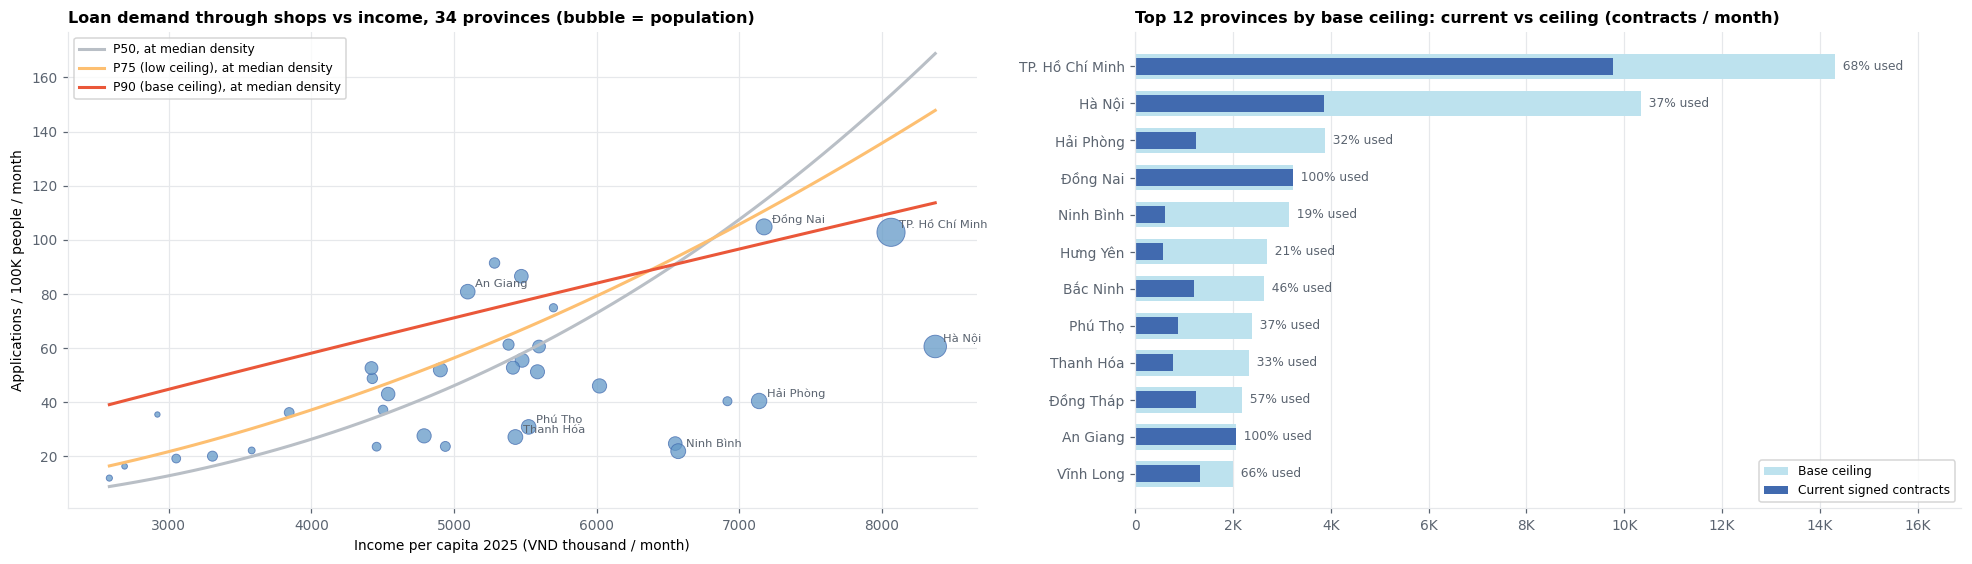

Nhu cầu qua điểm bán chênh 9 lần giữa các tỉnh (Điện Biên 12 → Đồng Nai 105 hồ sơ / 100K dân / tháng); tương quan với thu nhập (log) = 0.62.


In [20]:
# biểu đồ thị trường theo tỉnh: nhu cầu vay qua điểm bán so với thu nhập, và khoảng trống thị trường
from sklearn.linear_model import QuantileRegressor
import matplotlib.ticker as mtick
INK, INK2, GREY = '#1f1f1f', '#5b6470', '#b9bfc6'
human = lambda v, _=None: f'{v / 1e3:,.0f}K' if abs(v) >= 1e3 else f'{v:,.0f}'
pv_ = meta['prov'].copy()
Xq = np.column_stack([np.log(pv_.inc), np.log(pv_.dens)])
xs_ = np.linspace(pv_.inc.min(), pv_.inc.max(), 60)
Xg = np.column_stack([np.log(xs_), np.full(len(xs_), np.log(pv_.dens).median())])
fig, ax = plt.subplots(1, 2, figsize=(18, 5.2), gridspec_kw={'width_ratios': [1.1, 1]})
ax[0].scatter(pv_.inc, pv_.app_rate, s=pv_['pop'] / 4e4, color=RDYLBU[9], alpha=.75, edgecolor=RDYLBU[10], lw=.6)
for qq, c_, lab in [(.5, GREY, 'P50'), (.75, RDYLBU[3], 'P75 (low ceiling)'), (.9, RDYLBU[1], 'P90 (base ceiling)')]:
    m_ = QuantileRegressor(quantile=qq, alpha=0, solver='highs').fit(Xq, np.log(pv_.app_rate))
    ax[0].plot(xs_, np.exp(m_.predict(Xg)), color=c_, lw=2, label=f'{lab}, at median density')
for p_, r_ in pv_.sort_values('pop', ascending=False).head(8).iterrows():
    ax[0].annotate(p_, (r_.inc, r_.app_rate), xytext=(5, 3), textcoords='offset points', fontsize=7.5, color=INK2)
ax[0].set_xlabel('Income per capita 2025 (VND thousand / month)'); ax[0].set_ylabel('Applications / 100K people / month')
ax[0].legend(loc='upper left', fontsize=8); ax[0].set_title('Loan demand through shops vs income, 34 provinces (bubble = population)')
top_ = pv_.assign(room=(pv_.ceil_coso - pv_.sig).clip(lower=0)).sort_values('ceil_coso', ascending=False).head(12)[::-1]
y_ = np.arange(len(top_))
ax[1].barh(y_, top_.ceil_coso, color=RDYLBU[7], height=.7, label='Base ceiling')
ax[1].barh(y_, top_.sig, color=RDYLBU[10], height=.45, label='Current signed contracts')
for yi, (c0, s0) in enumerate(zip(top_.ceil_coso, top_.sig)):
    ax[1].text(c0, yi, f'  {s0 / c0:.0%} used', va='center', fontsize=8, color=INK2)
ax[1].set_yticks(y_, top_.index); ax[1].xaxis.set_major_formatter(mtick.FuncFormatter(human)); ax[1].grid(axis='y', visible=False)
ax[1].set_xlim(0, top_.ceil_coso.max() * 1.18); ax[1].legend(loc='lower right', fontsize=8)
ax[1].set_title('Top 12 provinces by base ceiling: current vs ceiling (contracts / month)')
plt.tight_layout(); plt.show()
print(f"Nhu cầu qua điểm bán chênh {pv_.app_rate.max() / pv_.app_rate.min():.0f} lần giữa các tỉnh "
      f"({pv_.app_rate.idxmin()} {pv_.app_rate.min():.0f} → {pv_.app_rate.idxmax()} {pv_.app_rate.max():.0f} hồ sơ / 100K dân / tháng); "
      f"tương quan với thu nhập (log) = {np.corrcoef(np.log(pv_.inc), np.log(pv_.app_rate))[0, 1]:.2f}.")

## Bước 7 · Khoảng cách và nguyên nhân: hai shop bán như nhau khác nhau ở đâu?
**Cách làm:**
- **Cơ hội can thiệp** = Attainable (kịch bản giữa) − BAU. **Nút thắt** của shop là đòn bẩy có khoảng cách lớn nhất so với peer:
  - **Thiếu khách:** hồ sơ dưới mức có thể đạt.
  - **Chốt kém:** tỷ lệ chốt sau duyệt dưới P75.
  - **Thiếu sản phẩm:** ≥ 50% peer bán sản phẩm đó, shop này chưa bán.
  - **Thiếu SA:** shop Non-Aldi không có SA nào được gán. Đây là thứ duy nhất đo được về nhân sự.
- Phần lớn nhất là **nút thắt chính**. **Ceiling − Attainable** là phần thị trường shop chưa chạm tới.
- Để trả lời câu hỏi trung tâm, shop được xếp theo **mức doanh số hiện tại × dư địa tham chiếu** (khoảng cách so với P75 peer):
  - **Gần trần:** cơ hội < 0,5 HĐ/tháng hoặc < 15%.
  - **Vừa:** 0,5–2 HĐ/tháng.
  - **Lớn:** ≥ 2 HĐ/tháng.

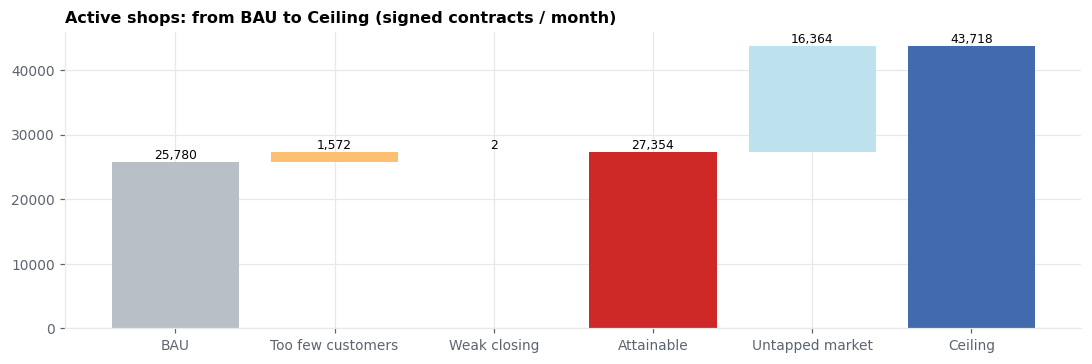

,shop,co_hoi_HD,co_hoi_ty
nut_that,,,
Chốt kém,350,2.40,0.00
Gần trần,1377,40.50,0.60
Thiếu khách,3561,"1,525.40",21.10
Thiếu sản phẩm,43,5.70,0.10


Số shop theo mức doanh số hiện tại × dư địa:


headroom,Gần trần,Dư địa vừa,Dư địa lớn
sales_band,,,
< 1,0,200,1634
1–3,116,568,773
3–10,764,348,238
≥ 10,497,24,169


In [21]:
NUT = {'Tăng lượng hồ sơ': 'Thiếu khách', 'Chốt sau duyệt': 'Chốt kém', 'Thiếu sản phẩm': 'Thiếu sản phẩm', 'Thiếu SA': 'Thiếu SA',
       'Gần trần': 'Gần trần'}
a = a.assign(nut_that=a.lever.map(NUT))
share = a[['val_Tăng lượng hồ sơ', 'val_Chốt sau duyệt', 'val_Thiếu sản phẩm']].div(a.opp_val.replace(0, np.nan), axis=0).fillna(0)
comp = pd.Series({'Thiếu khách': (share['val_Tăng lượng hồ sơ'] * a.opp).sum(), 'Chốt kém': (share['val_Chốt sau duyệt'] * a.opp).sum(),
                  'Thiếu sản phẩm': (share['val_Thiếu sản phẩm'] * a.opp).sum(), 'Thiếu SA': 0.0})
# waterfall toàn mạng lưới (shop đang hoạt động)
steps = [('BAU', a.bau.sum())] + [(k, v) for k, v in comp.items() if v > 0] + [('Attainable', a.attainable.sum()),
         ('Thị trường chưa chạm', a.ceiling.sum() - a.attainable.sum()), ('Ceiling', a.ceiling.sum())]
fig, ax = plt.subplots(figsize=(10, 3.4)); run_ = 0
for i, (k, v) in enumerate(steps):
    if k in ('BAU', 'Attainable', 'Ceiling'):
        ax.bar(i, v, color={'BAU': GREY, 'Attainable': RED, 'Ceiling': DARK}[k]); run_ = v
    else:
        ax.bar(i, v, bottom=run_, color=RED3 if k != 'Thị trường chưa chạm' else '#bde2ee'); run_ += v
    ax.text(i, run_ if k not in ('BAU', 'Attainable', 'Ceiling') else v, f'{v:,.0f}', ha='center', va='bottom', fontsize=8)
ax.set_xticks(range(len(steps)), [s[0] for s in steps]); ax.set_title('Shop đang hoạt động: từ BAU tới Ceiling (HĐ ký / tháng)')
plt.tight_layout(); plt.show()
display(a.groupby('nut_that').agg(shop=('opp', 'size'), co_hoi_HD=('opp', 'sum'), co_hoi_ty=('opp_val', lambda s: s.sum() / TY)).round(1))
hcol = ['Gần trần', 'Dư địa vừa', 'Dư địa lớn']
print('Số shop theo mức doanh số hiện tại × dư địa:')
display(pd.crosstab(a.sales_band, a.headroom).reindex(index=order, columns=hcol).fillna(0).astype(int))

In [22]:
# ví dụ thật: cùng nhóm peer, cùng mức HĐ ký, khác dư địa
m = a[(a.confidence != 'Thấp') & (a.risk != 'R')].assign(cbin=lambda x: x.current.round(0))
grp = m[m.cbin.between(3, 15)].groupby(['peer', 'cbin']).opp.agg(['size', 'max', 'min'])
grp = grp[grp['size'] >= 3]
for peer_, cbin_ in (grp['max'] - grp['min']).sort_values(ascending=False).index:
    g = m[(m.peer == peer_) & (m.cbin == cbin_)]
    X, Y = g.loc[g.opp.idxmax()], g.loc[g.opp.idxmin()]
    if X.headroom != Y.headroom: break
ex = pd.DataFrame({'Shop X': X, 'Shop Y': Y}).loc[['skp_salesroom', 'peer', 'seller_type', 'seller_n_shop', 'province_std', 'current', 'apps_m',
      'apps_target', 'appr_s', 'close_s', 'close_p', 'missing_products', 'bau', 'attainable', 'ceiling', 'opp', 'headroom', 'nut_that', 'action']]
display(ex)
ANS[7] = (f"Shop đang hoạt động còn {a.opp.sum():,.0f} HĐ/tháng ({a.opp_val.sum()/TY:,.0f} tỷ) giữa BAU và Attainable: "
          f"{comp['Thiếu khách']/comp.sum():.0%} do thiếu khách (hồ sơ), {comp['Chốt kém']/comp.sum():.0%} do chốt kém, "
          f"{comp['Thiếu sản phẩm']/comp.sum():.0%} do thiếu sản phẩm. Ví dụ: shop {int(X.skp_salesroom)} và {int(Y.skp_salesroom)} cùng ~{X.current:.0f} HĐ/tháng, "
          f"cùng nhóm {X.peer}, nhưng shop X còn +{X.opp:.1f} HĐ/tháng ({X.nut_that}; mục tiêu hồ sơ {X.apps_target:.1f} vì đối tác {X.seller_n_shop:.0f} shop, "
          f"thiếu {X.missing_products or 'không'}) còn shop Y chỉ +{Y.opp:.1f} ({Y.headroom}).")
print('→ Trả lời:', ANS[7])

,Shop X,Shop Y
skp_salesroom,117673569,96605617
peer,TW|Non-Aldi|Medium|Stone Shop,TW|Non-Aldi|Medium|Stone Shop
seller_type,Stone Shop,Stone Shop
seller_n_shop,5,1
province_std,TP. Hồ Chí Minh,TP. Hồ Chí Minh
current,4.00,3.67
apps_m,6.33,4.33
apps_target,8.98,5.53
appr_s,0.82,0.94
close_s,0.90,0.90


→ Trả lời: Shop đang hoạt động còn 1,574 HĐ/tháng (22 tỷ) giữa BAU và Attainable: 100% do thiếu khách (hồ sơ), 0% do chốt kém, 0% do thiếu sản phẩm. Ví dụ: shop 117673569 và 96605617 cùng ~4 HĐ/tháng, cùng nhóm TW|Non-Aldi|Medium|Stone Shop, nhưng shop X còn +1.8 HĐ/tháng (Thiếu khách; mục tiêu hồ sơ 9.0 vì đối tác 5 shop, thiếu CC, BNPL) còn shop Y chỉ +0.0 (Dư địa vừa).


## Bước 8 · Ưu tiên nguồn lực: shop nào, được bao nhiêu, làm gì?
**Cách làm:**
- **Điểm ưu tiên** = giá trị tăng thêm khai thác được trong 6 tháng (kịch bản giữa) × (1 − phạt rủi ro).
  - "Khai thác được trong 6 tháng": tối đa 2 quý × mức tăng mà top 20% shop cùng dòng hàng, cùng mức doanh số đã đạt.
  - Độ khả thi của từng đòn bẩy **đã nằm trong tỷ lệ đóng khoảng cách đo từ lịch sử** (bước 5), không nhân thêm hệ số chủ quan.
  - Phạt rủi ro: 0,5 nếu FPD hoặc trễ hạn > P90 của peer.
- **Hành động** ghép theo nút thắt, khác nhau cho Aldi và Non-Aldi. Mỗi shop có **mức bằng chứng** của con số (B: cải thiện trong lịch sử · C: chỉ có benchmark).

In [23]:
A_ = a[(a.tier == 'A')]
act_tbl = a.groupby(['nut_that', 'model']).agg(shop=('opp', 'size'), shop_rui_ro=('risk', lambda s: (s == 'R').sum()),
                                              co_hoi_6t_HD=('opp_6m', 'sum'), co_hoi_6t_ty=('opp_6m_val', lambda s: s.sum() / TY),
                                              hanh_dong=('action', 'first'))
display(act_tbl.round(1))
cur_ = resource_curve(d)
pts = [100, 250, 500, 1000, 2000]
print('Nếu nguồn lực chỉ đủ cho N shop (xếp theo điểm ưu tiên; mức tăng so với BAU theo kịch bản giữa, kèm thấp – cao):')
ix_ = [min(n, len(cur_)) - 1 for n in pts]
display(pd.DataFrame({'N shop': pts, 'HĐ/tháng thêm': cur_.cum_hd.iloc[ix_].values, 'tỷ đ/tháng thêm': cur_.cum_val.iloc[ix_].values / TY,
                      'thấp': cur_.cum_val_lo.iloc[ix_].values / TY, 'cao': cur_.cum_val_hi.iloc[ix_].values / TY}).round(1))
print('Mức bằng chứng của con số Attainable (shop đang hoạt động):', a.evidence.value_counts().to_dict())
print('Top 15 shop ưu tiên:')
display(cur_.head(15)[['skp_salesroom', 'peer', 'province_std', 'current', 'bau', 'att_thap', 'attainable', 'att_cao', 'bien_phap', 'nguon_luc', 'evidence', 'confidence']].round(2))
dm = d[d.status == 'Không hoạt động']
display(dm.groupby('action').agg(shop=('current', 'size'), Stone_Shop=('seller_type', lambda s: (s == 'Stone Shop').mean()),
                                 gia_tri_neu_kich_hoat_ty=('reactivate_val', lambda s: s.sum() / TY)).round(2))
g_max = max_same_store_growth(base, ASOF)
d['kpi'], d['kpi_val'], f_ = scale_kpi(d, g_max)
ar = d.groupby('area').agg(shop_uu_tien=('tier', lambda s: (s == 'A').sum()), current=('current', 'sum'), bau=('bau', 'sum'), kpi=('kpi', 'sum'),
                           co_hoi_6t_ty=('opp_6m_val', lambda s: s.sum() / TY)).sort_values('co_hoi_6t_ty', ascending=False)
print(f"KPI quý tới theo vùng (giao 50%/20% cơ hội cho shop ưu tiên/giữ vững, giảm còn {f_:.2f} lần để tổng KPI ≤ BAU × (1 + {g_max:.1%})):")
display(ar.round(1))
ANS[8] = (f"{len(A_):,} shop nên được đầu tư thêm (cơ hội 6 tháng {A_.opp_6m.sum():,.0f} HĐ/tháng, {A_.opp_6m_val.sum()/TY:,.0f} tỷ). "
          f"Nguồn lực cho 500 shop đầu danh sách mang lại ~{cur_.cum_hd.iloc[499]:,.0f} HĐ / {cur_.cum_val.iloc[499]/TY:,.1f} tỷ mỗi tháng. "
          f"Nút thắt chủ yếu là thiếu khách → Non-Aldi: tăng giờ SA trực quầy, POSM, phân lead CL/CC; Aldi: khuyến khích đối tác. "
          f"{(dm.action.str.startswith('Kích')).sum():,} shop không hoạt động nên kích hoạt lại, {(dm.action.str.startswith('Rút')).sum():,} nên rút. "
          f"Vùng có cơ hội lớn nhất: {', '.join(ar.index[:3])}.")
print('→ Trả lời:', ANS[8])

shop  shop_rui_ro  co_hoi_6t_HD  co_hoi_6t_ty                                          hanh_dong
nut_that       model                                                                                                     
Chốt kém       Aldi        88           10          1.40          0.00  Đào tạo nhân viên shop, thưởng theo HĐ ký (khô...
               Non-Aldi   262           31          1.00          0.00  Kèm cặp SA, rà nguyên nhân khách huỷ sau khi đ...
Gần trần       Aldi       310           47         11.30          0.10  Duy trì; bán chéo bảo hiểm / thẻ / vay tiền mặ...
               Non-Aldi  1067          145         29.10          0.40  Duy trì; bán chéo bảo hiểm / thẻ / vay tiền mặ...
Thiếu khách    Aldi       776           49        304.90          3.90  Chương trình khuyến khích đối tác, phân lead C...
               Non-Aldi  2785          176      1,220.60         17.10  Tăng giờ SA trực quầy, POSM / khuyến mãi tại đ...
Thiếu sản phẩm Non-Aldi    43            7          5.70          0.10  Mở bán sản phẩm còn thiếu, SA tư vấn bán chéo ...

Nếu nguồn lực chỉ đủ cho N shop (xếp theo điểm ưu tiên; mức tăng so với BAU theo kịch bản giữa, kèm thấp – cao):


,N shop,HĐ/tháng thêm,tỷ đ/tháng thêm,thấp,cao
0,100,92.70,1.80,0.70,3.60
1,250,220.20,3.80,1.70,7.60
2,500,392.40,6.40,2.60,13.80
3,1000,711.50,10.70,4.10,22.90
4,2000,"1,252.30",17.50,6.70,37.00


Mức bằng chứng của con số Attainable (shop đang hoạt động): {'B · thay đổi trong cùng shop (2 quý)': 2987, '—': 1769, 'Chặn: rủi ro cao hơn P90 peer': 465, 'B · cải thiện tự nhiên trong lịch sử': 110}
Top 15 shop ưu tiên:


,skp_salesroom,peer,province_std,current,bau,att_thap,attainable,att_cao,bien_phap,nguon_luc,evidence,confidence
774,117673569,TW|Non-Aldi|Medium|Stone Shop,TP. Hồ Chí Minh,4.00,3.66,4.93,5.41,5.90,Nâng tỷ lệ chốt lead lên P75 peer,kèm cặp xử lý 46 lead / tháng,B · cải thiện tự nhiên trong lịch sử,Trung bình
538,112296768,TW|Non-Aldi|Small|TW Key Dealer,TP. Hồ Chí Minh,1.33,1.99,2.39,3.18,4.76,Tăng lead chiến dịch (SOB) tại điểm bán,16 lead chiến dịch / quý,B · thay đổi trong cùng shop (2 quý),Thấp
5459,107389222,TW|Non-Aldi|Small|TW Key Dealer,Tây Ninh,12.33,8.77,9.16,9.94,10.71,Tăng lead chiến dịch (SOB) tại điểm bán,16 lead chiến dịch / quý,B · thay đổi trong cùng shop (2 quý),Cao
634,114682950,TW|Non-Aldi|Medium|TW Key Dealer,TP. Hồ Chí Minh,7.00,8.12,8.63,9.32,9.93,Tăng lead chiến dịch (SOB) tại điểm bán,13 lead chiến dịch / quý,B · thay đổi trong cùng shop (2 quý),Cao
2661,114195755,TW|Non-Aldi|Small|TW Key Dealer,TP. Hồ Chí Minh,8.67,10.52,10.97,11.77,12.53,Tăng lead chiến dịch (SOB) tại điểm bán,16 lead chiến dịch / quý,B · thay đổi trong cùng shop (2 quý),Cao
2901,114265400,TW|Non-Aldi|Medium|TW Key Dealer,Tây Ninh,9.67,9.35,9.66,10.24,10.81,Tăng lead chiến dịch (SOB) tại điểm bán,12 lead chiến dịch / quý,B · thay đổi trong cùng shop (2 quý),Cao
357,106678909,NS|Aldi|Small|NS KA,TP. Hồ Chí Minh,3.33,3.12,3.74,4.14,4.54,Tăng lead chiến dịch (SOB) tại điểm bán,3 lead chiến dịch / quý,B · thay đổi trong cùng shop (2 quý),Trung bình
455,109494239,TW|Non-Aldi|Medium|TW Key Dealer,TP. Hồ Chí Minh,3.00,2.33,2.73,3.39,4.00,Tăng lead chiến dịch (SOB) tại điểm bán,13 lead chiến dịch / quý,B · thay đổi trong cùng shop (2 quý),Trung bình
158,102355446,CD|Non-Aldi|Big|Stone Shop,TP. Hồ Chí Minh,1.33,1.35,1.57,2.05,4.73,Tăng lead chiến dịch (SOB) tại điểm bán,10 lead chiến dịch / quý,B · thay đổi trong cùng shop (2 quý),Thấp
1737,104883946,NS|Aldi|Big|NS KA,Đồng Nai,10.00,7.69,8.37,8.78,9.19,Tăng lead chiến dịch (SOB) tại điểm bán,3 lead chiến dịch / quý,B · thay đổi trong cùng shop (2 quý),Cao


,shop,Stone_Shop,gia_tri_neu_kich_hoat_ty
action,,,
"Kích hoạt lại: thị trường còn trống, đối tác có chuỗi / lâu năm",696,0.75,7.10
"Rút / đóng: thị trường nhỏ, đối tác nhỏ và mới",1464,0.92,0.00


KPI quý tới theo vùng (giao 50%/20% cơ hội cho shop ưu tiên/giữ vững, giảm còn 1.00 lần để tổng KPI ≤ BAU × (1 + 5.3%)):


,shop_uu_tien,current,bau,kpi,co_hoi_6t_ty
area,,,,,
Sai Gon,550,"7,868.30","7,600.90","7,710.30",3.50
North,644,"6,039.70","5,951.60","6,066.80",3.20
North East,600,"4,008.70","4,171.00","4,283.60",3.00
Central - NHL,434,"4,232.00","4,214.50","4,301.70",2.30
South East,313,"2,749.80","2,763.10","2,832.40",2.10
Western,363,"3,877.50","3,872.30","3,944.40",2.00
Eastern South,269,"4,039.00","3,933.10","3,987.20",1.50
Eastern North,263,"3,076.70","3,095.70","3,149.90",1.50
Mekong,251,"3,486.20","3,477.20","3,529.50",1.50


→ Trả lời: 3,954 shop nên được đầu tư thêm (cơ hội 6 tháng 1,534 HĐ/tháng, 21 tỷ). Nguồn lực cho 500 shop đầu danh sách mang lại ~392 HĐ / 6.4 tỷ mỗi tháng. Nút thắt chủ yếu là thiếu khách → Non-Aldi: tăng giờ SA trực quầy, POSM, phân lead CL/CC; Aldi: khuyến khích đối tác. 696 shop không hoạt động nên kích hoạt lại, 1,464 nên rút. Vùng có cơ hội lớn nhất: Sai Gon, North, North East.


## Bước 9 · Kiểm chứng: có đáng tin không?
**Cách làm:**
1. **Backtest:** chạy lại toàn bộ quy trình với dữ liệu đến Q1/2026 (và đến Q2/2026), rồi xem shop "dư địa vừa/lớn" có tăng nhanh hơn shop "gần trần" **cùng mức doanh số** không.
2. **Độ nhạy:** đổi P75 thành P70/P80 và trần từ P90 xuống P75, xem tổng tiềm năng và top 1.000 shop ưu tiên đổi bao nhiêu.
3. **Bootstrap:** lấy mẫu lại shop trong nhóm peer để có khoảng tin cậy của P75 (dư địa tham chiếu).
4. **Lưu ý:** backtest BAU tốt **không** chứng minh can thiệp hiệu quả; tỷ lệ đóng khoảng cách hiện là cải thiện tự nhiên, cần pilot có đối chứng để đo tác động thật.
5. **Pilot:** thiết kế thử nghiệm thực tế.

In [24]:
bt = {}
for a0 in [Q(2026, 1), Q(2026, 2)]:
    tab, _, rho, _ = validate_opportunity(base, a0, horizon=ASOF - a0)
    t_ = tab.tang.unstack().reindex(index=order, columns=hcol)
    bt[qname(a0)] = t_
    print(f"Mốc {qname(a0)} → thực tế {qname(ASOF)}: tăng HĐ/tháng TB theo mức doanh số × dư địa (Spearman cơ hội ~ tăng trưởng = {rho:.2f})")
    display(t_.round(2))
sen = sensitivity(base); display(sen.round(3))
lo, mid, hi = bootstrap_att(d, 200)
p = pilot_size(d)
low = bt['2026Q1'].loc[['< 1', '1–3']]
ANS[9] = (f"Ở nhóm bán < 3 HĐ/tháng, shop có dư địa tăng nhanh hơn shop gần trần (mốc Q1: "
          f"{low['Dư địa vừa'].mean():+.2f} / {low['Dư địa lớn'].mean():+.2f} so với {low['Gần trần'].mean():+.2f} HĐ/tháng); ở nhóm bán nhiều tín hiệu lẫn lộn. "
          f"Đổi P70/P80 hoặc trần P75 vẫn giữ {sen.giu_top.iloc[1:].min():.0%}–{sen.giu_top.iloc[1:].max():.0%} top 1.000 shop. "
          f"Dư địa tham chiếu (P75) dao động {lo:,.0f}–{hi:,.0f} HĐ/tháng (bootstrap 90%); Attainable theo kịch bản thấp–cao: {a.att_thap.sum():,.0f}–{a.att_cao.sum():,.0f}. "
          f"Pilot: cần ≥ {p['n_per_arm']:,} shop/nhánh (can thiệp và đối chứng) để phát hiện mức tăng kịch bản giữa ({p['delta']:.2f} HĐ/tháng/shop), "
          f"3 tháng, chặn khi FPD vượt P90 peer; tỷ lệ đóng khoảng cách đo được sẽ thay cho bằng chứng mức B.")
print('→ Trả lời:', ANS[9])

Mốc 2026Q1 → thực tế 2026Q3: tăng HĐ/tháng TB theo mức doanh số × dư địa (Spearman cơ hội ~ tăng trưởng = nan)


C:\Users\huynh\AppData\Local\Temp\ipykernel_23512\2357041583.py:384: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  d['tier'] = np.select([dormant, young, (d.headroom != 'Gần trần'), d.sales_band.isin(['3–10', '≥ 10'])],
C:\Users\huynh\AppData\Local\Temp\ipykernel_23512\2357041583.py:386: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  d['tier_label'] = d.tier + np.where(d.risk == 'R', '-R', '')
C:\Users\huynh\AppData\Local\Temp\ipykernel_23512\2357041583.py:389: PerformanceWarning: DataFrame is highly fragmented.  This is usually 

headroom,Gần trần,Dư địa vừa,Dư địa lớn
sales_band,,,
< 1,-0.33,0.49,0.51
1–3,-0.14,0.41,0.31
3–10,-0.08,0.59,-0.18
≥ 10,-3.00,2.17,-0.78


Mốc 2026Q2 → thực tế 2026Q3: tăng HĐ/tháng TB theo mức doanh số × dư địa (Spearman cơ hội ~ tăng trưởng = 0.06)


C:\Users\huynh\AppData\Local\Temp\ipykernel_23512\2357041583.py:384: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  d['tier'] = np.select([dormant, young, (d.headroom != 'Gần trần'), d.sales_band.isin(['3–10', '≥ 10'])],
C:\Users\huynh\AppData\Local\Temp\ipykernel_23512\2357041583.py:386: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  d['tier_label'] = d.tier + np.where(d.risk == 'R', '-R', '')
C:\Users\huynh\AppData\Local\Temp\ipykernel_23512\2357041583.py:389: PerformanceWarning: DataFrame is highly fragmented.  This is usually 

...

C:\Users\huynh\AppData\Local\Temp\ipykernel_23512\2357041583.py:384: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  d['tier'] = np.select([dormant, young, (d.headroom != 'Gần trần'), d.sales_band.isin(['3–10', '≥ 10'])],
C:\Users\huynh\AppData\Local\Temp\ipykernel_23512\2357041583.py:386: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  d['tier_label'] = d.tier + np.where(d.risk == 'R', '-R', '')
C:\Users\huynh\AppData\Local\Temp\ipykernel_23512\2357041583.py:389: PerformanceWarning: DataFrame is highly fragmented.  This is usually 

C:\Users\huynh\AppData\Local\Temp\ipykernel_23512\2357041583.py:384: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  d['tier'] = np.select([dormant, young, (d.headroom != 'Gần trần'), d.sales_band.isin(['3–10', '≥ 10'])],
C:\Users\huynh\AppData\Local\Temp\ipykernel_23512\2357041583.py:386: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  d['tier_label'] = d.tier + np.where(d.risk == 'R', '-R', '')
C:\Users\huynh\AppData\Local\Temp\ipykernel_23512\2357041583.py:389: PerformanceWarning: DataFrame is highly fragmented.  This is usually 

C:\Users\huynh\AppData\Local\Temp\ipykernel_23512\2357041583.py:384: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  d['tier'] = np.select([dormant, young, (d.headroom != 'Gần trần'), d.sales_band.isin(['3–10', '≥ 10'])],
C:\Users\huynh\AppData\Local\Temp\ipykernel_23512\2357041583.py:386: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  d['tier_label'] = d.tier + np.where(d.risk == 'R', '-R', '')
C:\Users\huynh\AppData\Local\Temp\ipykernel_23512\2357041583.py:389: PerformanceWarning: DataFrame is highly fragmented.  This is usually 

,kich_ban,tran,attainable,opp_val_ty,shop_A,giu_top
0,"Gốc: mục tiêu P75, trần P90","90,657.34","42,759.61",21.74,3954,1.00
1,Mục tiêu P70,"90,657.34","42,319.35",15.62,3795,0.90
2,Mục tiêu P80,"90,657.34","43,384.02",30.49,4075,0.87
3,Ceiling cơ sở theo P75,"76,259.55","42,708.15",21.00,3737,0.96


→ Trả lời: Ở nhóm bán < 3 HĐ/tháng, shop có dư địa tăng nhanh hơn shop gần trần (mốc Q1: +0.45 / +0.41 so với -0.24 HĐ/tháng); ở nhóm bán nhiều tín hiệu lẫn lộn. Đổi P70/P80 hoặc trần P75 vẫn giữ 87%–96% top 1.000 shop. Dư địa tham chiếu (P75) dao động 38,824–39,611 HĐ/tháng (bootstrap 90%); Attainable theo kịch bản thấp–cao: 26,401–29,177. Pilot: cần ≥ 1,270 shop/nhánh (can thiệp và đối chứng) để phát hiện mức tăng kịch bản giữa (0.42 HĐ/tháng/shop), 3 tháng, chặn khi FPD vượt P90 peer; tỷ lệ đóng khoảng cách đo được sẽ thay cho bằng chứng mức B.


## Bước 10 · Khuyến nghị cụ thể: shop nào, nhóm khách nào, làm gì
**Câu hỏi:** khuyến nghị phải chỉ ra được *shop nào* và *nhóm khách hàng nào* cần hành động, hành động gì, nguồn lực bao nhiêu, kỳ vọng thêm bao nhiêu.

**Cách làm:**
- **Theo nhóm shop:** shop đang hoạt động được gom theo phân khúc × hành động chính (biện pháp có mức tăng lớn nhất; chặn rủi ro; giữ vững nếu gần trần).
- **Theo shop cụ thể:** top shop theo điểm ưu tiên (tầng A, không rủi ro); shop bị chặn vì rủi ro có quy mô lớn nhất; shop không hoạt động nên kích hoạt lại.
- **Theo nhóm khách hàng:** khách của shop vật lý chia theo hành trình (khách mới CD/TW, khách có lead theo sản phẩm, khách bị từ chối, khách huỷ sau duyệt) và theo phân khúc khách hàng Round 2 (FH × ENG).
- Kết quả lưu ở `output/khuyen_nghi_*.csv`.

In [25]:
# Bước 10 – khuyến nghị theo nhóm shop, shop cụ thể, nhóm khách hàng
import duckdb
SEGN = d.line + ' · ' + d.model
act_ = d.status == 'Đang hoạt động'
grp = np.select([act_ & (d.risk == 'R'), act_ & (d.bien_phap != '—'), act_ & (d.headroom == 'Gần trần')],
                ['Chặn rủi ro: xử lý chất lượng khoản vay trước', d.bien_phap, 'Giữ vững: gần trần, bán chéo cho khách hiện có'], 'Theo dõi: dư địa nhỏ')
d['nhom_hanh_dong'] = np.where(act_, grp, np.where(d.status == 'Mới mở', 'Mới mở: theo dõi đường cong tuổi',
                               np.where(d.action.str.startswith('Kích'), 'Không hoạt động: kích hoạt lại', 'Không hoạt động: rút / đóng')))
d['phan_khuc'] = SEGN
def top_prov(s): return ', '.join(s.value_counts().head(3).index)
g1 = d.groupby(['nhom_hanh_dong', 'phan_khuc']).agg(
    shop=('skp_salesroom', 'size'), hien_tai=('current', 'sum'), BAU=('bau', 'sum'), Attainable=('attainable', 'sum'),
    tang_HD=('opp', 'sum'), tang_ty=('opp_val', lambda s: s.sum() / TY), lead_quy=('add_lead', lambda s: s.sum() * 3),
    SA=('add_sa', 'sum'), giu_lai_rui_ro=('risk_blocked', 'sum'), tinh_chinh=('province_std', top_prov)).reset_index()
g1 = g1[g1.shop >= 20].sort_values(['tang_HD', 'shop'], ascending=False)
print('Theo nhóm shop (≥ 20 shop):'); display(g1.round(1))

cols_t = ['skp_salesroom', 'phan_khuc', 'category', 'seller_type', 'province_std', 'current', 'bau', 'att_thap', 'attainable', 'att_cao', 'opp', 'opp_val',
          'bien_phap', 'nguon_luc', 'evidence', 'confidence']
top = d[act_ & (d.tier == 'A') & (d.risk != 'R')].sort_values('priority', ascending=False).head(30)[cols_t].assign(opp_val=lambda x: x.opp_val / 1e6)
print('Top 30 shop nên đầu tư (giá trị tăng thêm: triệu đ / tháng):'); display(top.round(2))
risk_ = d[act_ & (d.risk == 'R')].sort_values('current', ascending=False).head(20)[
    ['skp_salesroom', 'phan_khuc', 'province_std', 'current', 'bau', 'fpd_s', 'fpd_s_p90', 'risk_blocked']]
print('Shop rủi ro cao có quy mô lớn nhất (FPD so với P90 peer):'); display(risk_.round(3))
dorm = d[d.status == 'Không hoạt động'].copy()
rea = dorm[dorm.action.str.startswith('Kích')].sort_values('reactivate_val', ascending=False).head(20)[
    ['skp_salesroom', 'phan_khuc', 'seller_type', 'seller_n_shop', 'province_std', 'reactivate_val']].assign(reactivate_val=lambda x: x.reactivate_val / 1e6)
print(f"Shop không hoạt động: {dorm.action.str.startswith('Kích').sum():,} nên kích hoạt lại, {dorm.action.str.startswith('Rút').sum():,} nên rút. Top kích hoạt lại (giá trị kỳ vọng, triệu đ / tháng):")
display(rea.round(2))

# ---------------- nhóm khách hàng của shop vật lý
cc = duckdb.connect()
rd_ = lambda t: f"read_csv('{(CLEAN / (t + '.csv')).as_posix()}', sample_size=200000)"
cc.sql(f"CREATE TABLE ph AS SELECT skp_salesroom FROM {rd_('salesroom')} WHERE salesroom_category <> 'Virtual'")
cc.sql(f'''CREATE TABLE k AS SELECT skp_client, skp_salesroom, product, date_apply, name_status, is_signed AND name_status <> 'Cancelled' ok, loan_amount_eff
           FROM {rd_('contract')} WHERE skp_client > 0''')
Q3a, Q3b = "DATE '2026-07-01'", "DATE '2026-10-01'"
newc = cc.sql(f'''WITH f AS (SELECT * FROM k WHERE ok QUALIFY row_number() OVER (PARTITION BY skp_client ORDER BY date_apply) = 1)
                  SELECT count(*) / 3 n FROM f WHERE product IN ('CD','TW') AND skp_salesroom IN (SELECT * FROM ph)
                  AND date_apply >= {Q3a} AND date_apply < {Q3b}''').fetchone()[0]
rej = cc.sql(f'''SELECT count(*) FILTER (WHERE name_status = 'Rejected') / 3, count(*) FILTER (WHERE name_status = 'Cancelled') / 3, count(*) / 3
                 FROM k WHERE skp_salesroom IN (SELECT * FROM ph) AND date_apply >= {Q3a} AND date_apply < {Q3b}''').fetchone()
ldp = cc.sql(f'''SELECT code_product_type p, sum(sample_weight) / 3 lead_thang,
                        sum(sample_weight) FILTER (WHERE converted_sign) / sum(sample_weight) conv
                 FROM {rd_('leads')} WHERE id_lead_source <> 'INSTANT_TWO_RTDM' AND skp_salesroom IN (SELECT * FROM ph)
                 AND date_assigned >= DATE '2026-06-01' AND date_assigned < DATE '2026-09-01' GROUP BY 1''').df().set_index('p')
lp = lambda p, c: ldp.loc[p, c] if p in ldp.index else np.nan
cust = pd.DataFrame([
    dict(nhom='Khách mới mua CD/TW lần đầu tại shop', quy_mo_thang=newc, chi_so=f"{base['xs_rate']:.1%} vay thêm CL/CC/CW trong 12 tháng, 95% vay ở nơi khác",
         hanh_dong='Giới thiệu CL/CC ngay tại quầy và tạo lead gắn với shop; nhắc lại khi khách gần tất toán', phu_trach='SA / nhân viên đối tác + CRM',
         kpi='% khách mới có lead CL/CC trong 30 ngày; HĐ online ghi nhận cho shop'),
    dict(nhom='Khách có lead CD (không RTDM)', quy_mo_thang=lp('CD', 'lead_thang'), chi_so=f"{lp('CD', 'conv'):.0%} ra HĐ ký trong 30 ngày",
         hanh_dong='Ưu tiên phân lead, gọi lại trong ngày; đây là nhóm chuyển đổi cao nhất', phu_trach='SA', kpi='Lead CD → HĐ; thời gian từ giao lead đến gọi'),
    dict(nhom='Khách có lead TW (không RTDM)', quy_mo_thang=lp('TW', 'lead_thang'), chi_so=f"{lp('TW', 'conv'):.0%} ra HĐ ký",
         hanh_dong='Tăng tỷ trọng lead TW cho đại lý xe máy (TW Key Dealer) đang dưới P75 peer', phu_trach='Marketing + SA', kpi='Lead TW / shop TW'),
    dict(nhom='Khách có lead CL (không RTDM)', quy_mo_thang=lp('CL', 'lead_thang'), chi_so=f"{lp('CL', 'conv'):.0%} ra HĐ ký; chỉ khoảng 1/4 ký đúng CL (44% ký thẻ, 22% BNPL)",
         hanh_dong='Chào gói nhiều sản phẩm (CL + CC + BNPL) thay vì chỉ CL', phu_trach='Telesales / CRM', kpi='HĐ ký mọi sản phẩm / lead CL'),
    dict(nhom='Khách có lead thẻ CC (không RTDM)', quy_mo_thang=lp('CC', 'lead_thang'), chi_so=f"{lp('CC', 'conv'):.0%} ra HĐ ký",
         hanh_dong='Giữ ở kênh số (app, SMS); không dồn cho SA tại quầy', phu_trach='Kênh số', kpi='Chi phí / HĐ thẻ'),
    dict(nhom='Khách bị từ chối tại shop', quy_mo_thang=rej[0], chi_so=f"{rej[0] / rej[2]:.0%} hồ sơ nộp tại shop",
         hanh_dong='Không nới duyệt; thử phương án trong chính sách (trả trước cao hơn, khoản vay nhỏ hơn, BNPL) cùng bộ phận rủi ro', phu_trach='Rủi ro + sản phẩm',
         kpi='% khách bị từ chối được chuyển sang phương án khác; FPD'),
    dict(nhom='Khách huỷ (trước hoặc sau khi được duyệt)', quy_mo_thang=rej[1], chi_so=f"{rej[1] / rej[2]:.0%} hồ sơ nộp tại shop",
         hanh_dong='Gọi lại trong 24 giờ, hỗ trợ hoàn tất giấy tờ; tìm nguyên nhân huỷ theo shop', phu_trach='SA / quản lý shop', kpi='Tỷ lệ huỷ theo shop'),
])
print('Theo nhóm khách hàng theo hành trình (shop vật lý, Q3/2026, mỗi tháng):'); display(cust.round(0))

seg_r2 = None
if R2_LABELS.exists():
    cc.sql(f"CREATE TABLE r2 AS SELECT SKP_CLIENT::BIGINT skp_client, Segment seg, NBA_action act, NBA_product prod, NBA_channel ch FROM read_csv('{R2_LABELS.as_posix()}', all_varchar=true)")
    seg_r2 = cc.sql(f'''WITH c AS (SELECT DISTINCT skp_client FROM k WHERE ok AND skp_salesroom IN (SELECT * FROM ph)
                                    AND date_apply >= DATE '2026-01-01' AND date_apply < {Q3b})
                        SELECT r2.seg, count(*) khach, mode(r2.act) hanh_dong_R2, mode(r2.prod) san_pham, mode(r2.ch) kenh
                        FROM c JOIN r2 USING (skp_client) GROUP BY 1 ORDER BY 2 DESC''').df()
    tot_c = cc.sql(f'''SELECT count(DISTINCT skp_client) FROM k WHERE ok AND skp_salesroom IN (SELECT * FROM ph)
                       AND date_apply >= DATE '2026-01-01' AND date_apply < {Q3b}''').fetchone()[0]
    seg_r2['ty_trong_khach_khop'] = seg_r2.khach / seg_r2.khach.sum()
    vai_tro = {'Stars': 'Bán thêm / bán chéo ngay tại shop (khách khỏe, tương tác cao)', 'Growth': 'Nâng hạn mức, bán chéo CL',
               'Sleeping Gems': 'Kích hoạt lại: ưu đãi có thời hạn khi khách quay lại shop', 'Cool Prospects': 'Nuôi dưỡng qua kênh số',
               'Insufficient History': 'Khoản nhỏ đầu tiên (CD/BNPL) để xây lịch sử', 'At-Risk Dormant': 'Không chào thêm; chỉ thu hồi / theo dõi',
               'Stressed Seekers': 'Chặn chào khoản mới (rủi ro cao)'}
    seg_r2['vai_tro_tai_shop'] = seg_r2.seg.map(vai_tro)
    print(f"Khách có HĐ tại shop 01–09/2026 khớp nhãn Round 2: {seg_r2.khach.sum():,} / {tot_c:,} ({seg_r2.khach.sum() / tot_c:.0%}):")
    display(seg_r2.round(3))
cc.close()
for df_, name in [(g1, 'khuyen_nghi_nhom_shop.csv'), (top, 'khuyen_nghi_top_shop.csv'), (risk_, 'khuyen_nghi_shop_rui_ro.csv'),
                  (rea, 'khuyen_nghi_kich_hoat_lai.csv'), (cust, 'khuyen_nghi_nhom_khach.csv')] + ([(seg_r2, 'khuyen_nghi_phan_khuc_R2.csv')] if seg_r2 is not None else []):
    df_.to_csv(OUT / name, index=False, encoding='utf-8-sig')
print('Đã ghi output/khuyen_nghi_*.csv')

Theo nhóm shop (≥ 20 shop):


,nhom_hanh_dong,phan_khuc,shop,hien_tai,BAU,Attainable,tang_HD,tang_ty,lead_quy,SA,giu_lai_rui_ro,tinh_chinh
28,Tăng lead chiến dịch (SOB) tại điểm bán,CD · Non-Aldi,1785,"2,377.70","2,491.20","3,478.70",987.50,12.40,"14,250.00",725.00,0.00,"TP. Hồ Chí Minh, Hà Nội, Đồng Nai"
30,Tăng lead chiến dịch (SOB) tại điểm bán,TW · Non-Aldi,623,"1,075.00","1,138.10","1,386.70",248.60,4.90,"3,351.30",283.00,0.00,"TP. Hồ Chí Minh, Hà Nội, Hưng Yên"
29,Tăng lead chiến dịch (SOB) tại điểm bán,NS · Aldi,316,594.70,595.20,770.00,174.80,2.40,785.00,84.00,0.00,"TP. Hồ Chí Minh, Hà Nội, Cần Thơ"
9,Gán thêm 1 SA,NS · Aldi,260,421.00,413.50,551.00,137.50,1.60,121.00,260.00,0.00,"TP. Hồ Chí Minh, Gia Lai, Vĩnh Long"
23,Nâng tỷ lệ chốt lead lên P75 peer,TW · Non-Aldi,49,210.30,213.00,222.60,9.60,0.20,4.00,24.00,0.00,"TP. Hồ Chí Minh, Hà Nội, Đồng Nai"
21,Nâng tỷ lệ chốt lead lên P75 peer,CD · Non-Aldi,55,165.00,164.40,169.60,5.20,0.10,0.00,27.00,0.00,"TP. Hồ Chí Minh, Cần Thơ, Tây Ninh"
25,Theo dõi: dư địa nhỏ,CD · Non-Aldi,322,"2,667.30","2,147.90","2,151.20",3.30,0.00,575.00,143.00,0.00,"TP. Hồ Chí Minh, Hà Nội, Bắc Ninh"
27,Theo dõi: dư địa nhỏ,TW · Non-Aldi,140,"1,176.00",968.50,970.00,1.40,0.00,116.00,59.00,0.00,"TP. Hồ Chí Minh, Hà Nội, Bắc Ninh"
26,Theo dõi: dư địa nhỏ,NS · Aldi,251,"1,468.70","1,122.80","1,124.10",1.20,0.00,94.00,16.00,0.00,"TP. Hồ Chí Minh, Hà Nội, Đà Nẵng"
6,"Giữ vững: gần trần, bán chéo cho khách hiện có",NS · Aldi,223,"2,810.30","2,650.40","2,651.30",0.90,0.00,190.00,46.00,0.00,"TP. Hồ Chí Minh, An Giang, Cà Mau"


Top 30 shop nên đầu tư (giá trị tăng thêm: triệu đ / tháng):


,skp_salesroom,phan_khuc,category,seller_type,province_std,current,bau,att_thap,attainable,att_cao,opp,opp_val,bien_phap,nguon_luc,evidence,confidence
774,117673569,TW · Non-Aldi,Medium,Stone Shop,TP. Hồ Chí Minh,4.00,3.66,4.93,5.41,5.90,1.75,47.66,Nâng tỷ lệ chốt lead lên P75 peer,kèm cặp xử lý 46 lead / tháng,B · cải thiện tự nhiên trong lịch sử,Trung bình
538,112296768,TW · Non-Aldi,Small,TW Key Dealer,TP. Hồ Chí Minh,1.33,1.99,2.39,3.18,4.76,1.19,30.54,Tăng lead chiến dịch (SOB) tại điểm bán,16 lead chiến dịch / quý,B · thay đổi trong cùng shop (2 quý),Thấp
5459,107389222,TW · Non-Aldi,Small,TW Key Dealer,Tây Ninh,12.33,8.77,9.16,9.94,10.71,1.17,27.89,Tăng lead chiến dịch (SOB) tại điểm bán,16 lead chiến dịch / quý,B · thay đổi trong cùng shop (2 quý),Cao
634,114682950,TW · Non-Aldi,Medium,TW Key Dealer,TP. Hồ Chí Minh,7.00,8.12,8.63,9.32,9.93,1.19,24.96,Tăng lead chiến dịch (SOB) tại điểm bán,13 lead chiến dịch / quý,B · thay đổi trong cùng shop (2 quý),Cao
2661,114195755,TW · Non-Aldi,Small,TW Key Dealer,TP. Hồ Chí Minh,8.67,10.52,10.97,11.77,12.53,1.25,22.59,Tăng lead chiến dịch (SOB) tại điểm bán,16 lead chiến dịch / quý,B · thay đổi trong cùng shop (2 quý),Cao
2901,114265400,TW · Non-Aldi,Medium,TW Key Dealer,Tây Ninh,9.67,9.35,9.66,10.24,10.81,0.89,22.46,Tăng lead chiến dịch (SOB) tại điểm bán,12 lead chiến dịch / quý,B · thay đổi trong cùng shop (2 quý),Cao
357,106678909,NS · Aldi,Small,NS KA,TP. Hồ Chí Minh,3.33,3.12,3.74,4.14,4.54,1.01,22.38,Tăng lead chiến dịch (SOB) tại điểm bán,3 lead chiến dịch / quý,B · thay đổi trong cùng shop (2 quý),Trung bình
455,109494239,TW · Non-Aldi,Medium,TW Key Dealer,TP. Hồ Chí Minh,3.00,2.33,2.73,3.39,4.00,1.06,21.60,Tăng lead chiến dịch (SOB) tại điểm bán,13 lead chiến dịch / quý,B · thay đổi trong cùng shop (2 quý),Trung bình
158,102355446,CD · Non-Aldi,Big,Stone Shop,TP. Hồ Chí Minh,1.33,1.35,1.57,2.05,4.73,0.70,21.24,Tăng lead chiến dịch (SOB) tại điểm bán,10 lead chiến dịch / quý,B · thay đổi trong cùng shop (2 quý),Thấp
1737,104883946,NS · Aldi,Big,NS KA,Đồng Nai,10.00,7.69,8.37,8.78,9.19,1.09,21.19,Tăng lead chiến dịch (SOB) tại điểm bán,3 lead chiến dịch / quý,B · thay đổi trong cùng shop (2 quý),Cao


Shop rủi ro cao có quy mô lớn nhất (FPD so với P90 peer):


...

Theo nhóm khách hàng theo hành trình (shop vật lý, Q3/2026, mỗi tháng):


,nhom,quy_mo_thang,chi_so,hanh_dong,phu_trach,kpi
0,Khách mới mua CD/TW lần đầu tại shop,"28,611.00","9.1% vay thêm CL/CC/CW trong 12 tháng, 95% vay...",Giới thiệu CL/CC ngay tại quầy và tạo lead gắn...,SA / nhân viên đối tác + CRM,% khách mới có lead CL/CC trong 30 ngày; HĐ on...
1,Khách có lead CD (không RTDM),"12,529.00",51% ra HĐ ký trong 30 ngày,"Ưu tiên phân lead, gọi lại trong ngày; đây là ...",SA,Lead CD → HĐ; thời gian từ giao lead đến gọi
2,Khách có lead TW (không RTDM),"4,164.00",29% ra HĐ ký,Tăng tỷ trọng lead TW cho đại lý xe máy (TW Ke...,Marketing + SA,Lead TW / shop TW
3,Khách có lead CL (không RTDM),"7,034.00",13% ra HĐ ký; chỉ khoảng 1/4 ký đúng CL (44% k...,Chào gói nhiều sản phẩm (CL + CC + BNPL) thay ...,Telesales / CRM,HĐ ký mọi sản phẩm / lead CL
4,Khách có lead thẻ CC (không RTDM),"11,089.00",12% ra HĐ ký,"Giữ ở kênh số (app, SMS); không dồn cho SA tại...",Kênh số,Chi phí / HĐ thẻ
5,Khách bị từ chối tại shop,"11,040.00",21% hồ sơ nộp tại shop,Không nới duyệt; thử phương án trong chính sác...,Rủi ro + sản phẩm,% khách bị từ chối được chuyển sang phương án ...
6,Khách huỷ (trước hoặc sau khi được duyệt),"4,192.00",8% hồ sơ nộp tại shop,"Gọi lại trong 24 giờ, hỗ trợ hoàn tất giấy tờ;...",SA / quản lý shop,Tỷ lệ huỷ theo shop


Khách có HĐ tại shop 01–09/2026 khớp nhãn Round 2: 15,968 / 262,255 (6%):


,seg,khach,hanh_dong_R2,san_pham,kenh,ty_trong_khach_khop,vai_tro_tai_shop
0,Stars,6214,Pre-approved top-up / cross-sell offer,BNPL,Telesales + app,0.39,"Bán thêm / bán chéo ngay tại shop (khách khỏe,..."
1,Growth,2217,"Right-sized offer with down payment, moderate ...",BNPL,Telesales + app,0.14,"Nâng hạn mức, bán chéo CL"
2,Sleeping Gems,2181,Re-activation: pre-approved offer with a time ...,CL,App push / SMS,0.14,Kích hoạt lại: ưu đãi có thời hạn khi khách qu...
3,Cool Prospects,1966,"Low-cost nurture: content and app onboarding, ...",None,App / SMS,0.12,Nuôi dưỡng qua kênh số
4,Insufficient History,1308,Starter limit: small BNPL / consumer-durable l...,BNPL,App push / SMS,0.08,Khoản nhỏ đầu tiên (CD/BNPL) để xây lịch sử
5,Stressed Seekers,1167,No new credit: financial counselling + on-time...,None,App / SMS,0.07,Chặn chào khoản mới (rủi ro cao)
6,At-Risk Dormant,915,No marketing: early-warning monitoring,None,Monitoring only,0.06,Không chào thêm; chỉ thu hồi / theo dõi


Đã ghi output/khuyen_nghi_*.csv


## Tổng hợp: trả lời đề

In [26]:
QS = {0: 'Shop được phân loại thế nào?', 1: 'Phạm vi & định nghĩa', 2: 'Dữ liệu mỗi shop', 3: 'Current Actual', 4: 'Business-as-Usual',
     5: 'Attainable Potential', 6: 'Addressable Market Ceiling', 7: 'Khoảng cách & nguyên nhân (2 shop bán như nhau)',
     8: 'Shop nào nhận nguồn lực, bao nhiêu, làm gì', 9: 'Độ tin cậy & kiểm chứng'}
summary = pd.DataFrame({'Câu hỏi': QS, 'Trả lời': ANS})
with pd.option_context('display.max_colwidth', None):
    display(summary.style.set_properties(**{'text-align': 'left', 'white-space': 'pre-wrap'}))
keep = ['skp_salesroom', 'skp_seller', 'seller_type', 'seller_n_shop', 'line', 'model', 'category', 'province_std', 'area', 'status', 'peer',
        'current', 'bau', 'bau_p10', 'bau_p90', 'bau_src', 'att_thap', 'attainable', 'att_cao', 'att_benchmark', 'ceiling', 'opp', 'opp_6m', 'current_val', 'bau_val', 'att_thap_val', 'attainable_val', 'att_cao_val', 'att_benchmark_val', 'ceiling_val', 'opp_val',
        'opp_6m_val', 'sales_band', 'headroom', 'lever', 'action', 'missing_products', 'tier', 'priority', 'kpi', 'risk', 'confidence', 'evidence', 'bien_phap', 'nguon_luc', 'add_lead', 'add_sa', 'inc_lead', 'inc_sa', 'inc_lconv', 'lconv', 'lconv_p', 'inc_close', 'inc_prod', 'risk_blocked', 'att_tunhien', 'inc_appr', 'inc_appr_bad', 'inc_appr_val', 'xs_pool', 'xs_giua', 'xs_val', 'xs_net_val', 'ceil_thap', 'ceil_coso', 'ceil_cao', 'util', 'mkt_room', 'ceil_conf']
def save(df, name, **kw):
    path = OUT / name
    try:
        df.to_csv(path, encoding='utf-8-sig', **kw)
    except PermissionError:                     # file đang mở trong Excel
        path = path.with_name(path.stem + '_new.csv'); df.to_csv(path, encoding='utf-8-sig', **kw)
    print('Đã ghi', path)
save(d[keep].sort_values('priority', ascending=False), 'shop_potential_2026Q3.csv', index=False)
save(summary, 'tra_loi_de_bai.csv')

,Câu hỏi,Trả lời
0,Shop được phân loại thế nào?,"Có 4 nhãn (quy mô, mô hình, dòng hàng, loại đại lý) + địa lý; không nhãn nào đo doanh số. Trung bình HĐ/tháng tăng theo quy mô (Small 4.3 · Medium 5.6 · Big 9.0) nhưng trung vị gần bằng nhau, và mỗi nhãn giải thích tối đa 5% chênh lệch giữa các shop → nhãn dùng để chia nhóm peer, còn 'shop lớn/nhỏ thật' đo bằng HĐ ký, hồ sơ, lượng khách tại quầy."
1,Phạm vi & định nghĩa,"Phạm vi chính 5,331 shop đang hoạt động; 4,304 shop mới mở ước tính riêng; 2,160 shop không hoạt động xử lý riêng."
2,Dữ liệu mỗi shop,"11,795 dòng × 187 cột; mọi shop có đủ phễu, đối tác, thị trường; nhãn Round 2 chỉ có ở 176 shop."
3,Current Actual,"Shop đang hoạt động ký 27,362 HĐ/tháng (361 tỷ đ điều chỉnh rủi ro); trung vị 2.0 HĐ/shop. 20% shop tạo 68% HĐ; 34% shop ký < 1 HĐ/tháng. 5.8% HĐ của shop đến từ bán chéo online."
4,Business-as-Usual,"BAU quý tới = 41,186 HĐ/tháng (561 tỷ đ điều chỉnh rủi ro) so với Current 41,467, lấy từ M12 của 04_BAU.ipynb (backtest 3 mốc; khoảng toàn mạng lưới P10–P90 theo Monte Carlo ở 04_BAU.ipynb: khoảng ±7%) cộng HĐ online do lead của shop; từng shop có khoảng P10–P90 riêng (cột bau_p10, bau_p90). Giá trị tăng nhẹ dù số HĐ đi ngang vì khoản vay bình quân đang tăng (CD · Non-Aldi × 1.09). Shop đang hoạt động: BAU 25,780 so với Current 27,362."
5,Attainable Potential,"Với các biện pháp trong thẩm quyền bán hàng, quý tới shop đang hoạt động đạt 27,354 HĐ/tháng (+6.1% so với BAU 25,780; thấp–cao 26,401–29,177), 379 tỷ đ/tháng. Gần như toàn bộ đến từ tăng lead chiến dịch (1,344 HĐ, cần 21,842 lead/quý), gán thêm SA ở shop Aldi (174 HĐ) và nâng tỷ lệ chốt lead (54 HĐ); kèm cặp chốt gần như không tạo thêm vì khoảng cách tỷ lệ chốt tự đóng. 465 shop rủi ro cao bị chặn (Attainable = BAU). Tính riêng: nới duyệt +1,501 HĐ nhưng ~303 HĐ trễ kỳ đầu (cần bộ phận rủi ro quyết định); bán chéo +322 HĐ ghi nhận cho shop (8.2 tỷ, trong đó tăng ròng cho công ty ước 4.1 tỷ theo giả định 50%). Nếu chỉ dùng P75 peer sẽ ra 39,211 – phóng đại so với mức có biện pháp và bằng chứng."
6,Addressable Market Ceiling,"Nhu cầu vay phù hợp có thể phục vụ qua mạng lưới shop (quý tới, chính sách hiện hành): Ceiling cơ sở 72,242 HĐ/tháng (1,000 tỷ đ), khoảng thấp–cao 54,701–144,483 (cao giả định công ty đang nhận 50% nhu cầu tại đối tác). So với BAU 41,186: mạng lưới đang khai thác khoảng 57% trần cơ sở. Thu nhập không tăng nhu cầu vay tỷ lệ thuận (hệ số 0.91 ở P90). Tỉnh còn trống nhiều nhất: Hà Nội, TP. Hồ Chí Minh, Hải Phòng, Ninh Bình, Hưng Yên. Biện pháp cụ thể khai thác được 10% dư địa thị trường của shop đang hoạt động; 2,190 shop đã bán vượt trần ước tính; 0 shop vi phạm BAU ≤ Attainable ≤ Ceiling."
7,Khoảng cách & nguyên nhân (2 shop bán như nhau),"Shop đang hoạt động còn 1,574 HĐ/tháng (22 tỷ) giữa BAU và Attainable: 100% do thiếu khách (hồ sơ), 0% do chốt kém, 0% do thiếu sản phẩm. Ví dụ: shop 117673569 và 96605617 cùng ~4 HĐ/tháng, cùng nhóm TW|Non-Aldi|Medium|Stone Shop, nhưng shop X còn +1.8 HĐ/tháng (Thiếu khách; mục tiêu hồ sơ 9.0 vì đối tác 5 shop, thiếu CC, BNPL) còn shop Y chỉ +0.0 (Dư địa vừa)."
8,"Shop nào nhận nguồn lực, bao nhiêu, làm gì","3,954 shop nên được đầu tư thêm (cơ hội 6 tháng 1,534 HĐ/tháng, 21 tỷ). Nguồn lực cho 500 shop đầu danh sách mang lại ~392 HĐ / 6.4 tỷ mỗi tháng. Nút thắt chủ yếu là thiếu khách → Non-Aldi: tăng giờ SA trực quầy, POSM, phân lead CL/CC; Aldi: khuyến khích đối tác. 696 shop không hoạt động nên kích hoạt lại, 1,464 nên rút. Vùng có cơ hội lớn nhất: Sai Gon, North, North East."
9,Độ tin cậy & kiểm chứng,"Ở nhóm bán < 3 HĐ/tháng, shop có dư địa tăng nhanh hơn shop gần trần (mốc Q1: +0.45 / +0.41 so với -0.24 HĐ/tháng); ở nhóm bán nhiều tín hiệu lẫn lộn. Đổi P70/P80 hoặc trần P75 vẫn giữ 87%–96% top 1.000 shop. Dư địa tham chiếu (P75) dao động 38,824–39,611 HĐ/tháng (bootstrap 90%); Attainable theo kịch bản thấp–cao: 26,401–29,177. Pilot: cần ≥ 1,270 shop/nhánh (can thiệp và đối chứng) để phát hiện mức tăng kịch bản giữa (0.42 HĐ/tháng/shop), 3 tháng, chặn k

Đã ghi output\shop_potential_2026Q3.csv
Đã ghi output\tra_loi_de_bai.csv
